1 or 3 repetitions of study phase. 50 targets (8 distinctive + 42 regular)

In [1]:
import pandas as pd # For data manipulation
import numpy as np # For numerical operations
import glob # to read all the files at once
import dill # For saving and loading Python objects
import matplotlib.pyplot as plt # For plotting
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import scipy.stats as stats # For statistical tests
# from sklearn.linear_model import LinearRegression # For linear regression
from scipy.stats import pearsonr, spearmanr # For correlation coefficients
import statsmodels.formula.api as smf # For statistical models
from statsmodels.stats.anova import anova_lm # For ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd # For post-hoc tests
from scipy.optimize import minimize # For optimization
import os

In [ ]:
# # Load and automatically restore all variables to global namespace
# with open("Exp2_2conds_analysis.pkl", "rb") as f:
#     loaded_vars = dill.load(f)
#     globals().update(loaded_vars)

# print(f"Loaded {len(loaded_vars)} variables:", list(loaded_vars.keys()))

Loaded 12 variables: ['split_half_hits_within_dict', 'split_half_fa_within_dict', 'split_half_hits_across_dict', 'split_half_fa_across_dict', 'df_by_item', 'df_by_item_wide', 'dist_mat_gr1', 'dist_mat_gr2', 'distinctiveness_image_id', 'optimization_result', 'filtered_data_test', 'filtered_data_memory']


# Load Data

In [3]:
# Read Data
# Path to your Data folder
data_folder = 'Data'

# Get all JSON files in the folder
files = glob.glob(os.path.join(data_folder, '*.json'))

# Read and concatenate all files
data_frames = [pd.read_json(file) for file in files]
data_set = pd.concat(data_frames, ignore_index=True)
data_set

,width,height,webaudio,browser,browser_version,mobile,os,fullscreen,vsync_rate,webcam,...,broad_category,image_png,image_id,category_name,category,distinct_rating,distinct_type,correct_response,item_type,cor_ans
0,1470.0,747.0,1.0,chrome,144.0.0,0.0,Mac OS,1.0,30.08,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123215,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,M,M_Gneiss_14.png,206.0,Gneiss,13.0,3.41,Bottom,l,Target,1.0
123216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,S,S_Sandstone_11.png,459.0,Sandstone,29.0,1.82,Bottom,l,Target,1.0


# Preprocess data

In [4]:
# Memory phase data
data_memory = data_set.loc[
    data_set['task'] == 'memory_phase',
    ['trial_index','subject_id', 'group', 'condition','task','item_type',
     'category_name','category','broad_category',
     'image_png','image_id','distinct_rating','distinct_type']
    ].copy()
data_memory = data_memory.astype({
    "subject_id": "category", 
    "group": "category",
    "condition": "category",
    "broad_category": "category",
    "image_id": "int", 
    "category_name": "category",
    "category": "int"
    })
data_memory.head(10)

,trial_index,subject_id,group,condition,task,item_type,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type
6,6,91884,Group1,1_Rep,memory_phase,NaN,Pumice,9,I,I_Pumice_08.png,136,3.10,Bottom
8,8,91884,Group1,1_Rep,memory_phase,NaN,Shale,30,S,S_Shale_12.png,476,2.48,Bottom
10,10,91884,Group1,1_Rep,memory_phase,NaN,Slate,20,M,M_Slate_15.png,319,2.13,Bottom
12,12,91884,Group1,1_Rep,memory_phase,NaN,Rock Salt,28,S,S_Rock Salt_01.png,433,7.18,Top
14,14,91884,Group1,1_Rep,memory_phase,NaN,Sandstone,29,S,S_Sandstone_03.png,451,1.86,Bottom
16,16,91884,Group1,1_Rep,memory_phase,NaN,Diorite,3,I,I_Diorite_04.png,36,2.98,Bottom
18,18,91884,Group1,1_Rep,memory_phase,NaN,Quartzite,18,M,M_Quartzite_05.png,277,2.23,Bottom
20,20,91884,Group1,1_Rep,memory_phase,NaN,Dolomite,25,S,S_Dolomite_12.png,396,1.85,Bottom
22,22,91884,Group1,1_Rep,memory_phase,NaN,Gneiss,13,M,M_Gneiss_05.png,197,2.97,Bottom
24,24,91884,Group1,1_Rep,memory_phase,NaN,Diorite,3,I,I_Diorite_03.png,35,3.14,Bottom


In [5]:
# Test phase data
data_test = data_set.loc[
    data_set['task'] == 'test_phase',
    ['trial_index','subject_id', 'group','condition','task','item_type',
     'response','correct_response', 'cor_ans','rt', 
     'category_name', 'category','broad_category',
     'image_png', 'image_id', 'distinct_rating','distinct_type']
    ].copy()
data_test = data_test.astype({
    "subject_id": "category",
    "group": "category",
    "condition": "category",
    'item_type': "category",
    "broad_category": "category",
    "image_id": "int",
    "category_name": "category",
    "category": "int",
    "cor_ans": "bool"
    })

data_test.head(10)

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type
107,107,91884,Group1,1_Rep,test_phase,Foil,a,a,True,6663.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom
109,109,91884,Group1,1_Rep,test_phase,Foil,a,a,True,2057.0,Slate,20,M,M_Slate_10.png,314,1.94,Bottom
111,111,91884,Group1,1_Rep,test_phase,Foil,l,a,False,1210.0,Quartzite,18,M,M_Quartzite_07.png,279,1.97,Bottom
113,113,91884,Group1,1_Rep,test_phase,Target,a,l,False,1327.0,Rhyolite,10,I,I_Rhyolite_11.png,155,1.73,Bottom
115,115,91884,Group1,1_Rep,test_phase,Target,l,l,True,1168.0,Diorite,3,I,I_Diorite_03.png,35,3.14,Bottom
117,117,91884,Group1,1_Rep,test_phase,Foil,a,a,True,938.0,Conglomerate,24,S,S_Conglomerate_14.png,382,6.86,Top
119,119,91884,Group1,1_Rep,test_phase,Foil,l,a,False,2731.0,Gabbro,4,I,I_Gabbro_12.png,60,2.60,Bottom
121,121,91884,Group1,1_Rep,test_phase,Foil,a,a,True,1345.0,Pegmatite,7,I,I_Pegmatite_11.png,107,7.11,Top
123,123,91884,Group1,1_Rep,test_phase,Foil,a,a,True,1011.0,Diorite,3,I,I_Diorite_01.png,33,2.97,Bottom
125,125,91884,Group1,1_Rep,test_phase,Target,a,l,False,652.0,Dolomite,25,S,S_Dolomite_14.png,398,1.43,Bottom


# Grant credit for participation

In [6]:
percent_cor_IDs = (data_test
 .groupby(['subject_id','condition','group'], observed=True)['cor_ans']
 .mean() # mean per subject
 .reset_index()
 )
percent_cor_IDs['cor_ans'].describe()  # descriptive statistics across subjects

count    309.000000
mean       0.588544
std        0.086858
min        0.420000
25%        0.530000
50%        0.580000
75%        0.640000
max        0.860000
Name: cor_ans, dtype: float64

In [7]:
# t-test compare with chance level (0.5)
stats.ttest_1samp(percent_cor_IDs['cor_ans'], popmean=0.5)

TtestResult(statistic=np.float64(17.919560510940535), pvalue=np.float64(1.0835812609717595e-49), df=np.int64(308))

In [8]:
# by group
(percent_cor_IDs
 .groupby(['condition','group'], observed=True)['cor_ans']
 .agg(['mean','std','count','sem'])
 .reset_index()
 )

,condition,group,mean,std,count,sem
0,1_Rep,Group1,0.596092,0.066758,87,0.007157
1,1_Rep,Group2,0.556386,0.083192,83,0.009132
2,3_Rep,Group1,0.637692,0.093287,65,0.011571
3,3_Rep,Group2,0.572568,0.086738,74,0.010083


In [9]:
# compare two groups in each condition
for condition in percent_cor_IDs['condition'].unique():
    group1_data = percent_cor_IDs.loc[(percent_cor_IDs['group'] == 'Group1') & (percent_cor_IDs['condition'] == condition), 'cor_ans']
    group2_data = percent_cor_IDs.loc[(percent_cor_IDs['group'] == 'Group2') & (percent_cor_IDs['condition'] == condition), 'cor_ans']
    t_stat, p_value = stats.ttest_ind(group1_data, group2_data)
    print(f"Condition: {condition}, t-statistic: {t_stat:.3f}, p-value: {p_value:.3f}")

Condition: 1_Rep, t-statistic: 3.440, p-value: 0.001
Condition: 3_Rep, t-statistic: 4.263, p-value: 0.000


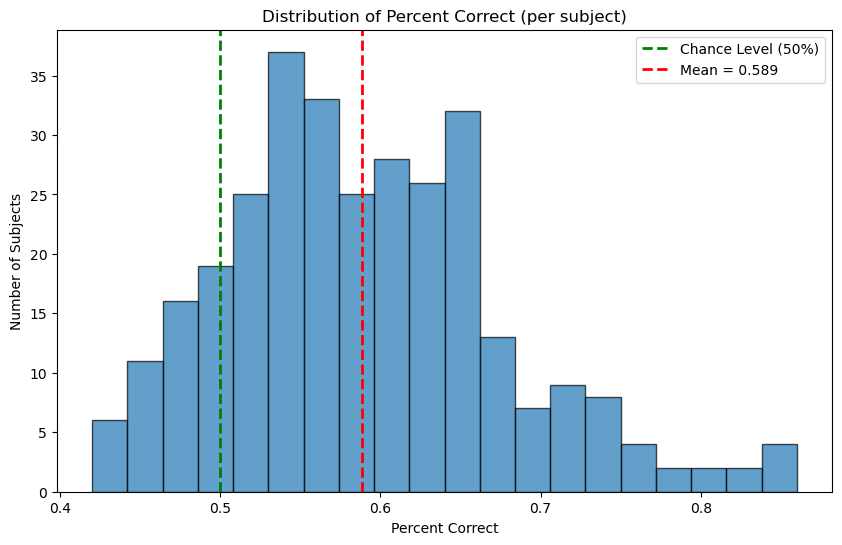

In [10]:
# Distribution of percent correct across subjects
plt.figure(figsize=(10, 6))
plt.hist(percent_cor_IDs['cor_ans'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0.5, color='green', linestyle='dashed', linewidth=2, label='Chance Level (50%)')
plt.axvline(percent_cor_IDs['cor_ans'].mean(), color='red', 
            linestyle='dashed', linewidth=2, label=f'Mean = {percent_cor_IDs["cor_ans"].mean():.3f}')
plt.xlabel("Percent Correct")
plt.ylabel("Number of Subjects")
plt.title("Distribution of Percent Correct (per subject)")
plt.legend()
plt.show()

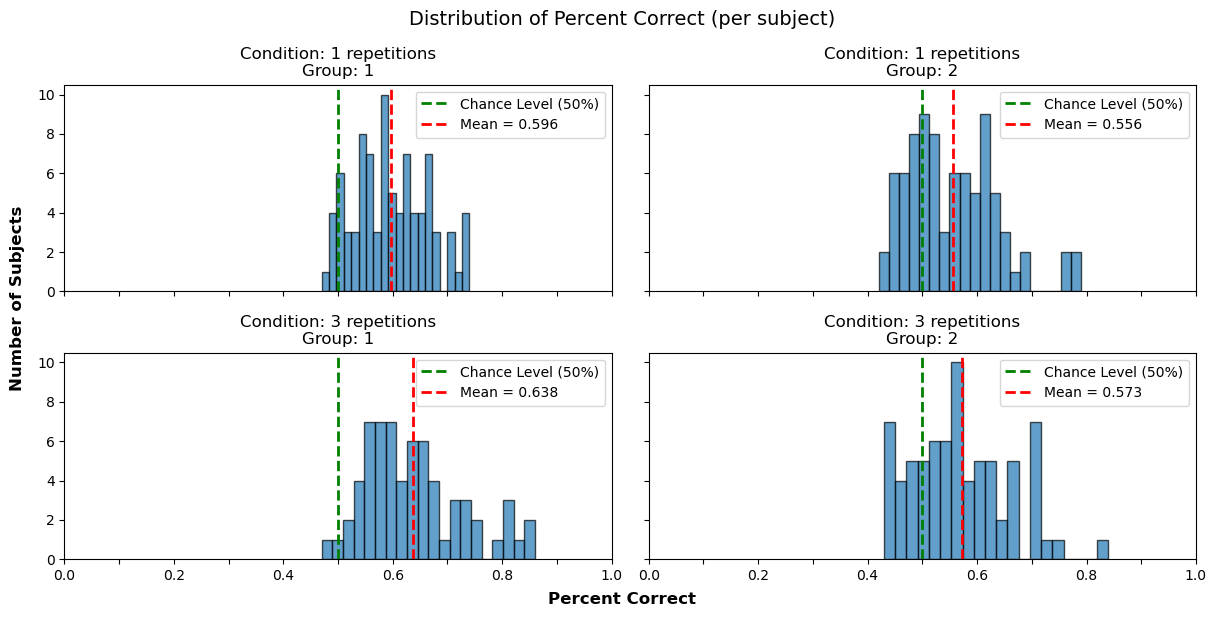

In [11]:
# Distribution of percent correct across subjects
# by groups
groups = np.tile(np.sort(percent_cor_IDs["group"].unique()), 2)
conds = np.repeat(
    np.sort(percent_cor_IDs["condition"].unique()), 
    2)
fig, axes = plt.subplots(2,2, # rows, cols
                         figsize=(12, 6), 
                         sharey=True,sharex=True # share x and y axis scales
                         )
axes = axes.ravel()

for ax, g, cond in zip(axes, groups, conds):
    data = percent_cor_IDs.loc[(percent_cor_IDs["group"] == g) & (percent_cor_IDs["condition"] == cond), "cor_ans"]
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(.50, color="green", linestyle="dashed", linewidth=2, label="Chance Level (50%)")
    # Group mean
    ax.axvline(data.mean(), color="red", linestyle="dashed", linewidth=2, label=f"Mean = {data.mean():.3f}")
    
    ax.set_title(f"Condition: {cond.split('_')[0]} repetitions\nGroup: {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    ax.set_xlim(0,1)
    ax.set_xticks(np.arange(0, 1.1, 0.1))
    ax.set_xticklabels([f"{x:.1f}" if i % 2 == 0 else '' for i, x in enumerate(np.arange(0, 1.1, 0.1))])
    ax.legend()


fig.text(-0.01, 0.5, 'Number of Subjects', va='center', rotation='vertical', fontsize=12, fontweight='bold')
fig.text(0.5, -0.01, 'Percent Correct', ha='center', fontsize=12, fontweight='bold')
fig.suptitle("Distribution of Percent Correct (per subject)", fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
# Get unique subject IDs from data
all_IDs = data_test['subject_id'].unique()

# Compute difference
# not_credited_yet = [id for id in all_IDs if id not in credited_IDs]

# print(not_credited_yet)

In [13]:
# len(not_credited_yet) # Number of subjects not credited yet

In [14]:
# credited_IDs = data_test['subject_id'].unique()

In [15]:
# credited_IDs

In [16]:
# # IDs who completed the experiment more than once
# ID_trial_count = data_test['subject_id'].value_counts()
# (ID_trial_count
#  .index[ np.where( ID_trial_count.values > 100 ) ] # IDs with more than 100 trials
#  .tolist() # more readable format
#  )

In [17]:
# N per condition/group (before filters!)
data_test \
    .groupby(['condition','group'], observed=True, as_index=False)['subject_id'] \
    .nunique()

,condition,group,subject_id
0,1_Rep,Group1,87
1,1_Rep,Group2,83
2,3_Rep,Group1,65
3,3_Rep,Group2,74


In [18]:
# N total (before filters!)
data_test['subject_id'].nunique()

309

# d' by ID

Calculate d' with adjustments (for both hits and false alarms Macmillan & Kaplan, 1985), so that if there is a perfect (1) or terrible (0) hit, or fa, we still got a value (not infinity):
$$\text{Hit} = \frac{N_{hits} + 0.5}{N_{signal\_trials} + 1}$$

Same for FAs.

In [19]:
# Compute hits and number of signal trials per subject
hits_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Target']
    .groupby('subject_id', observed=True)
    .agg(
        hits=('cor_ans', 'sum'),
        signal_trials=('cor_ans', 'count')
    )
    .reset_index()
)

# Compute unadjusted hit rate
hits_IDs['Hit_rate'] = hits_IDs['hits'] / hits_IDs['signal_trials']

# Apply Macmillan & Kaplan (1985) correction
hits_IDs['Hit_rate_adj'] = (hits_IDs['hits'] + 0.5) / (hits_IDs['signal_trials'] + 1)
hits_IDs

,subject_id,hits,signal_trials,Hit_rate,Hit_rate_adj
0,90596,29,50,0.58,0.578431
1,90597,35,50,0.70,0.696078
2,90605,30,50,0.60,0.598039
3,90626,25,50,0.50,0.500000
4,90630,25,50,0.50,0.500000
...,...,...,...,...,...
304,93059,28,50,0.56,0.558824
305,93067,36,50,0.72,0.715686
306,93073,28,50,0.56,0.558824
307,93082,34,50,0.68,0.676471


In [20]:
# Compute false alarms and number of noise trials per subject
fa_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Foil']
    .groupby('subject_id', observed=True)
    .agg(
        # Count "l" responses as false alarms
        FA=('response', lambda x: (x == 'l').sum()),
        noise_trials=('response', 'count')
    )
    .reset_index()
)

# Compute unadjusted false alarm rate
fa_IDs['FA_rate'] = fa_IDs['FA'] / fa_IDs['noise_trials']

# Apply Macmillan & Kaplan (1985) correction
fa_IDs['FA_rate_adj'] = (fa_IDs['FA'] + 0.5) / (fa_IDs['noise_trials'] + 1)

fa_IDs

,subject_id,FA,noise_trials,FA_rate,FA_rate_adj
0,90596,31,50,0.62,0.617647
1,90597,27,50,0.54,0.539216
2,90605,16,50,0.32,0.323529
3,90626,26,50,0.52,0.519608
4,90630,26,50,0.52,0.519608
...,...,...,...,...,...
304,93059,21,50,0.42,0.421569
305,93067,30,50,0.60,0.598039
306,93073,18,50,0.36,0.362745
307,93082,19,50,0.38,0.382353


In [21]:
# Calculate d'
dprime_ID = pd.merge(hits_IDs, fa_IDs, on='subject_id')
dprime_ID['dprimes'] = [stats.norm.ppf(hit) - stats.norm.ppf( (fa) ) 
  for hit, fa 
  in zip(dprime_ID['Hit_rate_adj'], dprime_ID['FA_rate_adj'])
  ]

# Drop columns
dprime_ID = (dprime_ID
 .drop( columns={'hits', 'signal_trials', 'Hit_rate', 'FA', 'noise_trials', 'FA_rate'})
 .rename(columns = {'Hit_rate_adj':'Hit_rate',
                    'FA_rate_adj':'FA_rate'})
 )

dprime_ID

,subject_id,Hit_rate,FA_rate,dprimes
0,90596,0.578431,0.617647,-0.101425
1,90597,0.696078,0.539216,0.414697
2,90605,0.598039,0.323529,0.706127
3,90626,0.500000,0.519608,-0.049169
4,90630,0.500000,0.519608,-0.049169
...,...,...,...,...
304,93059,0.558824,0.421569,0.345869
305,93067,0.715686,0.598039,0.321799
306,93073,0.558824,0.362745,0.499118
307,93082,0.676471,0.382353,0.757159


In [22]:
# Add groups and conditions from percent_cor_IDs
dprime_ID = pd.merge(
    dprime_ID, 
    percent_cor_IDs[['subject_id','group','condition']], 
    on='subject_id'
    )
dprime_ID

,subject_id,Hit_rate,FA_rate,dprimes,group,condition
0,90596,0.578431,0.617647,-0.101425,Group2,1_Rep
1,90597,0.696078,0.539216,0.414697,Group1,1_Rep
2,90605,0.598039,0.323529,0.706127,Group1,3_Rep
3,90626,0.500000,0.519608,-0.049169,Group1,1_Rep
4,90630,0.500000,0.519608,-0.049169,Group2,1_Rep
...,...,...,...,...,...,...
304,93059,0.558824,0.421569,0.345869,Group1,3_Rep
305,93067,0.715686,0.598039,0.321799,Group1,3_Rep
306,93073,0.558824,0.362745,0.499118,Group2,1_Rep
307,93082,0.676471,0.382353,0.757159,Group2,1_Rep


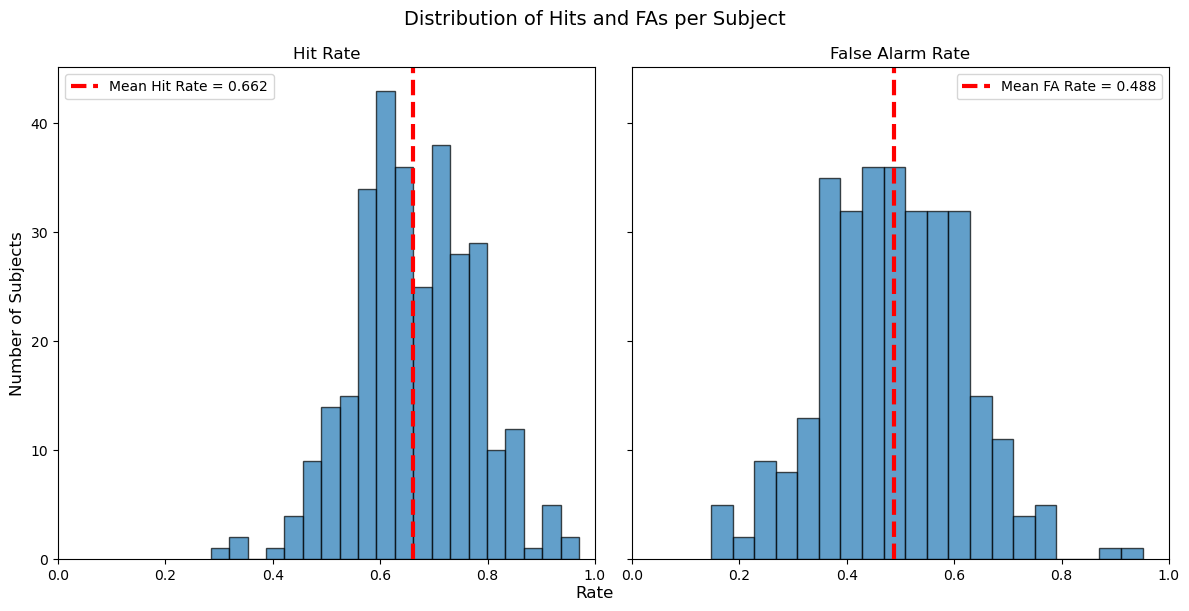

In [23]:
# Hits and FAs distribution (before filtering!)
fig, axes = plt.subplots(1, 2, # rows, cols
                         figsize=(12, 6), 
                         sharey=True,sharex=True # share x and y axis scales
                         )


axes[0].hist(dprime_ID['Hit_rate'], bins=20, edgecolor="black", alpha=0.7)
axes[1].hist(dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)

axes[0].set_xlim(0, 1)

# Mean
axes[0].axvline(dprime_ID['Hit_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean Hit Rate = {dprime_ID['Hit_rate'].mean():.3f}")
axes[1].axvline(dprime_ID['FA_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean FA Rate = {dprime_ID['FA_rate'].mean():.3f}")

axes[0].set_title("Hit Rate")
axes[1].set_title("False Alarm Rate") 

fig.text(0.5, 0, "Rate", ha="center", fontsize=12)

axes[0].legend()
axes[1].legend()

axes[0].set_ylabel("Number of Subjects", fontsize=12)
fig.suptitle("Distribution of Hits and FAs per Subject", fontsize=14)
plt.tight_layout()
plt.show()

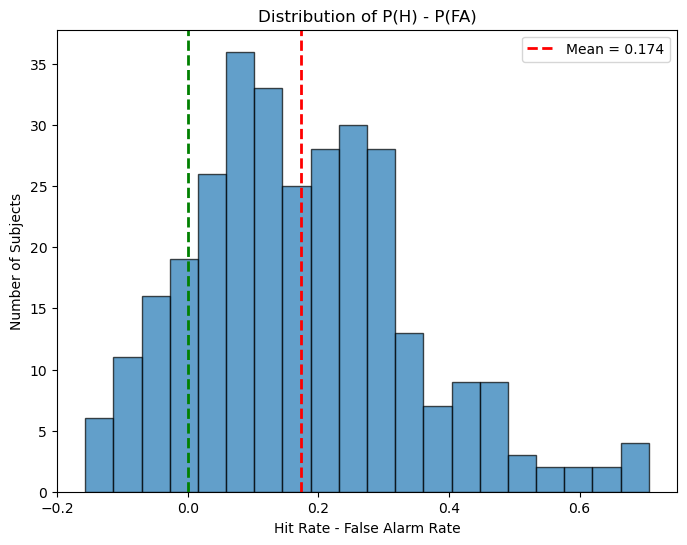

In [24]:
# p(H) - p(FA)
plt.figure(figsize=(8, 6))
plt.hist(dprime_ID['Hit_rate'] - dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0, color='green', linestyle='dashed', linewidth=2)
plt.axvline((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']).mean(), 
            color='red', linestyle='dashed', linewidth=2,
            label=f'Mean = {(dprime_ID["Hit_rate"] - dprime_ID["FA_rate"]).mean():.3f}')
plt.xlabel("Hit Rate - False Alarm Rate")
plt.ylabel("Number of Subjects")
plt.title("Distribution of P(H) - P(FA)")
plt.legend()
plt.show()

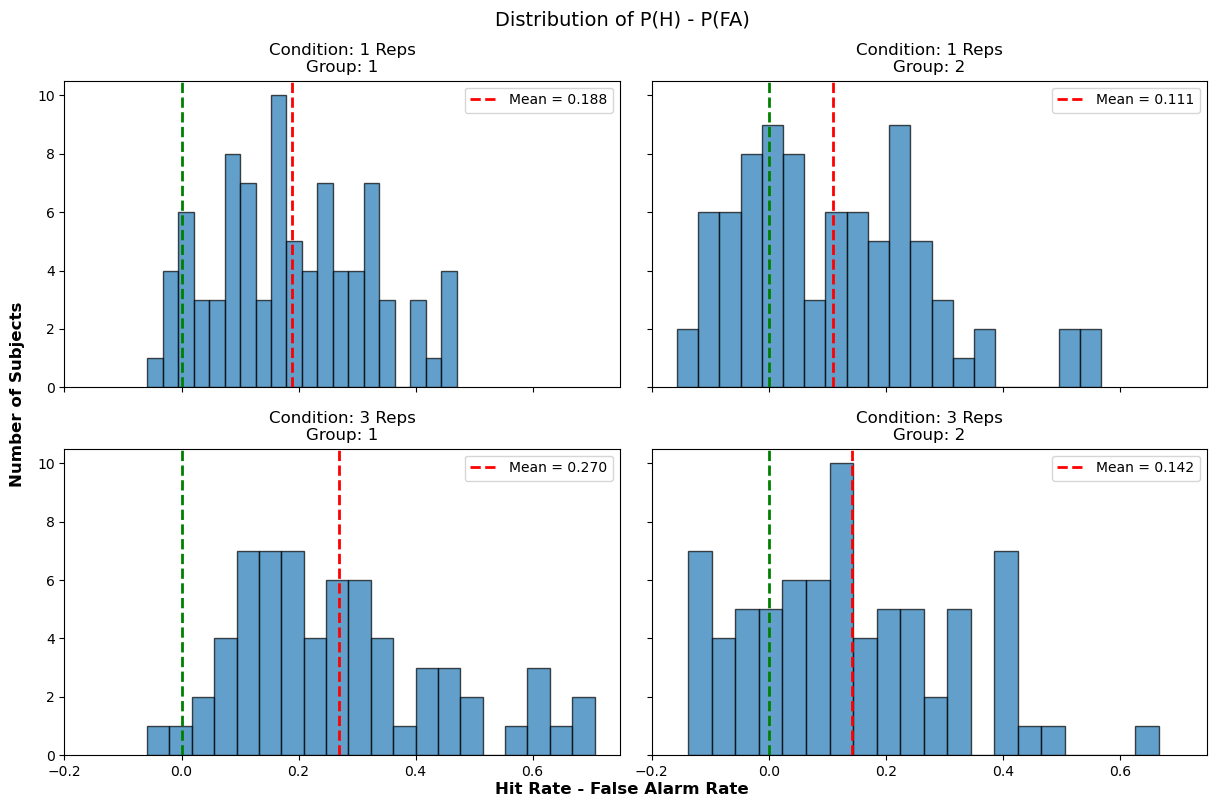

In [25]:
# p(H) - p(FA) plot by group and condition (before filtering!)
groups = np.tile(np.sort(dprime_ID['group'].unique()), 2)
conds = np.repeat(np.sort(dprime_ID['condition'].unique()), 2)

fig, axes = plt.subplots(2, 2, # rows, cols
                         figsize=(12, 8),
                         sharex=True, sharey=True # share x and y axis scales
                         )
axes = axes.ravel()
for ax, g, cond in zip(axes, groups, conds):
    data = (
        dprime_ID.loc[(dprime_ID['group'] == g) & (dprime_ID['condition'] == cond), 'Hit_rate'] - 
        dprime_ID.loc[(dprime_ID['group'] == g) & (dprime_ID['condition'] == cond), 'FA_rate']
        )
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(0, color='green', linestyle='dashed', linewidth=2)
    # Group & Condition mean
    ax.axvline(data.mean(), color='red', linestyle='dashed', linewidth=2,
               label=f'Mean = {data.mean():.3f}')
    
    ax.set_title(f"Condition: {cond[0]} Reps\nGroup: {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    #ax.set_xlabel("Hit Rate - False Alarm Rate")
    ax.legend()

fig.text(0.5, 0, "Hit Rate - False Alarm Rate", ha="center", fontsize=12, fontweight='bold')
fig.text(-0.01, 0.5, 'Number of Subjects', va='center', rotation='vertical', fontsize=12, fontweight='bold')
fig.suptitle("Distribution of P(H) - P(FA)", fontsize=14)
plt.tight_layout()
plt.show()

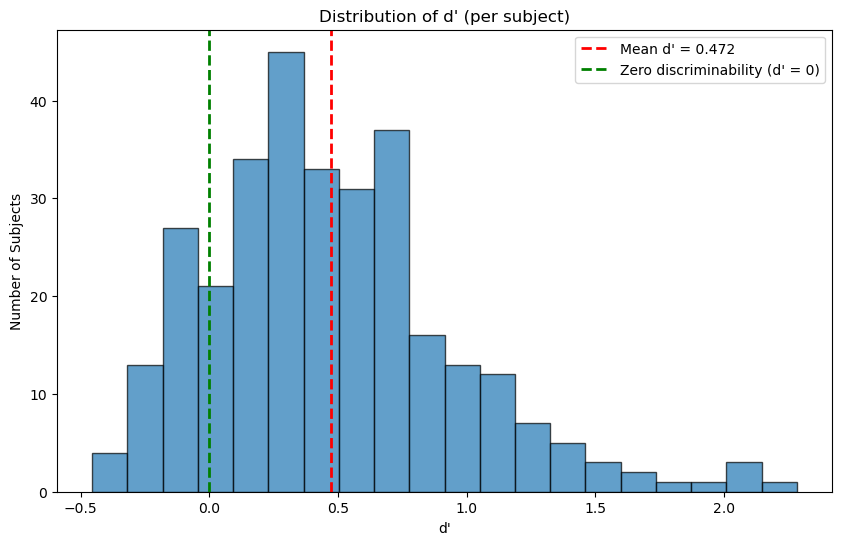

In [26]:
# d' (before filtering!)
plt.figure(figsize=(10, 6))
plt.hist(dprime_ID['dprimes'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(np.mean(dprime_ID['dprimes']), color='red', linestyle='dashed', linewidth=2, label=f'Mean d\' = {np.mean(dprime_ID["dprimes"]):.3f}')
plt.axvline(0, color='green', linestyle='dashed', linewidth=2, label="Zero discriminability (d' = 0)")
plt.xlabel("d'")
plt.ylabel("Number of Subjects")
plt.title("Distribution of d' (per subject)")
plt.legend()
plt.show()

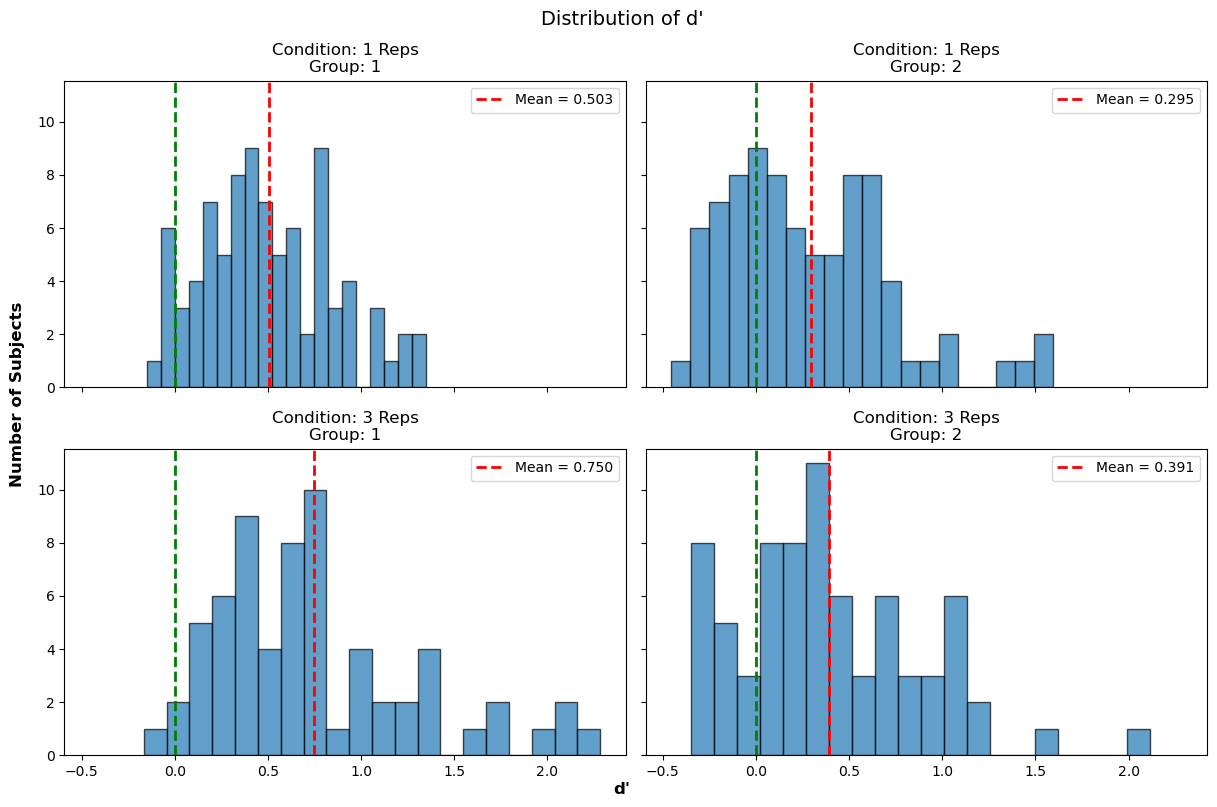

In [27]:
# d' plot by group and condition (before filtering!)
groups = np.tile(np.sort(dprime_ID['group'].unique()), 2)
conds = np.repeat(np.sort(dprime_ID['condition'].unique()), 2)

fig, axes = plt.subplots(2, 2, # rows, cols
                         figsize=(12, 8),
                         sharex=True, sharey=True # share x and y axis scales
                         )
axes = axes.ravel()
for ax, g, cond in zip(axes, groups, conds):
    data = dprime_ID.loc[(dprime_ID['group'] == g) & (dprime_ID['condition'] == cond), 'dprimes']
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(0, color='green', linestyle='dashed', linewidth=2)
    # Group & Condition mean
    ax.axvline(data.mean(), color='red', linestyle='dashed', linewidth=2,
               label=f'Mean = {data.mean():.3f}')
    
    ax.set_title(f"Condition: {cond[0]} Reps\nGroup: {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    #ax.set_xlabel("Hit Rate - False Alarm Rate")
    ax.legend()

fig.text(0.5, 0, "d'", ha="center", fontsize=12, fontweight='bold')
fig.text(-0.01, 0.5, 'Number of Subjects', va='center', rotation='vertical', fontsize=12, fontweight='bold')
fig.suptitle("Distribution of d'", fontsize=14)
plt.tight_layout()
plt.show()

## Filter by Hit - FA

In [28]:
# Conditional thresholds for both conditions and groups
threshold_by_cond = (
    (dprime_ID['Hit_rate'] - dprime_ID['FA_rate'])
    .groupby([dprime_ID['condition'], dprime_ID['group']], observed=True)
    .quantile(0.25) # top 75% of subjects in each condition/group
)
threshold_by_cond = np.maximum(threshold_by_cond,0) # make sure thresholds are not negative

# thresholds are:
print(f'Thresholds are:')
for idx, val in threshold_by_cond.items():
    print(f'  {idx}: {val:.3f}')

conditions = [
    (dprime_ID['condition'] == '1_Rep') & (dprime_ID['group'] == 'Group1') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('1_Rep','Group1')]),
    
    (dprime_ID['condition'] == '1_Rep') & (dprime_ID['group'] == 'Group2') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('1_Rep','Group2')]),
    
    (dprime_ID['condition'] == '3_Rep') & (dprime_ID['group'] == 'Group1') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('3_Rep','Group1')]),
    
    (dprime_ID['condition'] == '3_Rep') & (dprime_ID['group'] == 'Group2') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('3_Rep','Group2')]),
]
choices = [True, True, True, True] # conditions are for good subjects, so defaule is False (next line)

dprime_ID['good_subj'] = np.select(conditions, choices, default=False)
bad_subjects = dprime_ID.loc[dprime_ID['good_subj'] == False,'subject_id'].tolist()

Thresholds are:
  ('1_Rep', 'Group1'): 0.088
  ('1_Rep', 'Group2'): 0.000
  ('3_Rep', 'Group1'): 0.137
  ('3_Rep', 'Group2'): 0.020


In [29]:
# Add column good_subj (filter by Hit - FA)
data_test = (pd.merge(data_test, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )
data_memory = (pd.merge(data_memory, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )

In [30]:
# save filtered data
filtered_data_test = data_test[data_test['good_subj'] == True].copy().reset_index(drop=True)
filtered_data_memory = data_memory[data_memory['good_subj'] == True].copy().reset_index(drop=True)

In [31]:
# N good subjects
(filtered_data_test
 .groupby(['condition','group'], observed=True)['subject_id']
 .nunique()
 .reset_index(name='N_subj')
 )

,condition,group,N_subj
0,1_Rep,Group1,65
1,1_Rep,Group2,61
2,3_Rep,Group1,50
3,3_Rep,Group2,56


In [32]:
# Total N good subjects
print(f"Total number of good subjects: {filtered_data_test['subject_id'].nunique()}")
print(f"Total number of all subjects: {data_test['subject_id'].nunique()}")
print(f"Proportion of good subjects: {filtered_data_test['subject_id'].nunique() / data_test['subject_id'].nunique():.3f}")

Total number of good subjects: 232
Total number of all subjects: 309
Proportion of good subjects: 0.751


# d' by item

In [33]:
# Proportion Yes by image_id
df_by_item = (filtered_data_test
            .groupby(['image_id','condition','group'], observed=True)
            .agg(n_subj=('cor_ans', 'size'),
                n_yes=('response', lambda x: (x == "l").sum()),
                item_type=('item_type', 'first'),
                category_name=('category_name', 'first'),
                distinct_rating=('distinct_rating', 'first'),
                distinct_type=('distinct_type', 'first') 
                )
            .reset_index()
            .assign(prop_yes=lambda df: (df['n_yes']+0.5) / (df['n_subj']+1), # Apply Macmillan & Kaplan (1985) correction
                    resp_type = lambda df: np.where(df['item_type'] == 'Target', 'Hit', 'FA')
                    )
            )
df_by_item

,image_id,condition,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type
0,3,1_Rep,Group1,65,20,Foil,Andesite,3.17,Bottom,0.310606,FA
1,3,1_Rep,Group2,61,32,Target,Andesite,3.17,Bottom,0.524194,Hit
2,3,3_Rep,Group1,50,14,Foil,Andesite,3.17,Bottom,0.284314,FA
3,3,3_Rep,Group2,56,28,Target,Andesite,3.17,Bottom,0.500000,Hit
4,4,1_Rep,Group1,65,37,Foil,Andesite,3.18,Bottom,0.568182,FA
...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,56,14,Foil,Shale,2.55,Bottom,0.254386,FA
396,476,1_Rep,Group1,65,46,Target,Shale,2.48,Bottom,0.704545,Hit
397,476,1_Rep,Group2,61,32,Foil,Shale,2.48,Bottom,0.524194,FA
398,476,3_Rep,Group1,50,40,Target,Shale,2.48,Bottom,0.794118,Hit


In [34]:
# Wide format with H and FAs for each image_id
df_by_item_wide = df_by_item.pivot(index=["image_id","condition"], 
                                   columns="resp_type", 
                                   values="prop_yes").reset_index()
df_by_item_wide

resp_type,image_id,condition,FA,Hit
0,3,1_Rep,0.310606,0.524194
1,3,3_Rep,0.284314,0.500000
2,4,1_Rep,0.568182,0.556452
3,4,3_Rep,0.460784,0.447368
4,6,1_Rep,0.556452,0.734848
...,...,...,...,...
195,471,3_Rep,0.421569,0.675439
196,472,1_Rep,0.362903,0.598485
197,472,3_Rep,0.254386,0.480392
198,476,1_Rep,0.524194,0.704545


In [35]:
# convert resp_type to categorical
df_by_item['resp_type'] = df_by_item['resp_type'].astype('category')

## LM: H and FAs ~ cond*distinct

In [4]:
df_by_item

,image_id,condition,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type,HS_preds,HS_pooled_groups_preds,Base_preds
0,3,1_Rep,Group1,65,20,Foil,Andesite,3.17,Bottom,0.310606,FA,0.500815,0.516068,0.526467
1,3,1_Rep,Group2,61,32,Target,Andesite,3.17,Bottom,0.524194,Hit,0.658036,0.641501,0.666133
2,3,3_Rep,Group1,50,14,Foil,Andesite,3.17,Bottom,0.284314,FA,0.469553,0.511542,0.483219
3,3,3_Rep,Group2,56,28,Target,Andesite,3.17,Bottom,0.500000,Hit,0.687004,0.688549,0.708823
4,4,1_Rep,Group1,65,37,Foil,Andesite,3.18,Bottom,0.568182,FA,0.485232,0.488979,0.456106
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,56,14,Foil,Shale,2.55,Bottom,0.254386,FA,0.509505,0.467164,0.490361
396,476,1_Rep,Group1,65,46,Target,Shale,2.48,Bottom,0.704545,Hit,0.651839,0.661792,0.680382
397,476,1_Rep,Group2,61,32,Foil,Shale,2.48,Bottom,0.524194,FA,0.541247,0.541082,0.542546
398,476,3_Rep,Group1,50,40,Target,Shale,2.48,Bottom,0.794118,Hit,0.685102,0.690038,0.718601


In [36]:
# Linear regression
m1 = smf.ols(
    "prop_yes ~ condition * distinct_type * resp_type",
    data=df_by_item
    ) \
    .fit(cov_type='HC3') # hc3 - heteroscedasticity-corrected coefficient covariance matrix

anova_lm(m1, typ = 2).round(3) # ANOVA table with type II sums of squares

,sum_sq,df,F,PR(>F)
condition,0.083,1.0,5.238,0.023
distinct_type,2.562,1.0,161.621,0.000
resp_type,9.244,1.0,583.145,0.000
condition:distinct_type,0.101,1.0,6.358,0.012
condition:resp_type,0.126,1.0,7.957,0.005
distinct_type:resp_type,3.796,1.0,239.458,0.000
condition:distinct_type:resp_type,0.026,1.0,1.659,0.199
Residual,6.214,392.0,NaN,NaN


In [37]:
# LM-like summary
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:               prop_yes   R-squared:                       0.607
Model:                            OLS   Adj. R-squared:                  0.600
Method:                 Least Squares   F-statistic:                     182.8
Date:                Thu, 30 Jul 2026   Prob (F-statistic):          3.07e-119
Time:                        22:15:15   Log-Likelihood:                 265.36
No. Observations:                 400   AIC:                            -514.7
Df Residuals:                     392   BIC:                            -482.8
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

**Post-hoc Comparisons**

Contrasts:

- For Hits: 
    * 1 vs 3 (low)
    * 1 vs 3 (high)
    * low vs high (1)
    * low vs high (3)

- Similarly for FAs:
    * 1 vs 3 (low)
    * 1 vs 3 (high)
    * low vs high (1)
    * low vs high (3)

Regular formula to calculate t-statistics:

$SE = \sqrt{MSE \cdot \sum_i \frac{w_i^2}{n_i}}$, where $MSE = \frac{SS_{residual}}{df_{residual}}$, and $df = df_{residual}$. Then $t = \frac{\text{Contrast}_i \cdot w_i}{SE}$. And finally, calculate p-value using df from the model (ANOVA), in our case $df_{residual} = 400 - 8 = 392$.

But when we try to account for **different variances across groups of comparison**, we need to use Welch's t-test (unequal variance t-test):

$$SE = \sqrt{\sum_i \frac{w_i^2 s_i^2}{n_i}}$$

$$df = \frac{\left(\sum_i \frac{w_i^2 s_i^2}{n_i}\right)^2}{\sum_i \frac{\left(\frac{w_i^2 s_i^2}{n_i}\right)^2}{n_i - 1}}$$

In [38]:
# ========== Bonferroni-corrected post hoc contrasts (account for different variances) ==========
anova_table = anova_lm(m1, typ = 2)
mse = anova_table['sum_sq']['Residual'] / anova_table['df']['Residual']

# Get group means
group_means = df_by_item.groupby(['condition','distinct_type','resp_type'], observed=True)['prop_yes'].mean()
group_vars = df_by_item.groupby(['condition','distinct_type','resp_type'], observed=True)['prop_yes'].var() # need to account for different variances across groups
n = df_by_item.groupby(['condition','distinct_type','resp_type'], observed=True).size() # Sample sizes

# Manually specify contrasts based on the means and MSE from the ANOVA
contrasts = {
    # ========== Hits ==========
    'Low hits 1 rep vs 3 rep': (0, 1, 0, 0,
                                0, -1, 0, 0),
    'High hits 1 rep vs 3 rep': (0, 0, 0, 1,
                                 0, 0, 0, -1),
    'Low vs high hits (1 rep)': (0, 1, 0, -1,
                                 0, 0, 0, 0),
    'Low vs high hits (3 rep)': (0, 0, 0, 0,
                                 0, 1, 0, -1),
    # ========== FAs ==========
    'Low FAs 1 rep vs 3 rep': (1, 0, 0, 0,
                               -1, 0, 0, 0),
    'High FAs 1 rep vs 3 rep': (0, 0, 1, 0,
                                0, 0, -1, 0),
    'Low vs high FAs (1 rep)': (1, 0, -1, 0,
                                0, 0, 0, 0),
    'Low vs high FAs (3 rep)': (0, 0, 0, 0,
                                1, 0, -1, 0),
}

contrasts_results = {}
n_comparison = len(contrasts)

for contrast_name, weights in contrasts.items():
    weights = np.array(weights)
    contrast_estimate = weights @ group_means
    
    # Per-group variance contribution
    var_terms = (weights**2) * (group_vars / n) # account for different variances and sample sizes
    se = np.sqrt(var_terms.sum())
    
    # Welch-Satterthwaite degrees of freedom
    df_ws = var_terms.sum()**2 / ((var_terms**2) / (n - 1)).sum()
    
    t_stat = contrast_estimate / se
    p_value = 2 * stats.t.sf(np.abs(t_stat), df=df_ws)
    p_adjusted = min(p_value * n_comparison, 1.0)
    sig = "***" if p_adjusted < 0.001 else "**" if p_adjusted < 0.01 else "*" if p_adjusted < 0.05 else ""
    
    contrasts_results[contrast_name] = {
        'estimate': contrast_estimate,
        't_stat': t_stat,
        'df': df_ws,          # will vary per contrast now
        'p_value': p_value,
        'p_adjusted': p_adjusted,
        'significance': sig
    }

# Print results in a table format
m1_posthoc_df = pd.DataFrame(contrasts_results).T
num_cols = ['estimate', 't_stat', 'p_value', 'p_adjusted']
m1_posthoc_df[num_cols] = m1_posthoc_df[num_cols].astype(float)
m1_posthoc_df = m1_posthoc_df.round(3)
m1_posthoc_df

,estimate,t_stat,df,p_value,p_adjusted,significance
Low hits 1 rep vs 3 rep,-0.030,-1.754,164.774836,0.081,0.650,
High hits 1 rep vs 3 rep,-0.135,-3.935,28.073934,0.000,0.004,**
Low vs high hits (1 rep),0.003,0.099,21.976806,0.922,1.000,
Low vs high hits (3 rep),-0.102,-4.273,25.299982,0.000,0.002,**
Low FAs 1 rep vs 3 rep,0.019,0.810,163.121276,0.419,1.000,
High FAs 1 rep vs 3 rep,-0.017,-0.611,28.614111,0.546,1.000,
Low vs high FAs (1 rep),0.383,16.711,43.010455,0.000,0.000,***
Low vs high FAs (3 rep),0.347,12.589,38.155228,0.000,0.000,***


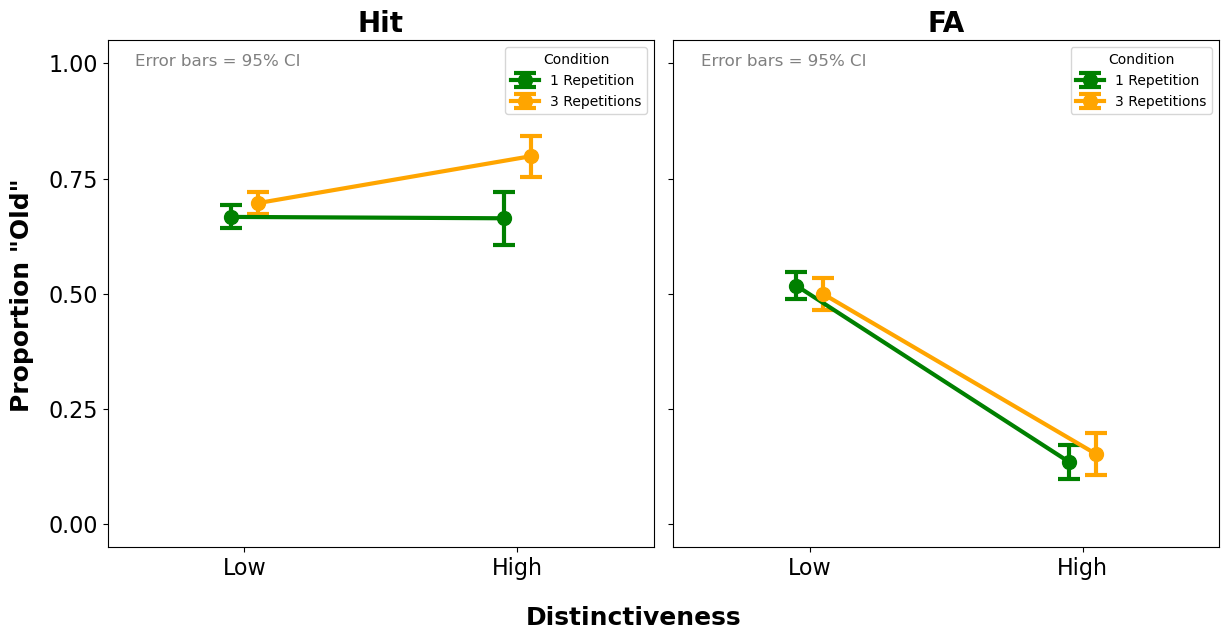

In [39]:
# Plot 
# Summary stats for plotting
summary = (
    df_by_item
    .groupby(["condition", "resp_type", "distinct_type"], observed=False)
    .agg(
        mean_prop=("prop_yes", "mean"),
        n=("prop_yes", "size"),
        sd=("prop_yes", "std")
    )
    .reset_index()
)
summary["se"] = summary["sd"] / np.sqrt(summary["n"])
summary["ci95"] = summary["se"] * stats.t.ppf(0.975, summary["n"] - 1)


fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

resp_levels = ["Hit", "FA"]
conditions = sorted(df_by_item["condition"].unique())
x_levels = sorted(df_by_item["distinct_type"].unique())
x_pos = np.arange(len(x_levels))

# color
color_map = {
    "1_Rep": "green",
    "3_Rep": "orange"
}
condition_label_map = {
    "1_Rep": "1 Repetition",
    "3_Rep": "3 Repetitions"
}
# slighly to the left/right from the center of the x-ticks
offset_map = {
    "1_Rep": -0.05,
    "3_Rep":  0.05
}
x_label_map = {
    "Bottom": "Low",
    "Top": "High"
}

for ax, resp in zip(axes, resp_levels):

    for cond in conditions:
        summ = summary[
            (summary["resp_type"] == resp) &
            (summary["condition"] == cond)
        ]

        means = []
        cis = []

        for lvl in x_levels:
            row = summ[summ["distinct_type"] == lvl].iloc[0]
            means.append(row["mean_prop"])
            cis.append(row["ci95"])

        ax.errorbar(
            x_pos + offset_map[cond], # offset for visibility
            means,
            yerr=cis,
            fmt="o-", # o means draw the mean circle, - means connect with line
            capthick=3, # 
            capsize=8,
            linewidth=3,
            markersize=10,
            color=color_map[cond],
            label=condition_label_map[cond]
        )

    ax.set_title(resp, fontsize=20, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels([x_label_map[lvl] for lvl in x_levels], fontsize=16)
    ax.set_xlim(-0.5, len(x_levels) - 0.5)
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.25))
    ax.tick_params(axis="both", labelsize=16)
    ax.text(0.05, 0.95, f'Error bars = 95% CI', transform=ax.transAxes, fontsize=12, color='gray')
    ax.legend(title="Condition")

fig.text(-0.02, 0.5, 'Proportion "Old"', va="center",
         rotation="vertical", fontsize=18, fontweight="bold")
fig.text(0.5, -0.05, "Distinctiveness", ha="center",
         fontsize=18, fontweight="bold")

plt.tight_layout()
plt.show()

# Split-Half

In [40]:
# add response types to filtered_data_test
conditions = [
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == False),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == False),
]

choices = ['Hit', 'Miss', 'CR', 'FA']

filtered_data_test['resp_type'] = np.select(conditions, choices, default=None)
filtered_data_test

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,good_subj,resp_type
0,311,91746,Group2,3_Rep,test_phase,Target,l,l,True,1776.0,Gneiss,13,M,M_Gneiss_15.png,207,3.11,Bottom,True,Hit
1,313,91746,Group2,3_Rep,test_phase,Target,l,l,True,767.0,Rock Salt,28,S,S_Rock Salt_13.png,445,7.58,Top,True,Hit
2,315,91746,Group2,3_Rep,test_phase,Target,l,l,True,779.0,Pegmatite,7,I,I_Pegmatite_03.png,99,7.24,Top,True,Hit
3,317,91746,Group2,3_Rep,test_phase,Target,l,l,True,805.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit
4,319,91746,Group2,3_Rep,test_phase,Foil,a,a,True,924.0,Rhyolite,10,I,I_Rhyolite_16.png,160,2.19,Bottom,True,CR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23195,501,92625,Group2,3_Rep,test_phase,Foil,a,a,True,1088.0,Obsidian,6,I,I_Obsidian_05.png,85,7.32,Top,True,CR
23196,503,92625,Group2,3_Rep,test_phase,Target,l,l,True,815.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit
23197,505,92625,Group2,3_Rep,test_phase,Foil,l,a,False,1000.0,Marble,15,M,M_Marble_04.png,228,3.15,Bottom,True,FA
23198,507,92625,Group2,3_Rep,test_phase,Target,l,l,True,683.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom,True,Hit


In [41]:
# ---------- Hits data for split-half reliability analysis ----------

# ---------- 1 Rep ----------

# ---------- Group 1 ----------

sh_df_hits_1rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_1rep_gr1_long['is_hit'] = np.where(sh_df_hits_1rep_gr1_long['resp_type']=='Hit', 1, 0)  # is hit or miss
sh_df_hits_1rep_gr1_long = sh_df_hits_1rep_gr1_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_1rep_gr1 = sh_df_hits_1rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_hit')


# ---------- Group 2 ----------

sh_df_hits_1rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_1rep_gr2_long['is_hit'] = np.where(sh_df_hits_1rep_gr2_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_1rep_gr2_long = sh_df_hits_1rep_gr2_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_1rep_gr2 = sh_df_hits_1rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_hit')


# ---------- 3 Rep ----------

# ---------- Group 1 ----------

sh_df_hits_3rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_3rep_gr1_long['is_hit'] = np.where(sh_df_hits_3rep_gr1_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_3rep_gr1_long = sh_df_hits_3rep_gr1_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_3rep_gr1 = sh_df_hits_3rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_hit')

# ---------- Group 2 ----------

sh_df_hits_3rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_3rep_gr2_long['is_hit'] = np.where(sh_df_hits_3rep_gr2_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_3rep_gr2_long = sh_df_hits_3rep_gr2_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_3rep_gr2 = sh_df_hits_3rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_hit')

In [42]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for hit, 0 for miss
sh_df_hits_3rep_gr2.head(10)

subject_id,91746,92208,91155,90707,91388,90950,92523,91224,91916,92252,...,90838,92458,91551,91813,92629,90680,91557,90645,91955,92625
image_id,,,,,,,,,,,,,,,,,,,,,
3,0,1,0,1,1,1,0,0,1,0,...,0,1,0,1,0,1,1,1,0,0
4,1,1,0,1,1,0,1,1,0,0,...,0,1,0,0,1,0,1,0,0,1
9,1,1,1,1,1,1,1,1,1,1,...,1,1,0,0,1,1,1,0,1,1
24,1,0,1,0,1,1,1,1,0,0,...,1,1,1,0,1,1,1,1,0,1
26,0,1,1,1,1,1,0,1,1,0,...,1,1,0,1,0,0,1,1,1,1
29,0,1,1,1,0,1,1,1,1,1,...,1,1,1,1,0,1,0,1,1,0
33,1,1,1,1,0,1,1,1,1,1,...,0,1,0,1,0,1,1,1,0,0
42,0,1,0,1,1,1,0,1,1,1,...,0,1,1,0,1,1,1,1,0,0
47,1,1,0,1,1,1,1,1,1,1,...,1,1,1,0,1,1,0,1,1,1


In [43]:
# ---------- FA data for split-half reliability analysis ----------


# ---------- 1 Rep ----------

# ---------- Group 1 ----------

sh_df_fa_1rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_1rep_gr1_long['is_fa'] = np.where(sh_df_fa_1rep_gr1_long['resp_type']=='FA', 1, 0)  # is fa or cr
sh_df_fa_1rep_gr1_long
sh_df_fa_1rep_gr1_long = sh_df_fa_1rep_gr1_long[['subject_id', 'image_id', 'is_fa']]  
# # pivot a table wider
sh_df_fa_1rep_gr1 = sh_df_fa_1rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- Group 2 ----------

sh_df_fa_1rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_1rep_gr2_long['is_fa'] = np.where(sh_df_fa_1rep_gr2_long['resp_type']=='FA', 1, 0)  
sh_df_fa_1rep_gr2_long = sh_df_fa_1rep_gr2_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_1rep_gr2 = sh_df_fa_1rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- 3 Rep ----------

# ---------- Group 1 ----------

sh_df_fa_3rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_3rep_gr1_long['is_fa'] = np.where(sh_df_fa_3rep_gr1_long['resp_type']=='FA', 1, 0)  # is fa or cr
sh_df_fa_3rep_gr1_long
sh_df_fa_3rep_gr1_long = sh_df_fa_3rep_gr1_long[['subject_id', 'image_id', 'is_fa']]  
# # pivot a table wider
sh_df_fa_3rep_gr1 = sh_df_fa_3rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- Group 2 ----------

sh_df_fa_3rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_3rep_gr2_long['is_fa'] = np.where(sh_df_fa_3rep_gr2_long['resp_type']=='FA', 1, 0)  
sh_df_fa_3rep_gr2_long = sh_df_fa_3rep_gr2_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_3rep_gr2 = sh_df_fa_3rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_fa')

In [44]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for FA, 0 for CR
sh_df_fa_3rep_gr2.head(10)

subject_id,91746,92208,91155,90707,91388,90950,92523,91224,91916,92252,...,90838,92458,91551,91813,92629,90680,91557,90645,91955,92625
image_id,,,,,,,,,,,,,,,,,,,,,
6,1,0,1,1,0,0,0,0,0,1,...,0,0,1,0,1,0,1,0,1,1
8,0,1,1,0,0,1,1,1,1,1,...,0,1,1,1,1,1,1,0,1,0
10,0,1,1,0,1,1,1,1,1,0,...,1,0,0,0,0,0,1,0,0,0
17,1,1,0,0,1,1,1,1,0,1,...,1,1,0,1,0,1,1,1,1,1
18,0,1,0,1,0,1,1,1,1,0,...,0,1,0,0,1,1,1,1,1,1
25,1,1,1,1,0,1,0,0,1,1,...,1,0,1,0,0,0,1,0,1,0
35,0,1,0,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,0,1
36,0,1,1,1,0,1,1,1,1,1,...,1,1,0,0,1,1,1,1,0,1
37,0,1,1,1,1,1,1,1,0,1,...,0,1,1,1,1,1,1,1,1,1


In [45]:
# Store everything together
split_half_hits_dict = {
    "1_Rep": {
        "Group1": sh_df_hits_1rep_gr1,
        "Group2": sh_df_hits_1rep_gr2
    },
    "3_Rep": {
        "Group1": sh_df_hits_3rep_gr1,
        "Group2": sh_df_hits_3rep_gr2
    }
}

split_half_fa_dict = {
    "1_Rep": {
        "Group1": sh_df_fa_1rep_gr1,
        "Group2": sh_df_fa_1rep_gr2
    },
    "3_Rep": {
        "Group1": sh_df_fa_3rep_gr1,
        "Group2": sh_df_fa_3rep_gr2
    }
}

In [46]:
# function to compute split-half reliability

def split_half_reliability(df_gr1, df_gr2, n_iterations=10000, seed=1, is_random=False, print_idx=1000):
    
    np.random.seed(seed)
    corrs = []
    print('Iteration: ', end="")
    
    for i in range(n_iterations):
        
        if i % print_idx == 0:
            print(i, end=", ")
        elif i == n_iterations - 1:
            print("Finished!")
        
        # ----- Group 1 -----
        shuffled_cols_1 = np.random.permutation(df_gr1.columns)
        shuffled_df_1 = df_gr1[shuffled_cols_1]
        
        mid_1 = len(shuffled_df_1.columns) // 2
        first_half_1 = shuffled_df_1.iloc[:, :mid_1]
        second_half_1 = shuffled_df_1.iloc[:, mid_1:]
        
        mean_first_1 = first_half_1.mean(axis=1)
        mean_second_1 = second_half_1.mean(axis=1)
        
        # ----- Group 2 -----
        shuffled_cols_2 = np.random.permutation(df_gr2.columns)
        shuffled_df_2 = df_gr2[shuffled_cols_2]
        
        mid_2 = len(shuffled_df_2.columns) // 2
        first_half_2 = shuffled_df_2.iloc[:, :mid_2]
        second_half_2 = shuffled_df_2.iloc[:, mid_2:]
        
        mean_first_2 = first_half_2.mean(axis=1)
        mean_second_2 = second_half_2.mean(axis=1)
        
        # ----- Combine -----
        mean_first = pd.concat([mean_first_1, mean_first_2])
        mean_second = pd.concat([mean_second_1, mean_second_2])
        
        if is_random:
            # Shuffle the second half to get a null distribution
            mean_second = np.random.permutation(mean_second.values)
        
        # Spearman correlation + Spearman-Brown correction
        r, _ = stats.spearmanr(mean_first, mean_second)
        sb = (2 * r) / (1 + r)
        
        corrs.append(sb)
        
    return np.array(corrs)

In [47]:
# function to compute split-half reliability across conditions

def split_half_reliability_across_conditions(df_gr1_cond_A, df_gr1_cond_B,
                                             df_gr2_cond_A, df_gr2_cond_B,
                                             n_iterations=10000, seed=1, is_random=False, print_idx=1000):
    
    np.random.seed(seed)
    corrs = []
    print('Iteration: ', end="")
    
    # Mid-points
    mid_1_A = len(df_gr1_cond_A.columns) // 2
    mid_1_B = len(df_gr1_cond_B.columns) // 2
    mid_2_A = len(df_gr2_cond_A.columns) // 2
    mid_2_B = len(df_gr2_cond_B.columns) // 2
    
    for i in range(n_iterations):
        
        if i % print_idx == 0:
            print(i, end=", ")
        elif i == n_iterations - 1:
            print("Finished!")
        
        # ----- Group 1 -----
        
        # shuffle group 1 cond A
        shuffled_cols_1_A = np.random.permutation(df_gr1_cond_A.columns)
        shuffled_df_1_A = df_gr1_cond_A[shuffled_cols_1_A]
        # shuffle group 1 cond B
        shuffled_cols_1_B = np.random.permutation(df_gr1_cond_B.columns)
        shuffled_df_1_B = df_gr1_cond_B[shuffled_cols_1_B]
        
        # get half of all the values from cond A and half from cond B
        first_half_1_A = shuffled_df_1_A.iloc[:, :mid_1_A]
        second_half_1_B = shuffled_df_1_B.iloc[:, :mid_1_B]
        
        # calculate means for each half
        mean_first_1 = first_half_1_A.mean(axis=1)
        mean_second_1 = second_half_1_B.mean(axis=1)
        
        # ----- Group 2 -----
        # same as above but for group 2
        shuffled_cols_2_A = np.random.permutation(df_gr2_cond_A.columns)
        shuffled_df_2_A = df_gr2_cond_A[shuffled_cols_2_A]
        shuffled_cols_2_B = np.random.permutation(df_gr2_cond_B.columns)
        shuffled_df_2_B = df_gr2_cond_B[shuffled_cols_2_B]

        first_half_2_A = shuffled_df_2_A.iloc[:, :mid_2_A]
        second_half_2_B = shuffled_df_2_B.iloc[:, :mid_2_B]

        mean_first_2 = first_half_2_A.mean(axis=1)
        mean_second_2 = second_half_2_B.mean(axis=1)

        # ----- Combine -----
        mean_first = pd.concat([mean_first_1, mean_first_2])
        mean_second = pd.concat([mean_second_1, mean_second_2])
        
        if is_random:
            # Shuffle the second half to get a null distribution
            mean_second = np.random.permutation(mean_second.values)
        
        # Spearman correlation + Spearman-Brown correction
        r, _ = stats.spearmanr(mean_first, mean_second)
        sb = (2 * r) / (1 + r)
        
        corrs.append(sb)
        
    return np.array(corrs)

In [48]:
# Run split-half reliability analysis
sh_corrs_hits = {'Exact': {}, 'Random': {}}
sh_corrs_fa = {'Exact': {}, 'Random': {}}
N_iter = 10**4

for cond in split_half_hits_dict:
    
    df_gr1 = split_half_hits_dict[cond]["Group1"]
    df_gr2 = split_half_hits_dict[cond]["Group2"]
    
    print(f"\nRunning Hits split-half for {cond} - Exact")
    sh_corrs_hits['Exact'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                 n_iterations=N_iter, seed=12345, is_random=False)
    
    print(f"\nRunning Hits split-half for {cond} - Random")
    sh_corrs_hits['Random'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                       n_iterations=N_iter, seed=12345, is_random=True)

for cond in split_half_fa_dict:
    
    df_gr1 = split_half_fa_dict[cond]["Group1"]
    df_gr2 = split_half_fa_dict[cond]["Group2"]
    
    print(f"\nRunning FA split-half for {cond} - Exact")
    sh_corrs_fa['Exact'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                 n_iterations=N_iter, seed=12345, is_random=False)
    
    print(f"\nRunning FA split-half for {cond} - Random")
    sh_corrs_fa['Random'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                       n_iterations=N_iter, seed=12345, is_random=True)


Running Hits split-half for 1_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 1_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 3_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 3_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 1_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 1_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 3_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 3_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!


In [49]:
# Run split-half reliability analysis across conditions 
sh_corrs_hits_across = {'Exact': {}, 'Random': {}}
sh_corrs_fa_across = {'Exact': {}, 'Random': {}}
conditions = ["1_Rep", "3_Rep"]
N_iter = 10**4

# ========== Hits ==========
df_gr1_A = split_half_hits_dict[conditions[0]]["Group1"]
df_gr2_A = split_half_hits_dict[conditions[0]]["Group2"]

df_gr1_B = split_half_hits_dict[conditions[1]]["Group1"]
df_gr2_B = split_half_hits_dict[conditions[1]]["Group2"]

print(f"\nRunning Hits split-half - Exact")
sh_corrs_hits_across['Exact'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                        df_gr1_B, df_gr2_B,
                                                                        n_iterations=N_iter, 
                                                                        seed=12345, 
                                                                        is_random=False)

print(f"\nRunning Hits split-half - Random")
sh_corrs_hits_across['Random'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                          df_gr1_B, df_gr2_B,
                                                                          n_iterations=N_iter,
                                                                          seed=12345,
                                                                          is_random=True)

# ========== FA ==========
df_gr1_A = split_half_fa_dict[conditions[0]]["Group1"]
df_gr2_A = split_half_fa_dict[conditions[0]]["Group2"]

df_gr1_B = split_half_fa_dict[conditions[1]]["Group1"]
df_gr2_B = split_half_fa_dict[conditions[1]]["Group2"]

print(f"\nRunning FA split-half - Exact")
sh_corrs_fa_across['Exact'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                      df_gr1_B, df_gr2_B,
                                                                      n_iterations=N_iter, 
                                                                      seed=12345, 
                                                                      is_random=False)

print(f"\nRunning FA split-half - Random")
sh_corrs_fa_across['Random'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                          df_gr1_B, df_gr2_B,
                                                                          n_iterations=N_iter,
                                                                          seed=12345,
                                                                          is_random=True)


Running Hits split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!


## Plots SH

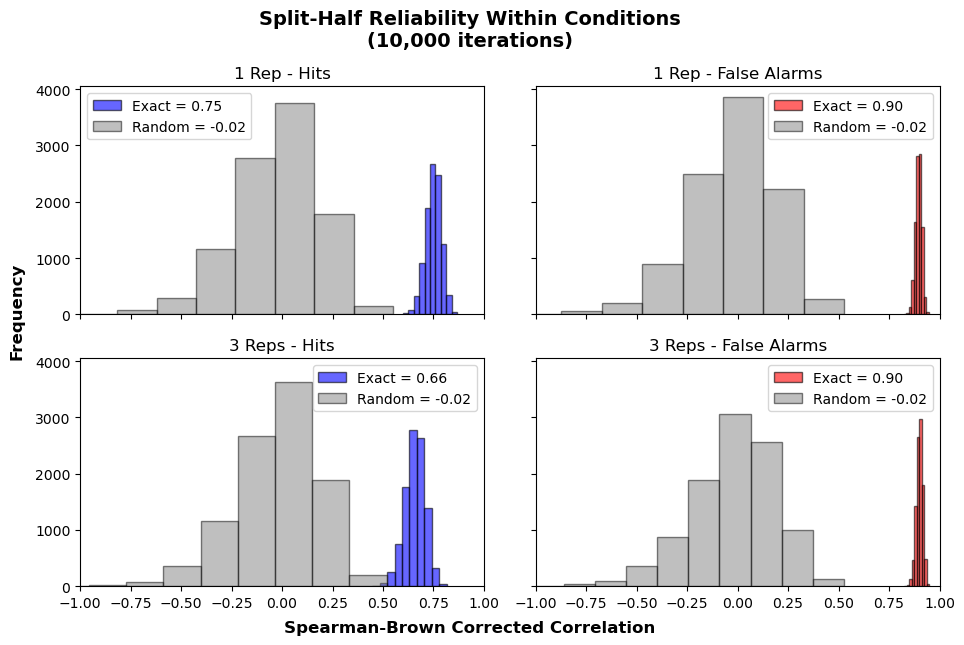

In [50]:
# Visualize WITHIN condition split-half reliability results

n_bins = 10

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

cond_map = {
    "1_Rep": "1 Rep",
    "3_Rep": "3 Reps"
}

# Loop over conditions and plot
for row, cond in enumerate(["1_Rep", "3_Rep"]):

    # ----- Hits -----
    axes[row, 0].hist(
        sh_corrs_hits['Exact'][cond],
        color='blue', alpha=0.6, edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_hits["Exact"][cond]):.2f}'
    )

    axes[row, 0].hist(
        sh_corrs_hits['Random'][cond],
        color='gray', alpha=0.5, edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_hits["Random"][cond]):.2f}'
    )

    axes[row, 0].set_title(f'{cond_map[cond]} - Hits')
    axes[row, 0].legend()

    # ----- FA -----
    axes[row, 1].hist(
        sh_corrs_fa['Exact'][cond],
        color='red', alpha=0.6, edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_fa["Exact"][cond]):.2f}'
    )

    axes[row, 1].hist(
        sh_corrs_fa['Random'][cond],
        color='gray', alpha=0.5, edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_fa["Random"][cond]):.2f}'
    )

    axes[row, 1].set_title(f'{cond_map[cond]} - False Alarms')
    axes[row, 1].legend()

# Global labels
for ax in axes.flatten():
    ax.set_xlim(-1, 1)

fig.text(0.5, 0.04, 'Spearman-Brown Corrected Correlation', ha='center', fontsize=12, fontweight='bold')
fig.text(0.04, 0.5, 'Frequency', va='center', rotation='vertical', fontsize=12, fontweight='bold')

plt.suptitle("Split-Half Reliability Within Conditions\n(10,000 iterations)", 
              ha = 'center',y = 0.93, fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0.05, 0.05, 1, 0.95]) # leave space on the left - bottom - right - top
plt.show()

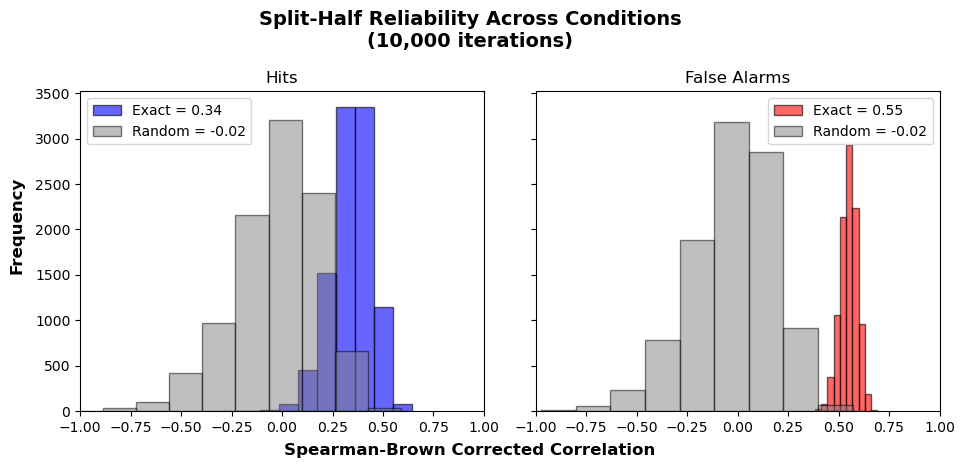

In [51]:
# Visualize ACROSS condition split-half reliability results

n_bins = 10

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
axes = axes.ravel()

cond_map = {
    "1_Rep": "1 Rep",
    "3_Rep": "3 Reps"
}

# Loop over conditions and plot


# ----- Hits -----
axes[0].hist(
    sh_corrs_hits_across['Exact'],
    color='blue', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_hits_across["Exact"]):.2f}'
)

axes[0].hist(
    sh_corrs_hits_across['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_hits_across["Random"]):.2f}'
)

axes[0].set_title(f'Hits')
axes[0].legend()

# ----- FA -----
axes[1].hist(
    sh_corrs_fa_across['Exact'],
    color='red', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_fa_across["Exact"]):.2f}'
)

axes[1].hist(
    sh_corrs_fa_across['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_fa_across["Random"]):.2f}'
)

axes[1].set_title(f'False Alarms')
axes[1].legend()

# Global labels
for ax in axes:
    ax.set_xlim(-1, 1)

fig.text(0.5, 0.04, 'Spearman-Brown Corrected Correlation', ha='center', fontsize=12, fontweight='bold')
fig.text(0.04, 0.5, 'Frequency', va='center', rotation='vertical', fontsize=12, fontweight='bold')

plt.suptitle("Split-Half Reliability Across Conditions\n(10,000 iterations)", 
              ha = 'center',y = 0.93, fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0.05, 0.05, 1, 0.95]) # leave space on the left - bottom - right - top
plt.show()

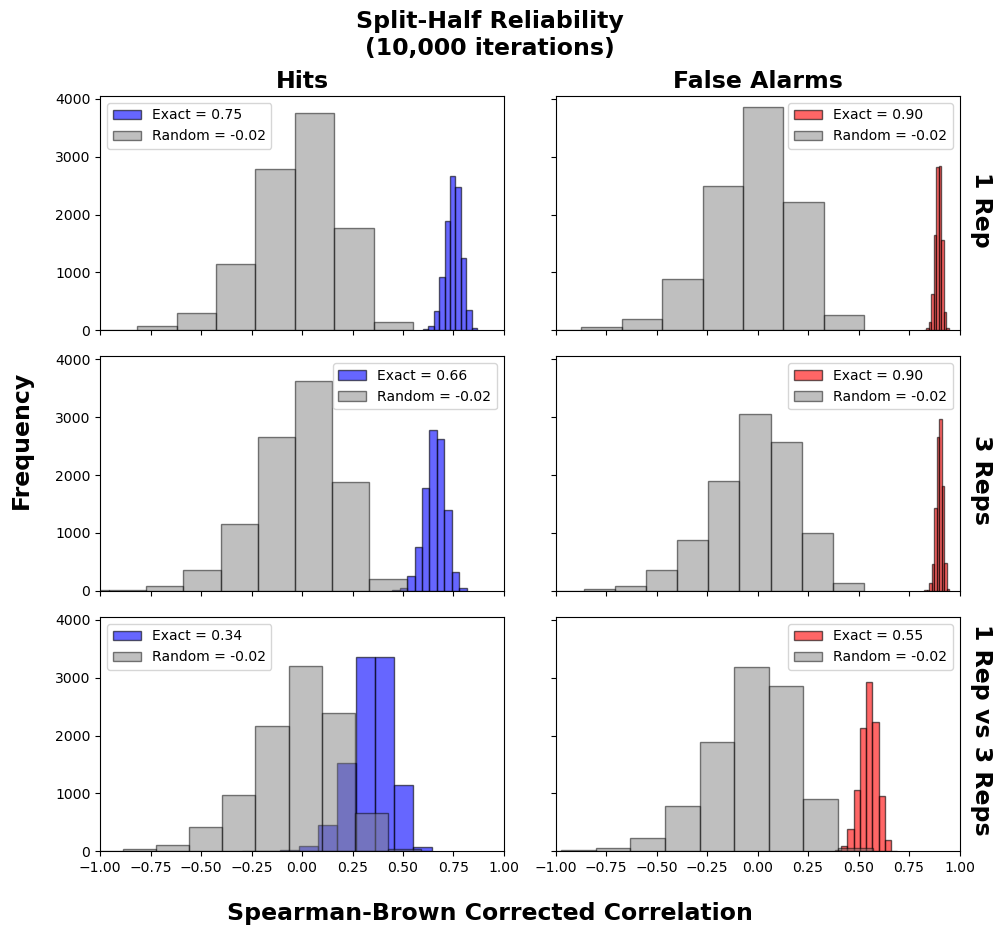

In [52]:
# Combined plot for within and across condition reliability
n_bins = 10

fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex=True, sharey=True)

cond_map = {
    "1_Rep": "1 Rep",
    "3_Rep": "3 Reps"
}

# ----- WITHIN CONDITION (rows 0 and 1) -----
for row, cond in enumerate(["1_Rep", "3_Rep"]):

    # Hits
    axes[row, 0].hist(
        sh_corrs_hits['Exact'][cond],
        color='blue', alpha=0.6, edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_hits["Exact"][cond]):.2f}'
    )

    axes[row, 0].hist(
        sh_corrs_hits['Random'][cond],
        color='gray', alpha=0.5, edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_hits["Random"][cond]):.2f}'
    )

    axes[row, 0].legend()

    # False Alarms
    axes[row, 1].hist(
        sh_corrs_fa['Exact'][cond],
        color='red', alpha=0.6, edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_fa["Exact"][cond]):.2f}'
    )

    axes[row, 1].hist(
        sh_corrs_fa['Random'][cond],
        color='gray', alpha=0.5, edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_fa["Random"][cond]):.2f}'
    )

    axes[row, 1].legend()


# ----- ACROSS CONDITION (row 2) -----

# Hits
axes[2, 0].hist(
    sh_corrs_hits_across['Exact'],
    color='blue', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_hits_across["Exact"]):.2f}'
)

axes[2, 0].hist(
    sh_corrs_hits_across['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_hits_across["Random"]):.2f}'
)

axes[2, 0].legend()


# False Alarms
axes[2, 1].hist(
    sh_corrs_fa_across['Exact'],
    color='red', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_fa_across["Exact"]):.2f}'
)

axes[2, 1].hist(
    sh_corrs_fa_across['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_fa_across["Random"]):.2f}'
)

axes[2, 1].legend()


# ----- Formatting -----
fs_title = 17
fs_ax_labels = 17
fs_grid_labels = 17

for ax in axes.flatten():
    ax.set_xlim(-1, 1)

fig.text(0.5, 0.02, 'Spearman-Brown Corrected Correlation',
         ha='center', fontsize=fs_ax_labels, fontweight='bold')

fig.text(0.02, 0.5, 'Frequency',
         va='center', rotation='vertical', fontsize=fs_ax_labels, fontweight='bold')

plt.suptitle(
    "Split-Half Reliability\n(10,000 iterations)",
    ha='center', y=0.93, fontsize=fs_title, fontweight='bold'
)

# Grid labels
cols = [f'{col}' for col in ['Hits', 'False Alarms']]
rows = [f'{row}' for row in ['1 Rep', '3 Reps', '1 Rep vs 3 Reps']]
row_positions = [0.73, 0.46, 0.21]  # vertical centers of the rows

for ax, col in zip(axes[0], cols):
    ax.set_title(col, fontsize=fs_grid_labels, fontweight='bold')


for y, row in zip(row_positions, rows):
    fig.text(0.98, y, row, va='center', ha='left',
             fontsize=fs_grid_labels, fontweight='bold', rotation=270)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
plt.show()

# H vs FA by distinct

In [53]:
# wider format with Hit and FA columns
df_by_item_wide = (df_by_item[['image_id','condition','category_name',
                                'distinct_rating','prop_yes',
                                'resp_type', 'distinct_type']]
                    .pivot(index = ['image_id', 'condition', 'category_name', 'distinct_rating', 'distinct_type'], 
                            columns='resp_type', values='prop_yes')
                    .reset_index()
                    )
df_by_item_wide

resp_type,image_id,condition,category_name,distinct_rating,distinct_type,FA,Hit
0,3,1_Rep,Andesite,3.17,Bottom,0.310606,0.524194
1,3,3_Rep,Andesite,3.17,Bottom,0.284314,0.500000
2,4,1_Rep,Andesite,3.18,Bottom,0.568182,0.556452
3,4,3_Rep,Andesite,3.18,Bottom,0.460784,0.447368
4,6,1_Rep,Andesite,3.17,Bottom,0.556452,0.734848
...,...,...,...,...,...,...,...
195,471,3_Rep,Shale,2.73,Bottom,0.421569,0.675439
196,472,1_Rep,Shale,2.55,Bottom,0.362903,0.598485
197,472,3_Rep,Shale,2.55,Bottom,0.254386,0.480392
198,476,1_Rep,Shale,2.48,Bottom,0.524194,0.704545


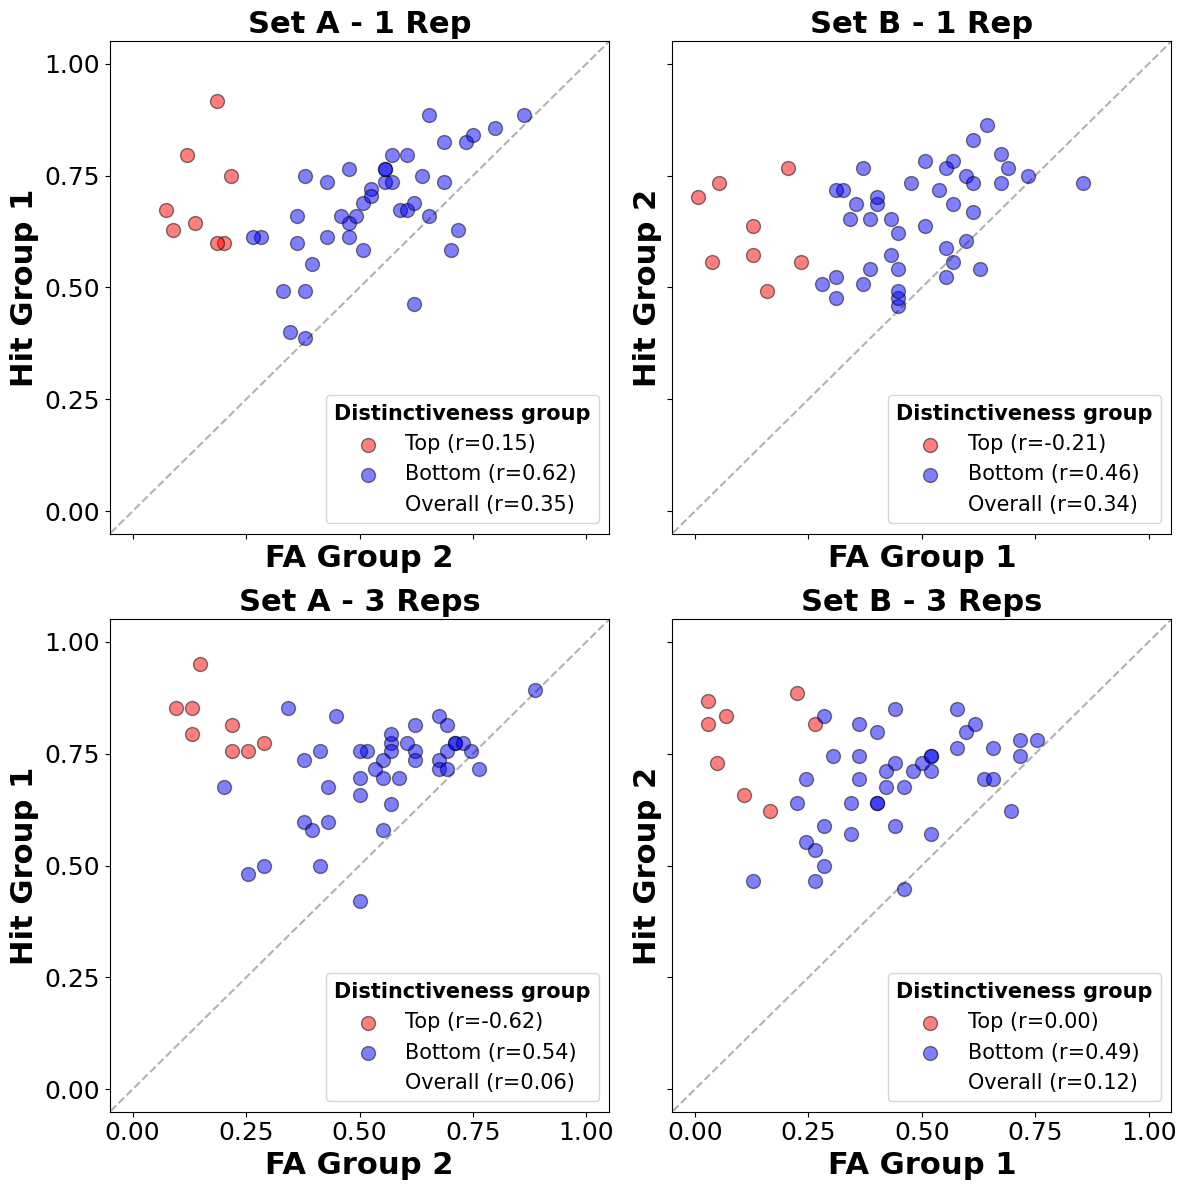

In [54]:
# Plot: H vs FA correlations for each condition and distinctiveness group

fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharey=True, sharex=True)

distinct_groups = ['Top', 'Bottom']
colors = ['red', 'blue']
conditions = ['1_Rep', '3_Rep']
condition_labels = ['1 Rep', '3 Reps']

fs = 22  # font size
fs_axes = 18
fs_legend = 15

for row_idx, (condition, condition_label) in enumerate(zip(conditions, condition_labels)):
    
    # For overall correlations
    x_all_left, y_all_left = [], []
    x_all_right, y_all_right = [], []
    
    # Left column: Group 2 FA vs Group 1 Hit
    for color, distinct in zip(colors, distinct_groups):
        x = df_by_item.loc[(df_by_item['distinct_type']==distinct) & 
                           (df_by_item['group']=='Group2') & 
                           (df_by_item['resp_type']=='FA') &
                           (df_by_item['condition']==condition), 'prop_yes'].reset_index(drop=True)
        y = df_by_item.loc[(df_by_item['distinct_type']==distinct) & 
                           (df_by_item['group']=='Group1') & 
                           (df_by_item['resp_type']=='Hit') &
                           (df_by_item['condition']==condition), 'prop_yes'].reset_index(drop=True)
        
        mask = ~(x.isna() | y.isna())
        r = x[mask].corr(y[mask])
        axes[row_idx, 0].scatter(x, y, alpha=0.5, edgecolor="k", color=color, s=100,
                                 label=f"{distinct} (r={r:.2f})")
        
        # accumulate for overall correlations
        x_all_left.append(x)
        y_all_left.append(y)
    
    # Calculate overall correlation for left column
    x_left = pd.concat(x_all_left, ignore_index=True)
    y_left = pd.concat(y_all_left, ignore_index=True)
    mask_left = ~(x_left.isna() | y_left.isna())
    r_left = x_left[mask_left].corr(y_left[mask_left])
    
    # Add dummy legend entry for overall correlation
    overall_handle_left = Line2D([], [], linestyle='None',
                                 label=f"Overall (r={r_left:.2f})")
    
    axes[row_idx, 0].plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
    axes[row_idx, 0].set_xlabel('FA Group 2', fontweight='bold', fontsize=fs)
    axes[row_idx, 0].set_ylabel('Hit Group 1', fontweight='bold', fontsize=fs)
    axes[row_idx, 0].set_title(f'Set A - {condition_label}', fontsize=fs, fontweight='bold') # (Group 2 FA vs Group 1 Hit)
    axes[row_idx, 0].set_xlim(-0.05, 1.05)
    axes[row_idx, 0].set_ylim(-0.05, 1.05)
    axes[row_idx, 0].set_xticks(np.arange(0, 1.1, 0.25))
    axes[row_idx, 0].set_yticks(np.arange(0, 1.1, 0.25))
    axes[row_idx, 0].tick_params(axis='both', labelsize=fs_axes)
    
    # Rebuild legend with overall r included
    handles_left, labels_left = axes[row_idx, 0].get_legend_handles_labels()
    axes[row_idx, 0].legend(handles_left + [overall_handle_left], 
                            labels_left + [overall_handle_left.get_label()],
                            title="Distinctiveness group", 
                            fontsize=fs_legend,
                            title_fontsize=fs_legend,
                            loc='lower right')
    axes[row_idx, 0].get_legend().get_title().set_fontweight('bold')
    
    # Right column: Group 1 FA vs Group 2 Hit
    for color, distinct in zip(colors, distinct_groups):
        x_rev = df_by_item.loc[(df_by_item['distinct_type']==distinct) & 
                                (df_by_item['group']=='Group1') & 
                                (df_by_item['resp_type']=='FA') &
                                (df_by_item['condition']==condition), 'prop_yes'].reset_index(drop=True)
        y_rev = df_by_item.loc[(df_by_item['distinct_type']==distinct) & 
                                (df_by_item['group']=='Group2') & 
                                (df_by_item['resp_type']=='Hit') &
                                (df_by_item['condition']==condition), 'prop_yes'].reset_index(drop=True)
        
        mask_rev = ~(x_rev.isna() | y_rev.isna())
        r_rev = x_rev[mask_rev].corr(y_rev[mask_rev])
        axes[row_idx, 1].scatter(x_rev, y_rev, alpha=0.5, edgecolor="k", color=color, s=100,
                                 label=f"{distinct} (r={r_rev:.2f})")
        
        # accumulate for overall correlations
        x_all_right.append(x_rev)
        y_all_right.append(y_rev)
    
    # Calculate overall correlation for right column
    x_right = pd.concat(x_all_right, ignore_index=True)
    y_right = pd.concat(y_all_right, ignore_index=True)
    mask_right = ~(x_right.isna() | y_right.isna())
    r_right = x_right[mask_right].corr(y_right[mask_right])
    
    # Add dummy legend entry for overall correlation
    overall_handle_right = Line2D([], [], linestyle='None',
                                  label=f"Overall (r={r_right:.2f})")
    
    axes[row_idx, 1].plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
    axes[row_idx, 1].set_xlabel('FA Group 1', fontweight='bold', fontsize=fs)
    axes[row_idx, 1].set_ylabel('Hit Group 2', fontweight='bold', fontsize=fs)
    axes[row_idx, 1].set_title(f'Set B - {condition_label}', fontsize=fs, fontweight='bold') # Group 1 FA vs Group 2 Hit
    axes[row_idx, 1].set_xlim(-0.05, 1.05)
    axes[row_idx, 1].set_ylim(-0.05, 1.05)
    axes[row_idx, 1].set_xticks(np.arange(0, 1.1, 0.25))
    axes[row_idx, 1].set_yticks(np.arange(0, 1.1, 0.25))
    axes[row_idx, 1].tick_params(axis='both', labelsize=fs_axes)
    
    # Rebuild legend with overall r included
    handles_right, labels_right = axes[row_idx, 1].get_legend_handles_labels()
    axes[row_idx, 1].legend(handles_right + [overall_handle_right], 
                            labels_right + [overall_handle_right.get_label()],
                            title="Distinctiveness group", 
                            fontsize=fs_legend,
                            title_fontsize=fs_legend,
                            loc='lower right')
    axes[row_idx, 1].get_legend().get_title().set_fontweight('bold')

plt.tight_layout()
plt.show()

In [158]:
# Exact correlations
# (use as a func because later we'll use it for predicted values as well)
def get_H_vs_FA_correlations(df_by_item, pred_col='prop_yes'):

    conditions = ['1_Rep', '3_Rep']
    condition_labels = ['1 Rep', '3 Reps']
    distinct_groups = ['Top', 'Bottom']
    panels = {
            "Set A (Group2 FA vs Group1 Hit)": ("Group2", "Group1"),
            "Set B (Group1 FA vs Group2 Hit)": ("Group1", "Group2"),
        }

    print(f"Column: {pred_col}")

    for condition, cond_label in zip(conditions, condition_labels):
        print(f"\n===== CONDITION: {cond_label} =====")

        for panel_name, (grA, grB) in panels.items():
            print(f"\n{panel_name}")

            x_all, y_all = [], []

            for distinct in distinct_groups:
                x = df_by_item.loc[
                    (df_by_item['distinct_type'] == distinct) &
                    (df_by_item['group'] == grA) &
                    (df_by_item['resp_type'] == 'FA') &
                    (df_by_item['condition'] == condition),
                    pred_col
                ].reset_index(drop=True)

                y = df_by_item.loc[
                    (df_by_item['distinct_type'] == distinct) &
                    (df_by_item['group'] == grB) &
                    (df_by_item['resp_type'] == 'Hit') &
                    (df_by_item['condition'] == condition),
                    pred_col
                ].reset_index(drop=True)

                mask = ~(x.isna() | y.isna())
                r, p = pearsonr(x[mask], y[mask])

                print(f"  {distinct}: r = {r:.2f}, p = {p:.3f}, n = {mask.sum()}")

                x_all.append(x)
                y_all.append(y)

            # Overall (collapsed over distinctiveness groups)
            x_all = pd.concat(x_all, ignore_index=True)
            y_all = pd.concat(y_all, ignore_index=True)
            mask_all = ~(x_all.isna() | y_all.isna())
            r_all, p_all = pearsonr(x_all[mask_all], y_all[mask_all])

            print(f"  Overall: r = {r_all:.2f}, p = {p_all:.3f}, n = {mask_all.sum()}")

In [56]:
get_H_vs_FA_correlations(df_by_item, pred_col='prop_yes')

Column: prop_yes

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.15, p = 0.716, n = 8
  Bottom: r = 0.62, p = 0.000, n = 42
  Overall: r = 0.35, p = 0.014, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = -0.21, p = 0.616, n = 8
  Bottom: r = 0.46, p = 0.002, n = 42
  Overall: r = 0.34, p = 0.016, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = -0.62, p = 0.100, n = 8
  Bottom: r = 0.54, p = 0.000, n = 42
  Overall: r = 0.06, p = 0.694, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.00, p = 0.995, n = 8
  Bottom: r = 0.49, p = 0.001, n = 42
  Overall: r = 0.12, p = 0.409, n = 50


# Models

## Hybrid-Similarity Model

Hybrid-Similarity Model. 

$$P( 'Old' | i) = P( 'Old' | F_i)$$

Where $P( 'Old' | F_i) = \frac{F_i}{F_i + k}$, where $k$ is a free parameter. 

$F_i = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$ is the similarity between test item $i$ to all study items $j$. 

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D_{ij}}$ ($c$ is a free parameter, $D_{ij} = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i} \times e^{-c \times D_{ij}} = e^{\beta \times d_i} \times 1 = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{\alpha \times d_i} \times e^{-c \times D_{ij}}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

In [143]:
# Load MDS solution
mds_solution = pd.read_csv('https://raw.githubusercontent.com/DaniilAzarov123/Rocks_Database/main/info/Rocks480_MDS8_solution.csv')
mds_solution

,image_id,dim1,dim2,dim3,dim4,dim5,dim6,dim7,dim8
0,1,-2.757,-1.594,1.052,0.768,1.343,1.711,1.795,0.809
1,2,2.001,-0.754,1.405,-1.382,-1.384,0.976,-0.067,1.972
2,3,0.261,-0.508,-2.962,-0.608,0.009,-0.191,2.720,-1.224
3,4,0.382,-0.027,-0.148,-1.899,-1.948,1.862,0.968,0.986
4,5,0.288,2.013,-1.102,-1.285,0.344,-0.009,2.696,-0.174
...,...,...,...,...,...,...,...,...,...
475,476,0.749,-3.021,-1.908,-1.689,-0.493,4.441,-0.122,1.618
476,477,-0.054,-2.743,-1.435,-2.903,0.315,3.161,1.833,1.288
477,478,0.007,-2.077,-4.012,-1.633,-0.366,2.558,4.210,-0.060
478,479,0.177,-2.520,-2.293,-1.216,0.545,0.805,2.302,0.629


In [144]:
# study lists
study_list_gr1 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group1', 'image_id'].unique())
study_list_gr2 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group2', 'image_id'].unique())

# test list
test_list = np.sort(filtered_data_test['image_id'].unique())

In [145]:
# Calculate distances

# Step 1: Extract the MDS coordinates (first 8 columns)
# Make sure image_id is set as the index for easy lookup
mds_coords = mds_solution.set_index('image_id').iloc[:, :8]

# ------------- Group 1 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr1

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr1 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

# ------------- Group 2 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr2

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr2 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

In `dist_mat_gr1` (100x50) and `dist_mat_gr2` (100x50), each row is each test item (they are the **same** accross two matrices), and each column is each study item (they are **different** accross matrices).

In [146]:
# Dicionary comprehension: {image_id: distinctiveness}
distinctiveness_image_id = df_by_item.set_index('image_id')['distinct_rating'].to_dict()
list(distinctiveness_image_id.items())[:5] # first 5 items

[(3, 3.17), (4, 3.18), (6, 3.17), (8, 1.95), (9, 2.49)]

In [147]:
# Transform similarities based on distinctiveness ratings:
# increased self-similarity for more distinctive items and decreased similarity to other items for more distinctive items
def transform_similarity_matrix(alpha, beta, 
                                similarity_matrix, 
                                distinctiveness_dict = distinctiveness_image_id):
    # Create a copy to avoid modifying the original
    transformed = similarity_matrix.copy()
    
    # Iterate through each row
    for row_id in transformed.index:
        # Get distinctiveness for this row's image
        distinct_i = distinctiveness_dict[row_id]
        
        # Iterate through each column
        for col_id in transformed.columns:
            s_ij = similarity_matrix.loc[row_id, col_id]
            
            if row_id == col_id:
                # Self-similarity case: exp(beta * distinct_i)
                # Since s_ii = 1
                transformed.loc[row_id, col_id] = np.exp(beta * distinct_i)
            else:
                # Similarity between different items (item i and item j) case
                # s_ij * exp(-alpha * distinct_i)
                transformed.loc[row_id, col_id] = np.exp(-alpha * distinct_i) * s_ij
    
    return transformed

In [62]:
# For NegLogLikelihood calculation
filtered_data_test['responded_old'] = np.where(filtered_data_test['response'] == "l", 1, 0)
filtered_data_test

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,good_subj,resp_type,responded_old
0,311,91746,Group2,3_Rep,test_phase,Target,l,l,True,1776.0,Gneiss,13,M,M_Gneiss_15.png,207,3.11,Bottom,True,Hit,1
1,313,91746,Group2,3_Rep,test_phase,Target,l,l,True,767.0,Rock Salt,28,S,S_Rock Salt_13.png,445,7.58,Top,True,Hit,1
2,315,91746,Group2,3_Rep,test_phase,Target,l,l,True,779.0,Pegmatite,7,I,I_Pegmatite_03.png,99,7.24,Top,True,Hit,1
3,317,91746,Group2,3_Rep,test_phase,Target,l,l,True,805.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit,1
4,319,91746,Group2,3_Rep,test_phase,Foil,a,a,True,924.0,Rhyolite,10,I,I_Rhyolite_16.png,160,2.19,Bottom,True,CR,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23195,501,92625,Group2,3_Rep,test_phase,Foil,a,a,True,1088.0,Obsidian,6,I,I_Obsidian_05.png,85,7.32,Top,True,CR,0
23196,503,92625,Group2,3_Rep,test_phase,Target,l,l,True,815.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit,1
23197,505,92625,Group2,3_Rep,test_phase,Foil,l,a,False,1000.0,Marble,15,M,M_Marble_04.png,228,3.15,Bottom,True,FA,1
23198,507,92625,Group2,3_Rep,test_phase,Target,l,l,True,683.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom,True,Hit,1


In [148]:
# Different parameters for different groups

def HS_model(parameters,
             data, 
             distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
             distinctiveness_dict = distinctiveness_image_id):
    # parameters
    c, alpha, beta, k = parameters
    
    # get group name
    group = data['group'].unique()[0]
    groupN = 0 if group == 'Group1' else 1
    
    # Distances matrices
    distances_mat = distances_mats_list[groupN]
    
    # (Raw) Similarity matrices
    similarity_mat = np.exp(-c * distances_mat)
    
    # Transform similarities based on distinctiveness ratings
    similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
                                                             similarity_matrix=similarity_mat, distinctiveness_dict=distinctiveness_dict)
    
    # Summed similarities (familiarity) for each item
    familiarity = np.sum(similarity_mat_transformed, axis=1)
    
    # Expand familiarities for each subject (to match the test data)
    familiarities = []
    for _, row in data.iterrows():
        image_id = row['image_id']
        familiarity_i_subj = familiarity.loc[familiarity.index == image_id]        
        familiarities.append(familiarity_i_subj.values[0] if not familiarity_i_subj.empty else np.nan)
    
    # Predicted proportions of "Old" responses ("Yes")
    predictions = [fam / (fam + k) for fam in familiarities]
    
    return predictions    

## HS-model: c-within, c-between

Different c parameter if the comparison is between objects from the same (c-within) or different (c-between) sub-categories

In [ ]:
# Category mapping for each image_id
# (check which image belongs to which sub-category)
category_image_id = (
    filtered_data_test
    .drop_duplicates('image_id')
    .set_index('image_id')['category']
    .to_dict()
)

In [137]:
# HS model with different c values for within vs between super-category comparisons
def HS_model_cwb(parameters,
                 data,
                 distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                 distinctiveness_dict=distinctiveness_image_id,
                 category_dict=category_image_id):
    # parameter order: c_within, c_between, k, alpha, beta
    c_within, c_between, k, alpha, beta = parameters

    # group -> which distance matrix
    group = data['group'].unique()[0]
    groupN = 0 if group == 'Group1' else 1
    distances_mat = distances_mats_list[groupN]   # index=test_ids, columns=study_ids

    # --- Raw similarity with two c values (within vs between super-category) ---
    test_cats  = np.array([category_dict[i] for i in distances_mat.index])
    study_cats = np.array([category_dict[j] for j in distances_mat.columns])
    within_mask = test_cats[:, None] == study_cats[None, :]   # (n_test, n_study)

    dist_vals = distances_mat.to_numpy()
    sim_vals = np.where(
        within_mask,
        np.exp(-c_within  * dist_vals),
        np.exp(-c_between * dist_vals),
    )
    similarity_mat = pd.DataFrame(
        sim_vals, index=distances_mat.index, columns=distances_mat.columns
    )

    # --- Distinctiveness transform (your existing function, unchanged) ---
    similarity_mat_transformed = transform_similarity_matrix(
        alpha=alpha, beta=beta,
        similarity_matrix=similarity_mat,
        distinctiveness_dict=distinctiveness_dict,
    )

    # Familiarity = summed transformed similarity per test item
    familiarity = np.sum(similarity_mat_transformed, axis=1)

    # Expand to test rows
    familiarities = []
    for _, row in data.iterrows():
        image_id = row['image_id']
        fam_i = familiarity.loc[familiarity.index == image_id]
        familiarities.append(fam_i.values[0] if not fam_i.empty else np.nan)

    predictions = [fam / (fam + k) for fam in familiarities]
    return predictions

## Recollection Model

Recollection Model. 

$$P( 'Old' | i) = P_{recollect} + (1 - P_{recollect}) \times P( 'Old' | F_i)$$

Where $P( 'Old' | F_i) = \frac{F_i}{F_i + k}$, where $k$ is a free parameter. 

$F_i = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$ is the similarity between test item $i$ to all study items $j$. 

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D}$ ($c$ is a free parameter, $D = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{- \alpha \times d_i}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

The recollection part is $P_{recollect} = P_{sample} \times P_{recover}$ where: 

- $P_{sample} = \frac{ S_{ii} }{ \sum_{j} S_{ij}} = \frac{ e^{\beta \times d_i} }{ F_i}$
- $P_{recover} = \frac{S_{ii}}{S_{ii} + k_{recollect}} = \frac{e^{\beta \times d_i}}{S_{ii} + k_{recollect}}$, where $k_{recollect}$ is a free parameter.



In [64]:
# # Different parameters for different groups

# def recollection_model(parameters, 
#                           data, 
#                           distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
#                           distinctiveness_dict = distinctiveness_image_id):
#     """
#     Recollection-Familiarity model to predict P("Yes" | Item i) based on distances in the similarity space and their distinctiveness.
    
#     Recollection component added is based on the self-similarity values.
    
#     Parameters:
#     -----------
#     parameters : list or np.ndarray
#         List of parameters [c, alpha, beta, k, k_recollect]
#     data : pd.DataFrame
#         Long DataFrame with columns: 'group', 'image_id'
#     distances_mat : list of pd.DataFrame
#         A list of two distance matrices for Group 1 and Group 2 (pd.DataFrame)
#     distinctiveness_dict : dict
#         Dictionary mapping image_id to distinctiveness rating
    
#     Returns:
#     --------
#     predictions : list
#         List of predicted probabilities P(Old|Item) for each row in data
#     """
#     # parameters
#     c, alpha, beta, k, k_recollect = parameters
    
#     # get group name
#     group = data['group'].unique()[0]
#     groupN = 0 if group == 'Group1' else 1
    
#     # Distances matrices
#     distances_mat = distances_mats_list[groupN]
    
#     # (Raw) Similarity matrices
#     similarity_mat = calculate_similarity_matrix(distances_mat, c)
    
#     # Transformed Similarity matrices
#     similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
#                                                                  similarity_matrix=similarity_mat, 
#                                                                  distinctiveness_dict=distinctiveness_dict)
    
#     # Familiarity values for groups (aka summed similarities)
#     familiarity = np.sum(similarity_mat_transformed, axis=1)
    
#     # Extract self-similarities
#     self_similarities = []
#     for i in range(similarity_mat_transformed.shape[0]):
#         is_old = np.sum(similarity_mat_transformed.index[i] == similarity_mat_transformed.columns) > 0
#         idx = similarity_mat_transformed.index[i]
#         if is_old:
#             self_similarities.append(similarity_mat_transformed.loc[idx, idx]) # self-match value
#         else:
#             self_similarities.append(0) # no recollection
    
#     # Calclulate recollection components:
#     p_sample = np.array(self_similarities) / familiarity.values
#     p_recover = np.array(self_similarities) / (np.array(self_similarities) + k_recollect)
#     p_recollect = p_sample * p_recover
#     # make into a pd.Series (with index)
#     p_recollect = pd.Series(p_recollect, index=similarity_mat_transformed.index)
    
#     # iterate over rows in filtered_data_test to get familiarity and recollections
#     # for each item and subject in the right order
#     familiarities = []
#     recollections = []
#     for _, row in data.iterrows():
#         image_id = row['image_id']
#         familiarity_i_subj = familiarity.loc[familiarity.index == image_id]        
#         familiarities.append(familiarity_i_subj.values[0] if not familiarity_i_subj.empty else np.nan)
#         recollection_i_subj = p_recollect.loc[p_recollect.index == image_id]
#         recollections.append(recollection_i_subj.values[0] if not recollection_i_subj.empty else np.nan)
    
#     # Predicted proportions of "Old" responses ("Yes"): p(yes)
#     predictions = [rec + (1 - rec) * ( fam / (fam + k) ) for fam, rec in zip(familiarities,recollections)]
    
#     return predictions    

# Optimization

In [65]:
# NLL function
def NegLogLikelihood(parameters,
                     model_function,
                     df_observed = filtered_data_test.loc[filtered_data_test["group"]=="Group1"], 
                     distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
                     distinctiveness_dict = distinctiveness_image_id):
    # Get model predictions
    predicted = model_function(parameters, df_observed, distances_mats_list, distinctiveness_dict)
    
    # Merge observed and predicted data
    df_merged = df_observed.copy()
    df_merged['prop_yes_pred'] = predicted
    
    # Avoid log(0) by clipping predicted probabilities
    epsilon = 1e-10
    df_merged['prop_yes_pred'] = df_merged['prop_yes_pred'].clip(epsilon, 1 - epsilon)
    
    # Calculate log-likelihood for each observation
    df_merged['log_likelihood'] = (
        df_merged['responded_old'] * np.log(df_merged['prop_yes_pred']) +
        (1 - df_merged['responded_old']) * np.log(1 - df_merged['prop_yes_pred'])
                                   )
    # Sum log-likelihoods and return negative value
    neg_log_likelihood = -df_merged['log_likelihood'].sum()
    
    return neg_log_likelihood

In [66]:
# NLL function for pooled data across groups
def NegLogLikelihood_pooled(parameters,
                             model_function,
                             df_observed, # data for BOTH groups, one condition
                             distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                             distinctiveness_dict=distinctiveness_image_id):
    total_nll = 0
    epsilon = 1e-10

    # Loop over groups, apply the SAME parameters, sum the NLL
    for group in ['Group1', 'Group2']:
        df_group = df_observed.loc[df_observed['group'] == group]
        if df_group.empty:
            print(f"Warning: No data for {group} in the provided df_observed")

        predicted = model_function(parameters, df_group, distances_mats_list, distinctiveness_dict)

        df_merged = df_group.copy()
        df_merged['prop_yes_pred'] = predicted
        df_merged['prop_yes_pred'] = df_merged['prop_yes_pred'].clip(epsilon, 1 - epsilon)

        log_likelihood = (
            df_merged['responded_old'] * np.log(df_merged['prop_yes_pred']) +
            (1 - df_merged['responded_old']) * np.log(1 - df_merged['prop_yes_pred'])
        )
        total_nll += -log_likelihood.sum()

    return total_nll

In [138]:
# NLL for group-specific and pooled parameters

_eps = 1e-10

# Group specific
def NegLogLikelihood_cwb(parameters, model_function, df_observed,
                         distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                         distinctiveness_dict=distinctiveness_image_id,
                         category_dict=category_image_id):
    pred = model_function(parameters, df_observed,
                          distances_mats_list, distinctiveness_dict, category_dict)
    df = df_observed.copy()
    df['p'] = np.clip(pred, _eps, 1 - _eps)
    ll = df['responded_old'] * np.log(df['p']) + (1 - df['responded_old']) * np.log(1 - df['p'])
    return -ll.sum()


# Pooled across groups
def NegLogLikelihood_cwb_pooled(parameters, model_function, df_observed,
                                distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                                distinctiveness_dict=distinctiveness_image_id,
                                category_dict=category_image_id):
    # SAME parameters applied to both groups; NLLs summed
    total = 0.0
    for group in ['Group1', 'Group2']:
        dfg = df_observed.loc[df_observed['group'] == group]
        if dfg.empty:
            print(f"Warning: no data for {group}")
            continue
        pred = model_function(parameters, dfg,
                              distances_mats_list, distinctiveness_dict, category_dict)
        d = dfg.copy()
        d['p'] = np.clip(pred, _eps, 1 - _eps)
        ll = d['responded_old'] * np.log(d['p']) + (1 - d['responded_old']) * np.log(1 - d['p'])
        total += -ll.sum()
    return total

In [67]:
# Store optimization results in a dictionary
# for each model, condition and group
optimization_result = {}

## HS-model optim

In [68]:
initial_params = [1, 1, 1, 1]  # c, alpha, beta, k

# Set bounds for parameters (optional but recommended)
bounds = [
    (None, None),      # c >= 0
    (None, None),      # alpha >= 0
    (None, None),      # beta >= 0
    (None, None)      # k >= 0
]

# store optimization results in a dictionary
model = 'HS_model'
optimization_result[model] = {}
groups = ['Group1', 'Group2']
conditions = ['1_Rep', '3_Rep']

# Loop through each group and condition
for condition in conditions:
    for group in groups:
        print(f"Optimizing for {condition} - {group}...")
        
        # Filter observed data for this group and condition
        df_observed = filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition)
        ]
        
        # Optimize parameters using Nelder-Mead method
        result = minimize(
            NegLogLikelihood, 
            initial_params, 
            args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id), 
            method='Nelder-Mead',
            bounds=bounds,
            options={'maxiter': 1000, 'disp': True}
        )
        
        # Store results
        optimization_result[model][(group, condition)] = result
        
        print(f"Best parameters for {condition} - {group}: {result.x}")
        print(f"Negative Log-Likelihood: {result.fun}\n")
        
        # Flag if optimization did not converge
        if not result.success:
            print("=============== Attention: Optimization did not converge! ===============\n")

Optimizing for 1_Rep - Group1...
Optimization terminated successfully.
         Current function value: 4100.127459
         Iterations: 164
         Function evaluations: 282
Best parameters for 1_Rep - Group1: [0.52126188 0.19650687 0.22099545 2.11614714]
Negative Log-Likelihood: 4100.127459279036

Optimizing for 1_Rep - Group2...
Optimization terminated successfully.
         Current function value: 3944.543545
         Iterations: 225
         Function evaluations: 371
Best parameters for 1_Rep - Group2: [0.76401335 0.03087946 0.088326   1.16729782]
Negative Log-Likelihood: 3944.543544977685

Optimizing for 3_Rep - Group1...
Optimization terminated successfully.
         Current function value: 3017.787846
         Iterations: 186
         Function evaluations: 321
Best parameters for 3_Rep - Group1: [0.71906807 0.09949254 0.26333252 1.4370371 ]
Negative Log-Likelihood: 3017.787846350463

Optimizing for 3_Rep - Group2...
Optimization terminated successfully.
         Current functi

In [69]:
# Best parameters:
print("Best parameters:\n")
param_names = ['c', 'alpha', 'beta', 'k']
for gr_cond, parameters in zip(optimization_result['HS_model'].keys(), 
                               list(optimization_result['HS_model'].values())
                               ):
    params = parameters.x
    print(f"{gr_cond[1]} - {gr_cond[0]}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")

Best parameters:

1_Rep - Group1:
 c: 0.521, alpha: 0.197, beta: 0.221, k: 2.116

1_Rep - Group2:
 c: 0.764, alpha: 0.031, beta: 0.088, k: 1.167

3_Rep - Group1:
 c: 0.719, alpha: 0.099, beta: 0.263, k: 1.437

3_Rep - Group2:
 c: 0.595, alpha: 0.109, beta: 0.254, k: 1.703



In [70]:
# Predict data using optimized parameters
filtered_data_test['HS_preds'] = np.nan
groups = ['Group1', 'Group2']
conditions = ['1_Rep', '3_Rep']
model = 'HS_model'
for condition in conditions:
    for group in groups:
        print(f"Predicting for {condition} - {group}...")
        
        # Get optimized parameters for this group and condition
        result = optimization_result[model][(group, condition)]
        optimal_params = result.x
        
        # Filter data for this group and condition
        data_subset = filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition)
        ]
        
        # Get predictions
        predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
        
        # Store predictions in the main DataFrame
        filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition),
            'HS_preds'
        ] = predictions

Predicting for 1_Rep - Group1...
Predicting for 1_Rep - Group2...
Predicting for 3_Rep - Group1...
Predicting for 3_Rep - Group2...


In [71]:
# Add predictions to df_by_item (mean per item)
df_by_item = pd.merge(df_by_item, 
                      pd.pivot_table(filtered_data_test, 
                                     index=['image_id','group', 'condition'], 
                                     values='HS_preds', 
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group', 'condition']
                      )
df_by_item

,image_id,condition,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type,HS_preds
0,3,1_Rep,Group1,65,20,Foil,Andesite,3.17,Bottom,0.310606,FA,0.500815
1,3,1_Rep,Group2,61,32,Target,Andesite,3.17,Bottom,0.524194,Hit,0.658036
2,3,3_Rep,Group1,50,14,Foil,Andesite,3.17,Bottom,0.284314,FA,0.469553
3,3,3_Rep,Group2,56,28,Target,Andesite,3.17,Bottom,0.500000,Hit,0.687004
4,4,1_Rep,Group1,65,37,Foil,Andesite,3.18,Bottom,0.568182,FA,0.485232
...,...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,56,14,Foil,Shale,2.55,Bottom,0.254386,FA,0.509505
396,476,1_Rep,Group1,65,46,Target,Shale,2.48,Bottom,0.704545,Hit,0.651839
397,476,1_Rep,Group2,61,32,Foil,Shale,2.48,Bottom,0.524194,FA,0.541247
398,476,3_Rep,Group1,50,40,Target,Shale,2.48,Bottom,0.794118,Hit,0.685102


## HS pooled across groups

In [72]:
# ---- Optimize: 4 params * 2 conditions = 8 total ----
initial_params = [1, 1, 1, 1]  # c, alpha, beta, k
model = 'HS_pooled_groups_model'
optimization_result[model] = {}
conditions = ['1_Rep', '3_Rep']

for condition in conditions:
    print(f"Optimizing for {condition} (pooled across groups)...")

    df_observed = filtered_data_test.loc[filtered_data_test["condition"] == condition]

    result = minimize(
        NegLogLikelihood_pooled, # use this NLL function for pooled data
        initial_params,
        args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id),
        method='Nelder-Mead',
        options={'maxiter': 1000, 'disp': True}
    )

    optimization_result[model][condition] = result

    print(f"Best parameters for {condition}: {result.x}")
    print(f"Negative Log-Likelihood: {result.fun}\n")

    if not result.success:
        print("=============== Attention: Optimization did not converge! ===============\n")


Optimizing for 1_Rep (pooled across groups)...
Optimization terminated successfully.
         Current function value: 8053.674438
         Iterations: 201
         Function evaluations: 334
Best parameters for 1_Rep: [0.61545937 0.12762878 0.16502192 1.66222557]
Negative Log-Likelihood: 8053.674437977645

Optimizing for 3_Rep (pooled across groups)...
Optimization terminated successfully.
         Current function value: 6562.666037
         Iterations: 199
         Function evaluations: 338
Best parameters for 3_Rep: [0.66660632 0.09392642 0.25329765 1.52664512]
Negative Log-Likelihood: 6562.666037184865



In [73]:
# Best parameters
print("Best parameters (pooled model):\n")
param_names = ['c', 'alpha', 'beta', 'k']
for condition, res in optimization_result[model].items():
    params = res.x
    print(f"{condition}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")


Best parameters (pooled model):

1_Rep:
 c: 0.615, alpha: 0.128, beta: 0.165, k: 1.662

3_Rep:
 c: 0.667, alpha: 0.094, beta: 0.253, k: 1.527



In [74]:
# Predict using pooled parameters
filtered_data_test['HS_pooled_groups_preds'] = np.nan

for condition in conditions:
    optimal_params = optimization_result[model][condition].x

    for group in ['Group1', 'Group2']:
        mask = (filtered_data_test["group"] == group) & (filtered_data_test["condition"] == condition)
        data_subset = filtered_data_test.loc[mask]

        predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
        filtered_data_test.loc[mask, 'HS_pooled_groups_preds'] = predictions

In [75]:
# Merge mean predictions into df_by_item, as with the other models
df_by_item = pd.merge(df_by_item,
                      pd.pivot_table(filtered_data_test,
                                     index=['image_id','group', 'condition'],
                                     values='HS_pooled_groups_preds',
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group', 'condition']
                      )

## Base model optim

In [76]:
initial_params_reduced = [1, 1]  # c, k (alpha=0, beta=0 fixed)

# store optimization results in a dictionary
model = 'Base_model'
optimization_result[model] = {}
groups = ['Group1', 'Group2']
conditions = ['1_Rep', '3_Rep']

# Loop through each group and condition
for condition in conditions:
    for group in groups:
        print(f"Optimizing for {condition} - {group}...")
        
        # Filter observed data for this group and condition
        df_observed = filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition)
        ]
        
        # Optimize parameters using Nelder-Mead method (alpha=0, beta=0 fixed)
        result = minimize(
            lambda params, *args: NegLogLikelihood([params[0], 0, 0, params[1]], *args),
            initial_params_reduced, 
            args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id), 
            method='Nelder-Mead',
            options={'maxiter': 1000, 'disp': True}
        )
        
        # Store results
        optimization_result[model][(group, condition)] = result
        
        print(f"Best parameters for {condition} - {group}: {result.x}")
        print(f"Negative Log-Likelihood: {result.fun}\n")
        
        # Flag if optimization did not converge
        if not result.success:
            print("=============== Attention: Optimization did not converge! ===============\n")


Optimizing for 1_Rep - Group1...
Optimization terminated successfully.
         Current function value: 4146.297897
         Iterations: 33
         Function evaluations: 65
Best parameters for 1_Rep - Group1: [0.87812469 0.84895755]
Negative Log-Likelihood: 4146.297897091899

Optimizing for 1_Rep - Group2...
Optimization terminated successfully.
         Current function value: 3950.721217
         Iterations: 39
         Function evaluations: 76
Best parameters for 1_Rep - Group2: [0.87350799 0.82952447]
Negative Log-Likelihood: 3950.721216924225

Optimizing for 3_Rep - Group1...
Optimization terminated successfully.
         Current function value: 3063.068867
         Iterations: 40
         Function evaluations: 76
Best parameters for 3_Rep - Group1: [1.03978503 0.56057381]
Negative Log-Likelihood: 3063.0688665168345

Optimizing for 3_Rep - Group2...
Optimization terminated successfully.
         Current function value: 3567.287381
         Iterations: 38
         Function evaluat

In [77]:
# Best parameters:
print("Best parameters:\n")
param_names = ['c', 'k']
for gr_cond, parameters in zip(optimization_result['Base_model'].keys(), 
                               list(optimization_result['Base_model'].values())
                               ):
    params = parameters.x
    print(f"{gr_cond[1]} - {gr_cond[0]}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")

Best parameters:

1_Rep - Group1:
 c: 0.878, k: 0.849

1_Rep - Group2:
 c: 0.874, k: 0.83

3_Rep - Group1:
 c: 1.04, k: 0.561

3_Rep - Group2:
 c: 0.912, k: 0.642



In [78]:
# Predict data using optimized parameters
filtered_data_test['Base_preds'] = np.nan
groups = ['Group1', 'Group2']
conditions = ['1_Rep', '3_Rep']
model = 'Base_model'
for condition in conditions:
    for group in groups:
        print(f"Predicting for {condition} - {group}...")
        
        # Get optimized parameters for this group and condition
        result = optimization_result[model][(group, condition)]
        optimal_params_reduced = result.x
        
        # Reconstruct full parameter vector with alpha=0, beta=0
        optimal_params_full = [optimal_params_reduced[0], 0, 0, optimal_params_reduced[1]]
        
        # Filter data for this group and condition
        data_subset = filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition)
        ]
        
        # Get predictions
        predictions = HS_model(optimal_params_full, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
        
        # Store predictions in the main DataFrame
        filtered_data_test.loc[
            (filtered_data_test["group"] == group) &
            (filtered_data_test["condition"] == condition),
            'Base_preds'
        ] = predictions

Predicting for 1_Rep - Group1...
Predicting for 1_Rep - Group2...
Predicting for 3_Rep - Group1...
Predicting for 3_Rep - Group2...


In [79]:
# Add predictions to df_by_item (mean per item)
df_by_item = pd.merge(df_by_item, 
                      pd.pivot_table(filtered_data_test, 
                                     index=['image_id','group', 'condition'], 
                                     values='Base_preds', 
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group', 'condition']
                      )
df_by_item

,image_id,condition,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type,HS_preds,HS_pooled_groups_preds,Base_preds
0,3,1_Rep,Group1,65,20,Foil,Andesite,3.17,Bottom,0.310606,FA,0.500815,0.516068,0.526467
1,3,1_Rep,Group2,61,32,Target,Andesite,3.17,Bottom,0.524194,Hit,0.658036,0.641501,0.666133
2,3,3_Rep,Group1,50,14,Foil,Andesite,3.17,Bottom,0.284314,FA,0.469553,0.511542,0.483219
3,3,3_Rep,Group2,56,28,Target,Andesite,3.17,Bottom,0.500000,Hit,0.687004,0.688549,0.708823
4,4,1_Rep,Group1,65,37,Foil,Andesite,3.18,Bottom,0.568182,FA,0.485232,0.488979,0.456106
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,56,14,Foil,Shale,2.55,Bottom,0.254386,FA,0.509505,0.467164,0.490361
396,476,1_Rep,Group1,65,46,Target,Shale,2.48,Bottom,0.704545,Hit,0.651839,0.661792,0.680382
397,476,1_Rep,Group2,61,32,Foil,Shale,2.48,Bottom,0.524194,FA,0.541247,0.541082,0.542546
398,476,3_Rep,Group1,50,40,Target,Shale,2.48,Bottom,0.794118,Hit,0.685102,0.690038,0.718601


## C-wb

In [141]:
groups     = ['Group1', 'Group2']
conditions = ['1_Rep', '3_Rep']

# maps a fit vector -> full 5-param vector [c_w, c_b, k, alpha, beta]
identity_wrap     = lambda p: list(p)                       # full model
reduced_to_full   = lambda p: [p[0], p[1], p[2], 0.0, 0.0]  # alpha=beta=0

def fit_group_specific(model_key, x0, param_wrap):
    optimization_result[model_key] = {}
    for condition in conditions:
        for group in groups:
            df_obs = filtered_data_test.loc[
                (filtered_data_test['group'] == group) &
                (filtered_data_test['condition'] == condition)
            ]
            res = minimize(
                lambda p, *a: NegLogLikelihood_cwb(param_wrap(p), *a),
                x0, args=(HS_model_cwb, df_obs),
                method='Nelder-Mead', options={'maxiter': 2000, 'disp': False},
            )
            optimization_result[model_key][(group, condition)] = res
            if not res.success:
                print(f"[{model_key}] NO convergence: {group} - {condition}")

def fit_pooled(model_key, x0, param_wrap):
    optimization_result[model_key] = {}
    for condition in conditions:
        df_obs = filtered_data_test.loc[filtered_data_test['condition'] == condition]
        res = minimize(
            lambda p, *a: NegLogLikelihood_cwb_pooled(param_wrap(p), *a),
            x0, args=(HS_model_cwb, df_obs),
            method='Nelder-Mead', options={'maxiter': 2000, 'disp': False},
        )
        optimization_result[model_key][condition] = res
        if not res.success:
            print(f"[{model_key}] NO convergence: {condition}")


In [ ]:
# Run the four models

# Full models
fit_group_specific('HS_cwb_full_group',   [1, 1, 1, 1, 1], identity_wrap) # group specific
fit_pooled(        'HS_cwb_full_pooled',   [1, 1, 1, 1, 1], identity_wrap) # pooled

# Base models (alpha=beta=0)
fit_group_specific('HS_cwb_reduced_group', [1, 1, 1],       reduced_to_full) # group specific
fit_pooled(        'HS_cwb_reduced_pooled', [1, 1, 1],       reduced_to_full) # pooled

In [151]:
# print best params
def print_params(model_key):
    print(f"===== {model_key} =====")
    for key, res in optimization_result[model_key].items():
        x = res.x
        names = ['c_within', 'c_between', 'k'] if len(x) == 3 \
                else ['c_within', 'c_between', 'k', 'alpha', 'beta']
        label = f"{key[1]} - {key[0]}" if isinstance(key, tuple) else key
        vals = ', '.join(f"{n}={v:.3f}" for n, v in zip(names, x))
        print(f"  {label}: {vals} | NLL={res.fun:.3f}")
    print()


In [152]:
# print best params
for mk in ['HS_cwb_full_group', 'HS_cwb_full_pooled',
           'HS_cwb_reduced_group', 'HS_cwb_reduced_pooled']:
    print_params(mk)

===== HS_cwb_full_group =====
  1_Rep - Group1: c_within=0.206, c_between=1.081, k=1.193, alpha=0.144, beta=0.143 | NLL=4081.652
  1_Rep - Group2: c_within=0.361, c_between=0.957, k=1.147, alpha=0.031, beta=0.089 | NLL=3926.301
  3_Rep - Group1: c_within=0.384, c_between=0.973, k=1.196, alpha=0.084, beta=0.238 | NLL=3012.039
  3_Rep - Group2: c_within=0.468, c_between=0.625, k=1.682, alpha=0.098, beta=0.253 | NLL=3526.061

===== HS_cwb_full_pooled =====
  1_Rep: c_within=0.268, c_between=0.971, k=1.233, alpha=0.090, beta=0.125 | NLL=8017.730
  3_Rep: c_within=0.514, c_between=0.710, k=1.496, alpha=0.082, beta=0.251 | NLL=6561.758

===== HS_cwb_reduced_group =====
  1_Rep - Group1: c_within=0.462, c_between=1.392, k=0.720 | NLL=4119.086
  1_Rep - Group2: c_within=0.485, c_between=1.056, k=0.835 | NLL=3934.123
  3_Rep - Group1: c_within=0.710, c_between=1.259, k=0.534 | NLL=3055.992
  3_Rep - Group2: c_within=0.950, c_between=0.907, k=0.640 | NLL=3567.234

===== HS_cwb_reduced_pooled ===

In [153]:
def to_full_params(x):
    x = list(x)
    if len(x) == 3:   # reduced: c_w, c_b, k
        return [x[0], x[1], x[2], 0.0, 0.0]
    if len(x) == 5:   # full
        return x
    raise ValueError(f"Unexpected param length {len(x)}")

def add_predictions(model_key, pred_col, pooled):
    filtered_data_test[pred_col] = np.nan
    fits = optimization_result[model_key]
    for condition in conditions:
        for group in groups:
            params = to_full_params(fits[condition].x if pooled
                                    else fits[(group, condition)].x)
            mask = ((filtered_data_test['group'] == group) &
                    (filtered_data_test['condition'] == condition))
            filtered_data_test.loc[mask, pred_col] = HS_model_cwb(
                params, filtered_data_test.loc[mask]
            )

add_predictions('HS_cwb_full_group',    'HS_cwb_full_group_preds',    pooled=False)
add_predictions('HS_cwb_full_pooled',   'HS_cwb_full_pooled_preds',   pooled=True)
add_predictions('HS_cwb_reduced_group', 'HS_cwb_reduced_group_preds', pooled=False)
add_predictions('HS_cwb_reduced_pooled','HS_cwb_reduced_pooled_preds',pooled=True)

# Item-level means merged into df_by_item
pred_cols = ['HS_cwb_full_group_preds', 'HS_cwb_full_pooled_preds',
             'HS_cwb_reduced_group_preds', 'HS_cwb_reduced_pooled_preds']
df_by_item = pd.merge(
    df_by_item,
    pd.pivot_table(filtered_data_test,
                   index=['image_id', 'group', 'condition'],
                   values=pred_cols, aggfunc='mean', observed=True).reset_index(),
    on=['image_id', 'group', 'condition'],
)

# Visualization

## Pred vs Real

In [155]:
# Function to plot model fit by distinctiveness
def plot_model_fit_by_distinctiveness(df_by_item, pred_col, model_label,
                                       fs=22, fs_axes=18, fs_legend=14):
    conditions = ['1_Rep', '3_Rep']
    condition_labels = ['1 Repetition', '3 Repetitions']
    resp_types = ['Hit', 'FA']

    color_map = {'Top': ('red', 0.5), 'Bottom': ('blue', 0.5)}

    fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharex=True, sharey=True)

    for row_idx, (condition, condition_label) in enumerate(zip(conditions, condition_labels)):
        df_cond = df_by_item[df_by_item['condition'] == condition]

        for col_idx, resp_type in enumerate(resp_types):
            ax = axes[row_idx, col_idx]
            df_rt = df_cond[df_cond['resp_type'] == resp_type]

            # Overall correlation for this condition x response type (both distinct groups combined)
            r_overall, _ = stats.pearsonr(df_rt['prop_yes'], df_rt[pred_col])

            for distinct_type, (color, alpha) in color_map.items():
                df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
                if df_sub.empty:
                    continue
                x = df_sub[pred_col]
                y = df_sub['prop_yes']

                if len(df_sub) > 1:
                    r, _ = stats.pearsonr(x, y)
                    label = f'{distinct_type} (r={r:.2f})'
                else:
                    label = distinct_type

                ax.scatter(x, y, alpha=alpha, s=70, color=color, label=label)

            overall_handle = Line2D([], [], linestyle='None', label=f'Overall (r={r_overall:.2f})')
            handles, labels = ax.get_legend_handles_labels()
            leg = ax.legend(handles + [overall_handle], labels + [overall_handle.get_label()],
                         fontsize=fs_legend, loc='upper left', title='Distinctiveness')
            leg.get_title().set_fontweight('bold')
            leg.get_title().set_fontsize(fs_legend)

            ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
            ax.set_xlim(-0.05, 1.05)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xticks(np.arange(0, 1.05, 0.25))
            ax.set_yticks(np.arange(0, 1.05, 0.25))
            ax.tick_params(axis='both', labelsize=fs_axes)

            if row_idx == 0:
                ax.set_title(resp_type, fontsize=fs, fontweight='bold')
            if col_idx == 0:
                ax.set_ylabel(condition_label, fontsize=fs, fontweight='bold')

    fig.suptitle(model_label, fontsize=fs + 2, fontweight='bold', y=1.02)
    fig.text(0.5, -0.02, 'Predicted Proportion "Old"', fontsize=fs, fontweight='bold', ha='center')
    fig.text(-0.03, 0.5, 'Observed Proportion "Old"', fontsize=fs, fontweight='bold', va='center', rotation=90)
    plt.tight_layout()
    plt.show()

In [156]:
# Compute the exact correlations
# (Same as shown on the scatter plots, but now in a table format)
def compute_model_correlations_by_distinctiveness(df_by_item, pred_col, model_label=None):
    conds = ['1_Rep', '3_Rep']
    resp_types = ['Hit', 'FA']

    def r_p(x, y):
        r, p = stats.pearsonr(x, y)
        return round(r, 3), ("< .001" if p < 0.001 else f"{p:.3f}")

    for cond in conds:
        df_cond = df_by_item[df_by_item['condition'] == cond]
        rows = []

        for resp_type in resp_types:
            df_rt = df_cond[df_cond['resp_type'] == resp_type]

            # by distinctiveness (Top / Bottom), matching the scatter colors
            for distinct_type in ['Top', 'Bottom']:
                df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
                if len(df_sub) > 1:
                    r, p = r_p(df_sub['prop_yes'], df_sub[pred_col])
                else:
                    r, p = (np.nan, 'n/a')
                rows.append({'resp_type': resp_type, 'distinct_type': distinct_type, 'r': r, 'p_value': p})

            # overall for this resp_type (Top + Bottom combined)
            r, p = r_p(df_rt['prop_yes'], df_rt[pred_col])
            rows.append({'resp_type': resp_type, 'distinct_type': 'Overall', 'r': r, 'p_value': p})

        # grand overall (across resp_types and distinct_types)
        r, p = r_p(df_cond['prop_yes'], df_cond[pred_col])
        rows.append({'resp_type': 'Overall', 'distinct_type': 'Overall', 'r': r, 'p_value': p})

        df_model_correlations = pd.DataFrame(rows)

        header = f'{model_label} - {cond}' if model_label else cond
        print(f'{"="*10} {header} {"="*10}')
        print(df_model_correlations, end="\n\n")

    return None

### HS model

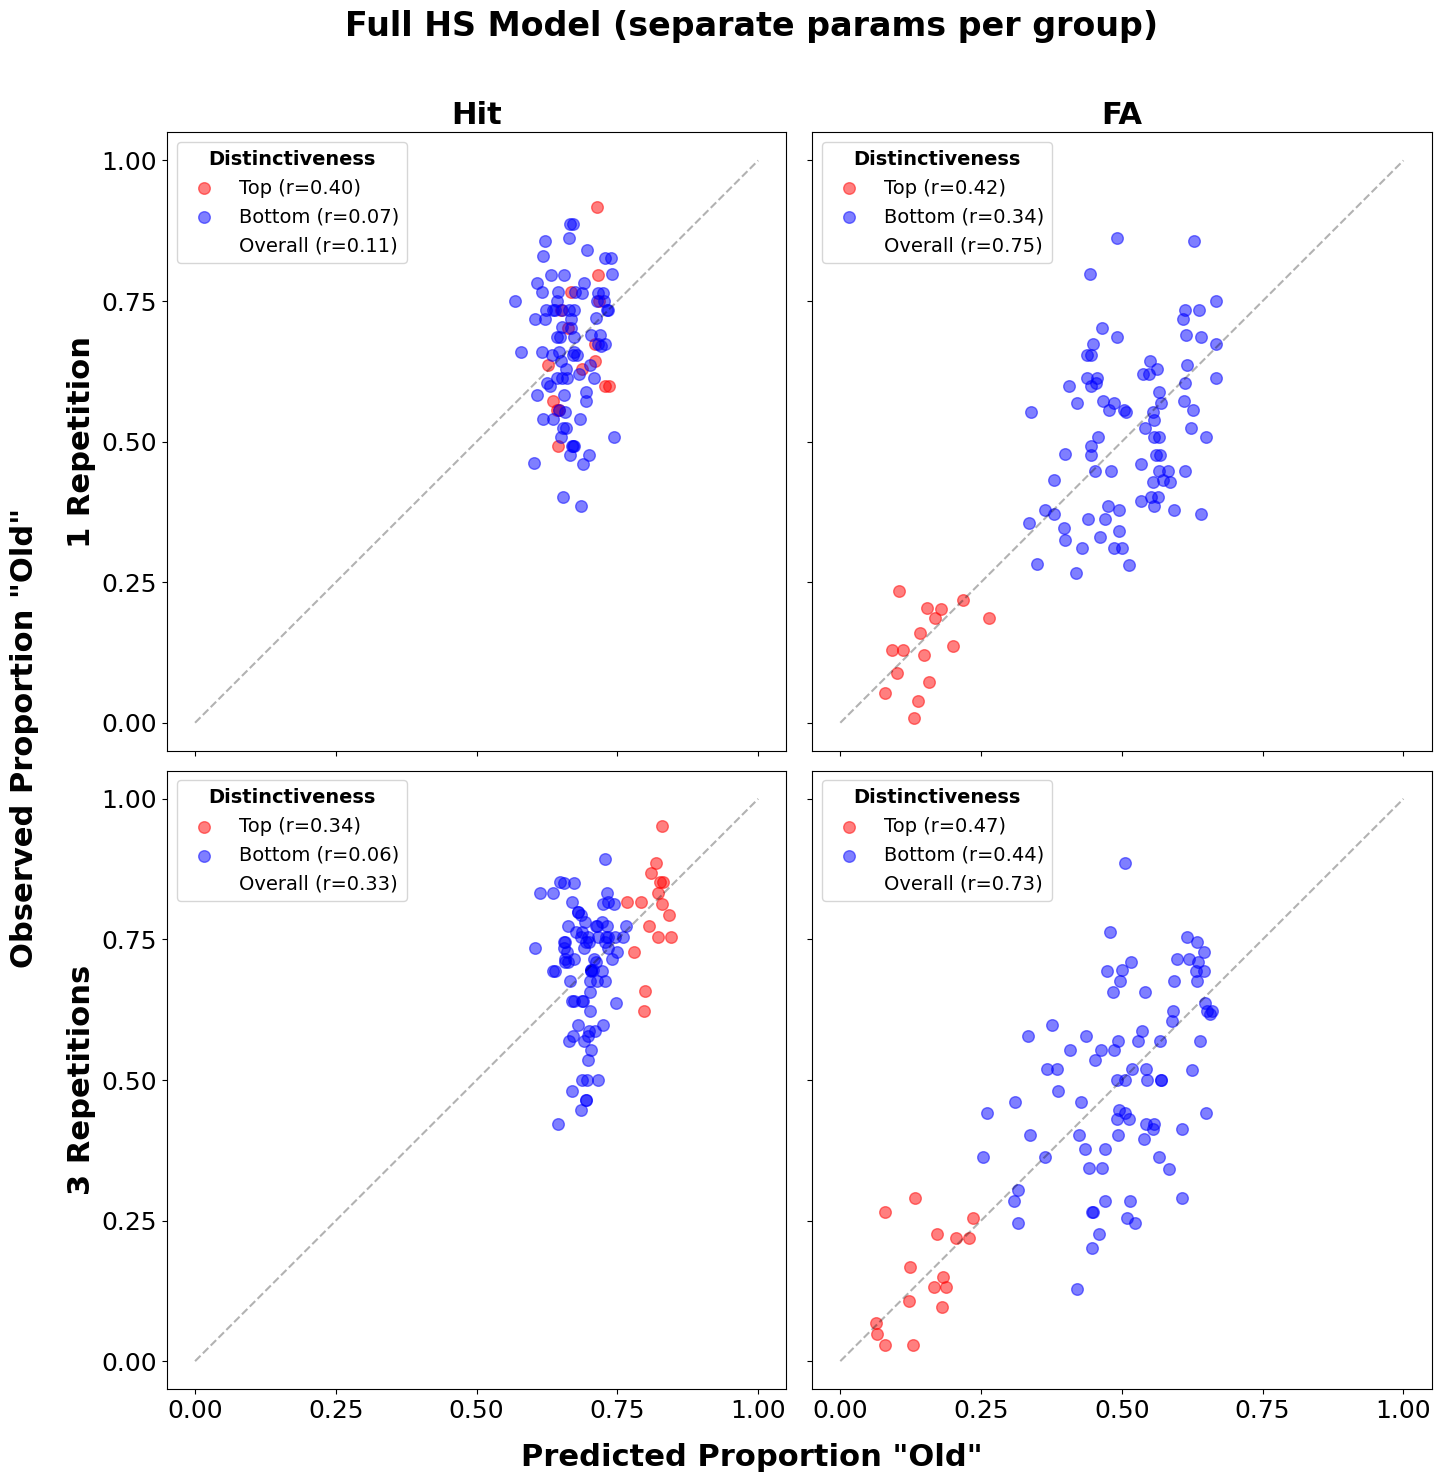

In [82]:
plot_model_fit_by_distinctiveness(df_by_item, 'HS_preds', 'Full HS Model (separate params per group)')

In [83]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'HS_preds', 'Full HS Model')

========== Full HS Model - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.399   0.126
1       Hit        Bottom  0.065   0.557
2       Hit       Overall  0.110   0.277
3        FA           Top  0.423   0.103
4        FA        Bottom  0.343   0.001
5        FA       Overall  0.752  < .001
6   Overall       Overall  0.769  < .001

========== Full HS Model - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.341   0.196
1       Hit        Bottom  0.059   0.594
2       Hit       Overall  0.326  < .001
3        FA           Top  0.474   0.064
4        FA        Bottom  0.443  < .001
5        FA       Overall  0.725  < .001
6   Overall       Overall  0.814  < .001



### HS pooled

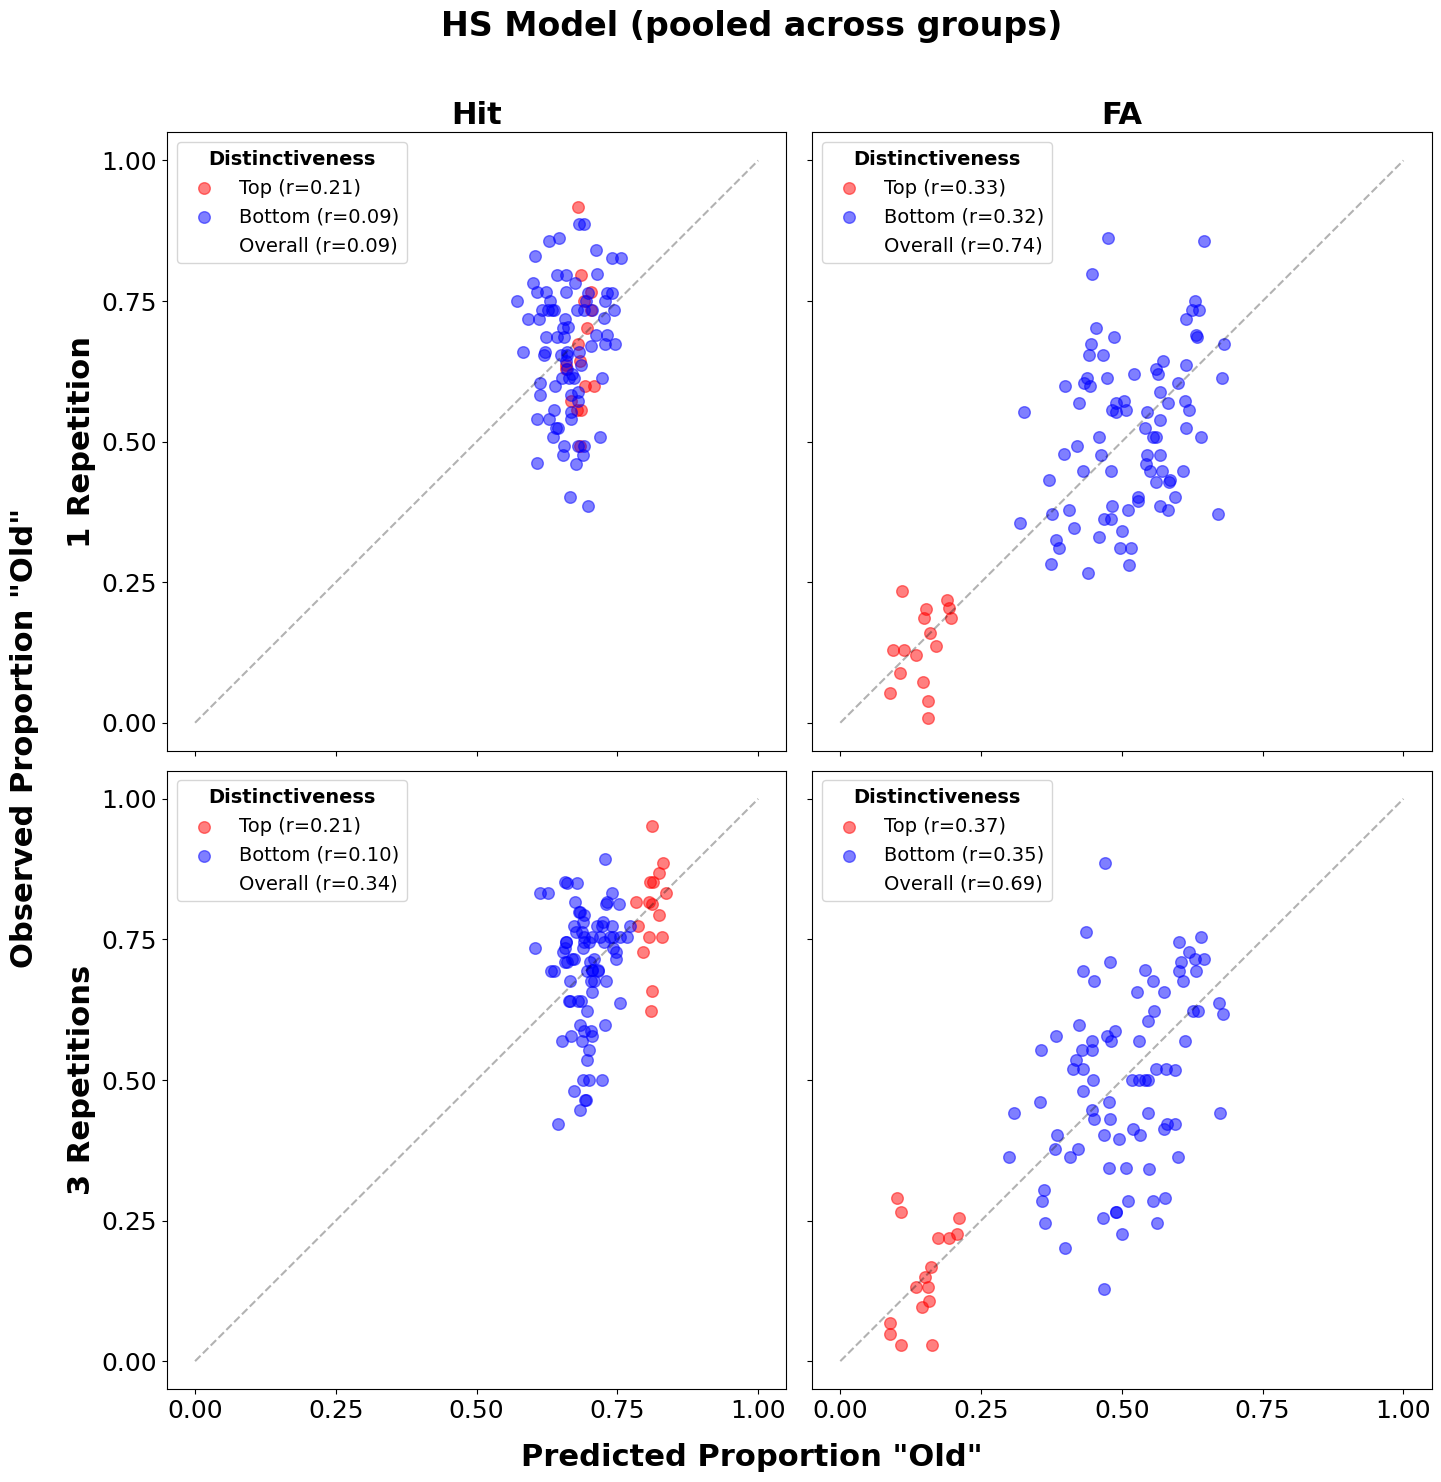

In [84]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

In [85]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

========== HS Model (pooled across groups) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.205   0.445
1       Hit        Bottom  0.092   0.407
2       Hit       Overall  0.092   0.364
3        FA           Top  0.330   0.212
4        FA        Bottom  0.322   0.003
5        FA       Overall  0.745  < .001
6   Overall       Overall  0.763  < .001

========== HS Model (pooled across groups) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.213   0.428
1       Hit        Bottom  0.103   0.353
2       Hit       Overall  0.336  < .001
3        FA           Top  0.369   0.160
4        FA        Bottom  0.355  < .001
5        FA       Overall  0.694  < .001
6   Overall       Overall  0.802  < .001



### Base model

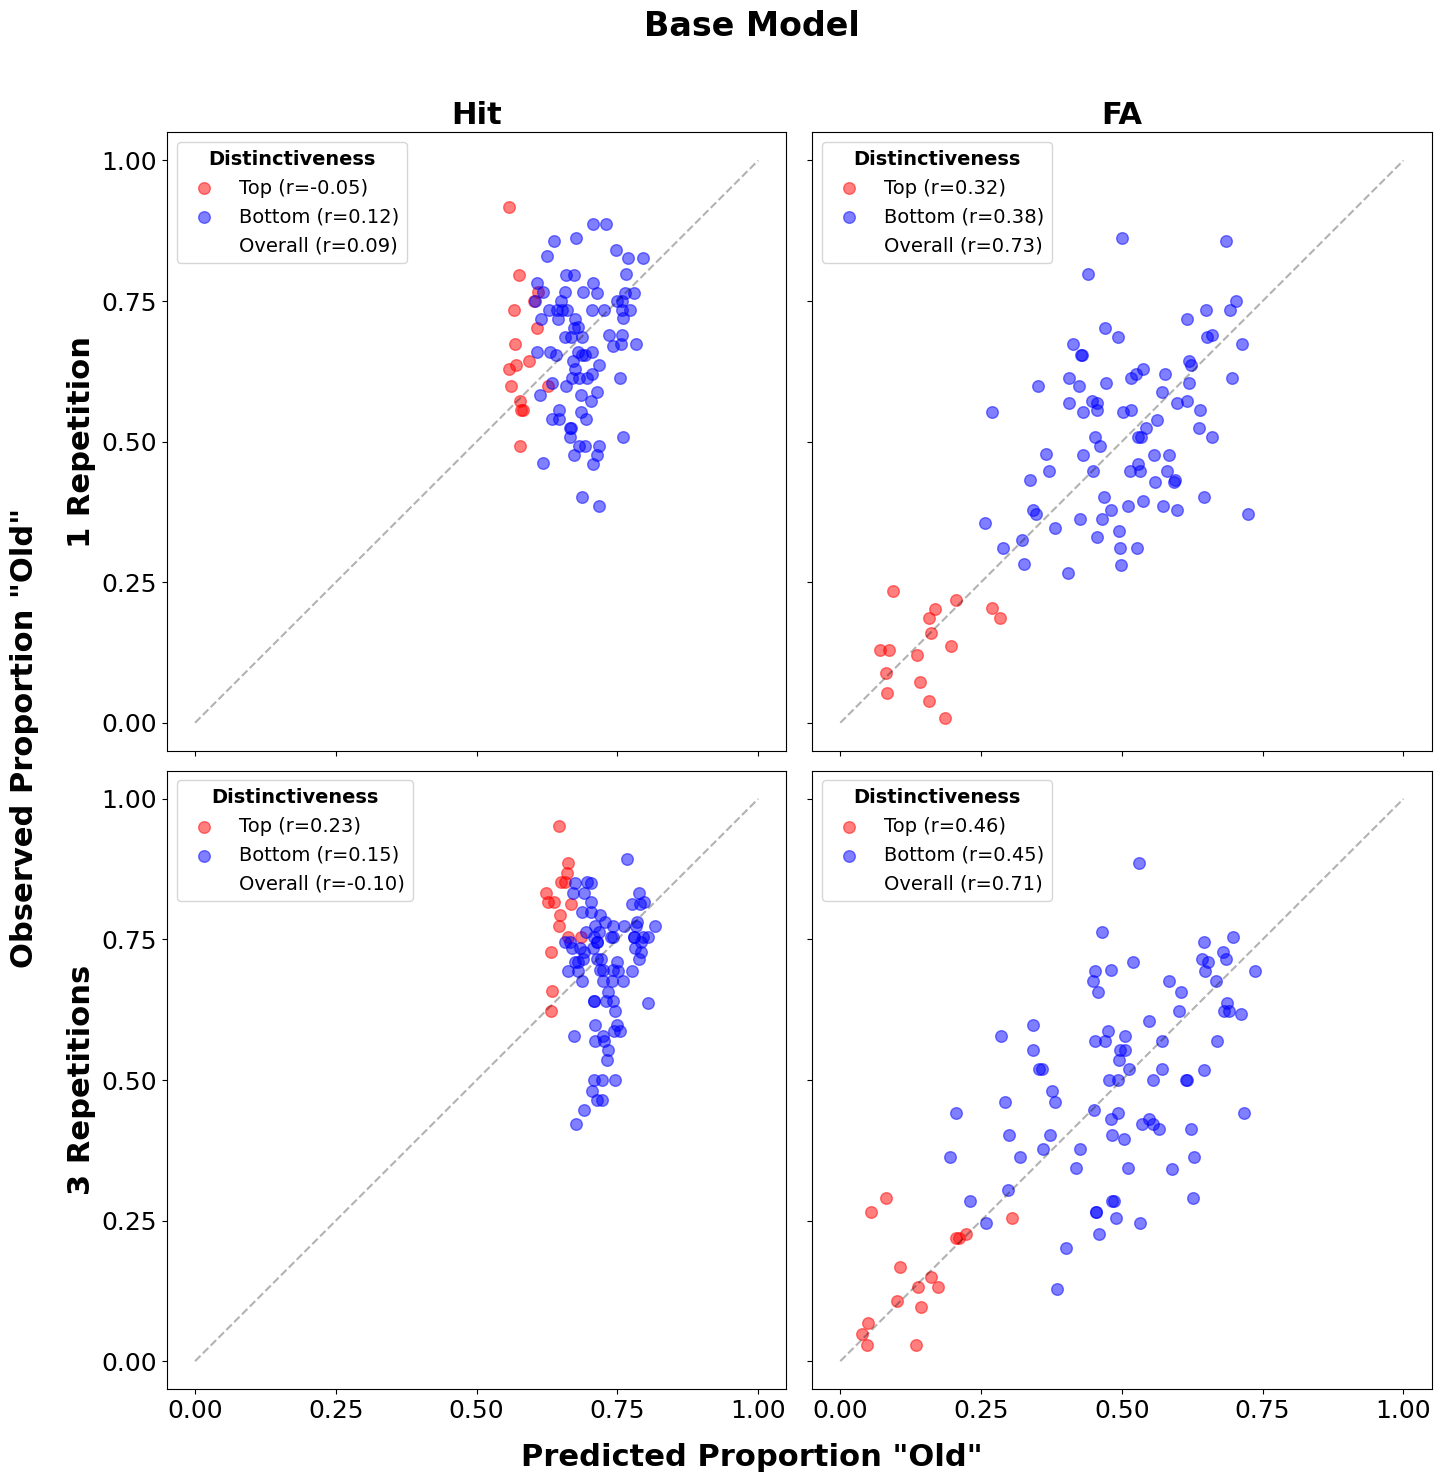

In [86]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

In [87]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

========== Base Model - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top -0.046   0.865
1       Hit        Bottom  0.124   0.262
2       Hit       Overall  0.088   0.382
3        FA           Top  0.320   0.228
4        FA        Bottom  0.375  < .001
5        FA       Overall  0.732  < .001
6   Overall       Overall  0.746  < .001

========== Base Model - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.230   0.391
1       Hit        Bottom  0.150   0.173
2       Hit       Overall -0.104   0.304
3        FA           Top  0.461   0.072
4        FA        Bottom  0.449  < .001
5        FA       Overall  0.711  < .001
6   Overall       Overall  0.778  < .001



### C-within C-between

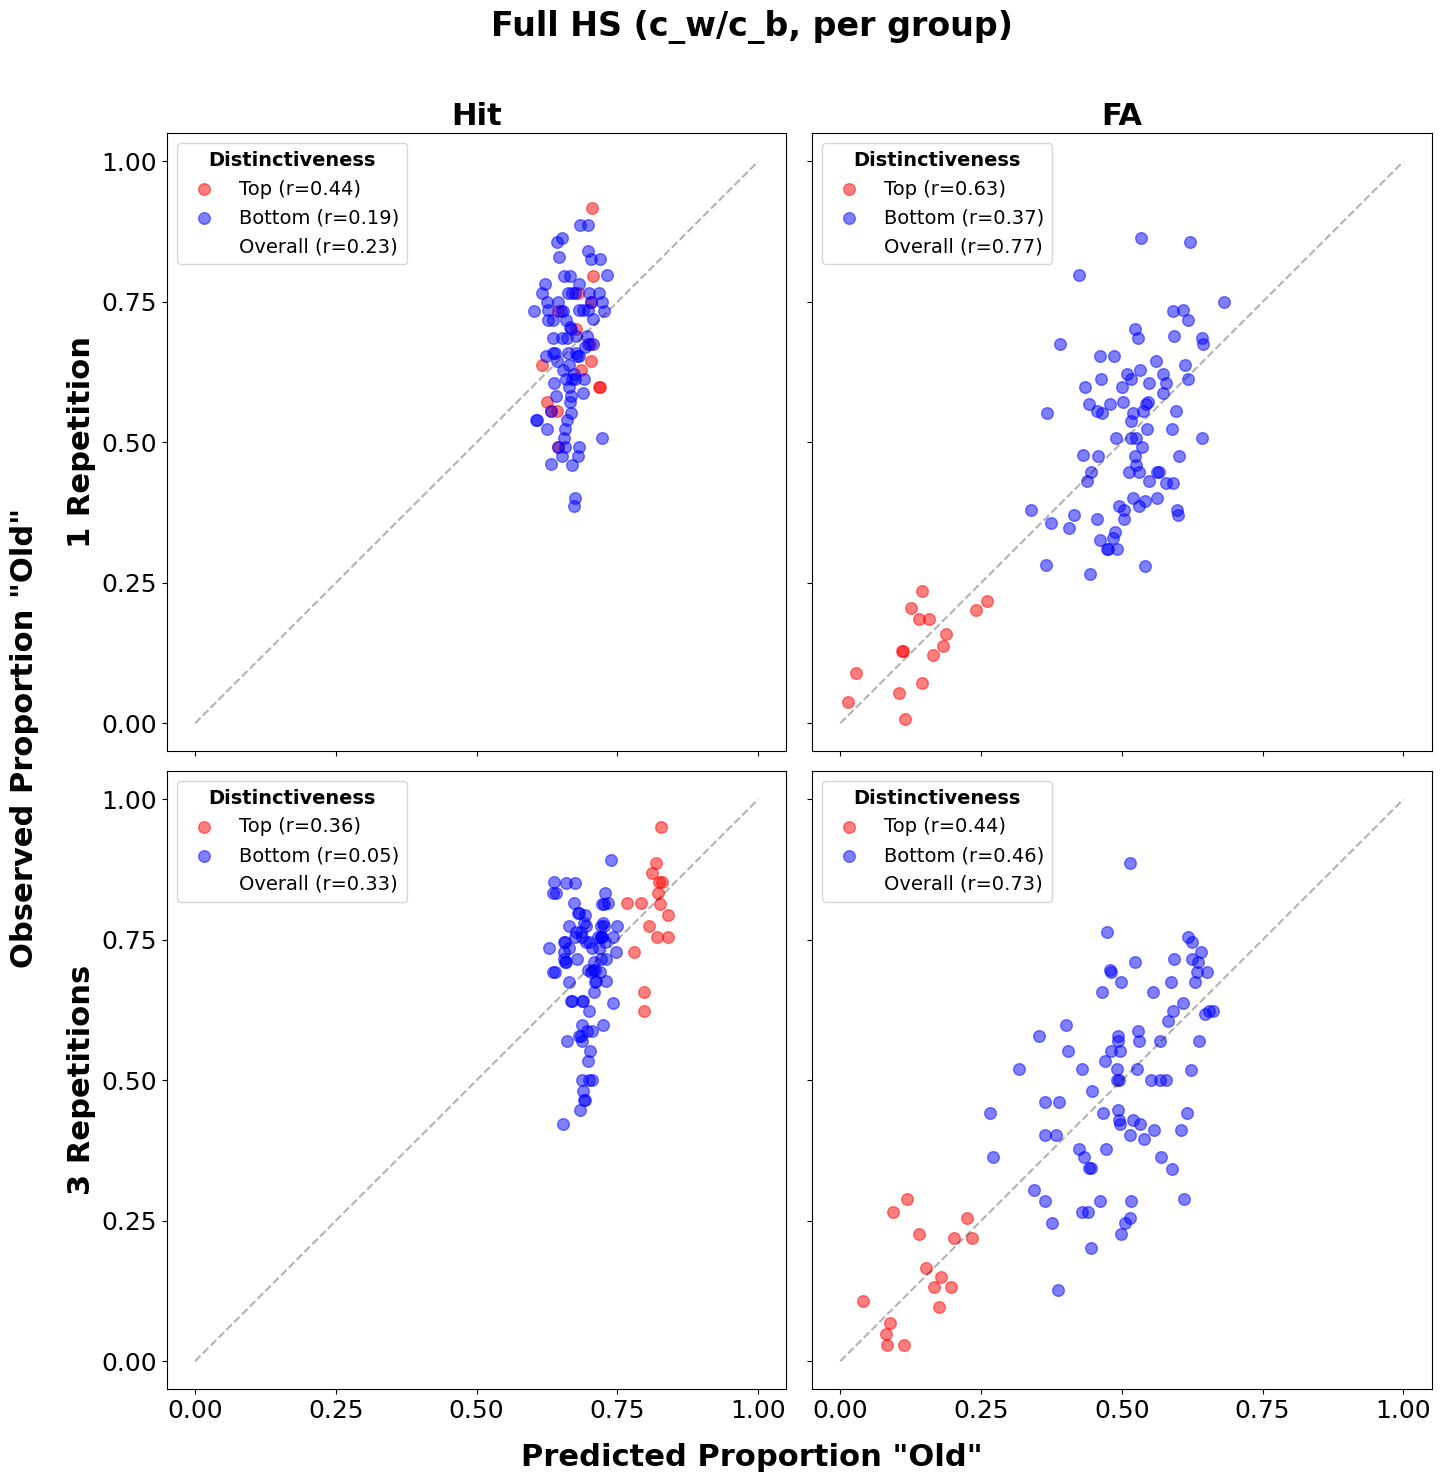

========== Full HS (c_w/c_b, per group) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.444   0.085
1       Hit        Bottom  0.194   0.078
2       Hit       Overall  0.232   0.020
3        FA           Top  0.627   0.009
4        FA        Bottom  0.373  < .001
5        FA       Overall  0.775  < .001
6   Overall       Overall  0.790  < .001

========== Full HS (c_w/c_b, per group) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.357   0.175
1       Hit        Bottom  0.052   0.639
2       Hit       Overall  0.330  < .001
3        FA           Top  0.439   0.089
4        FA        Bottom  0.458  < .001
5        FA       Overall  0.734  < .001
6   Overall       Overall  0.818  < .001



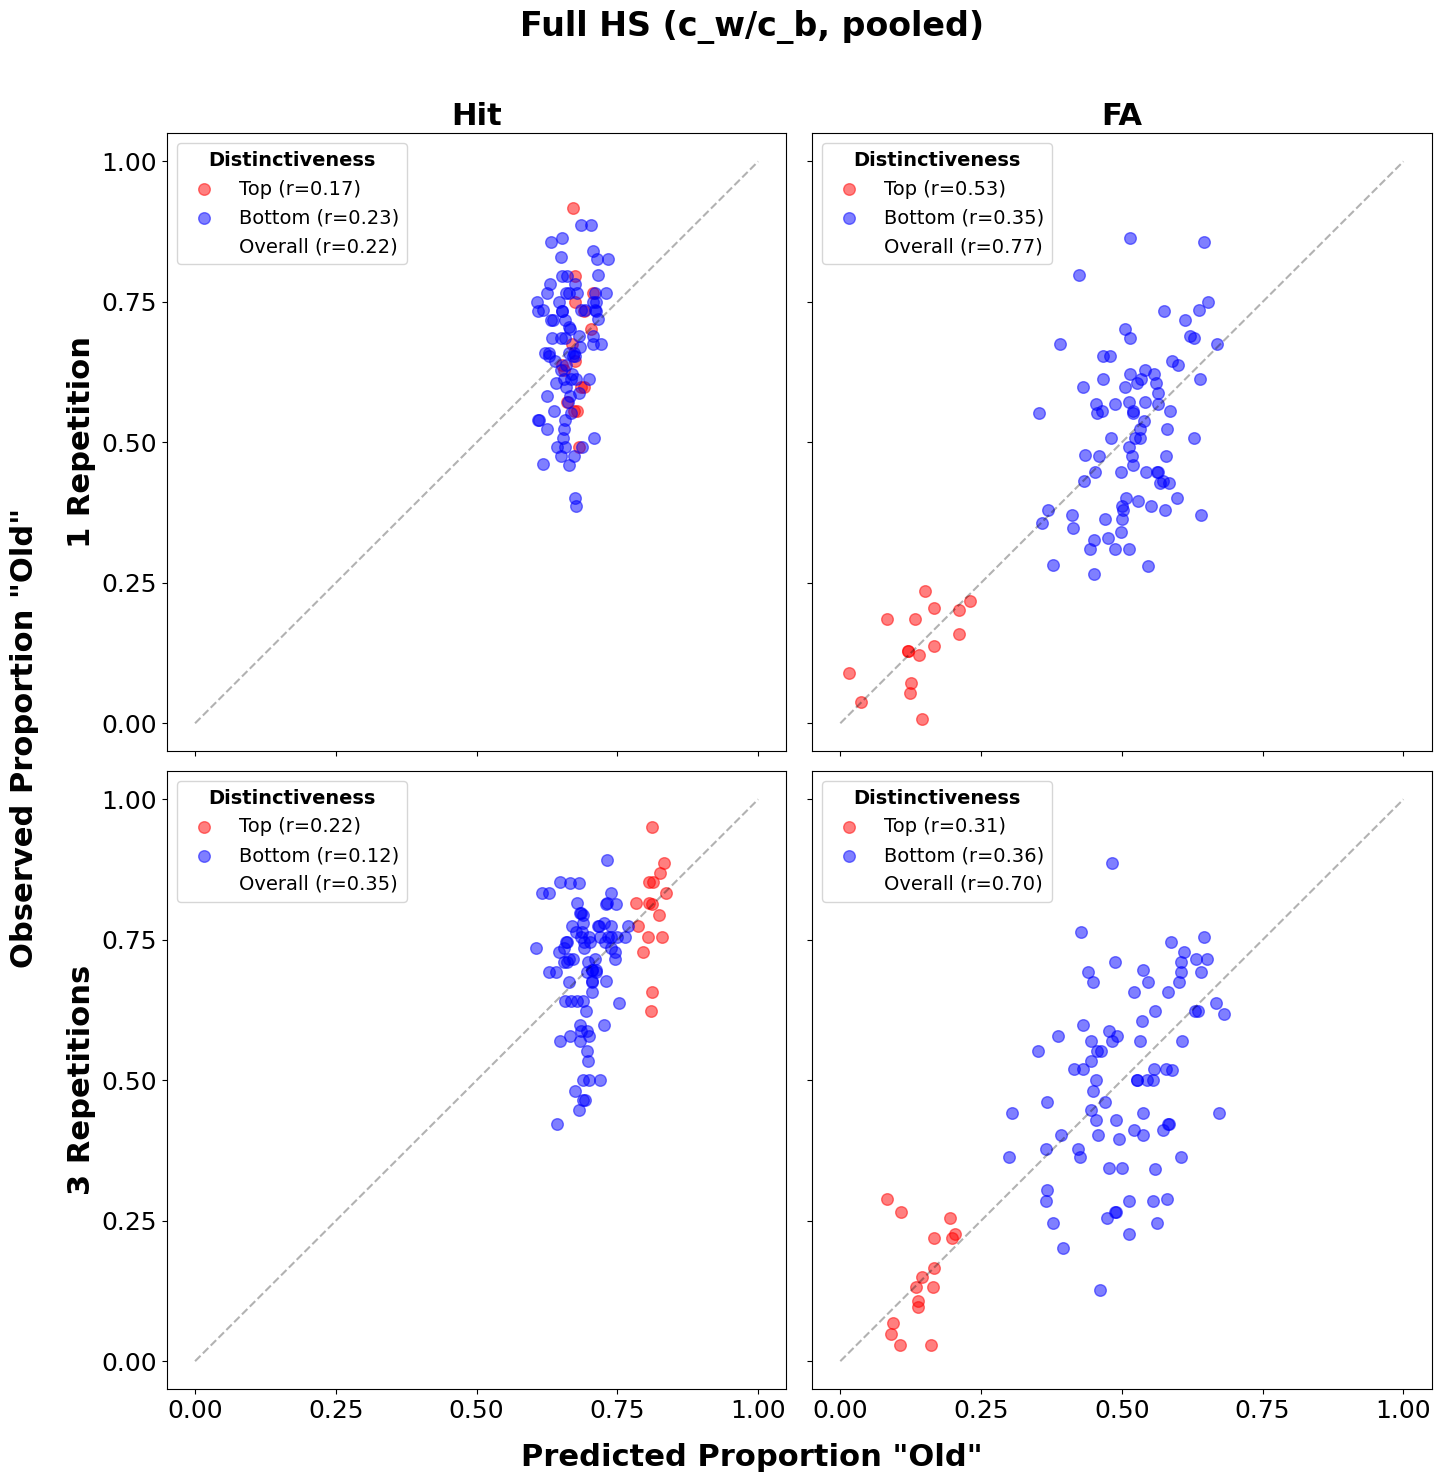

========== Full HS (c_w/c_b, pooled) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.166   0.539
1       Hit        Bottom  0.231   0.034
2       Hit       Overall  0.219   0.029
3        FA           Top  0.527   0.036
4        FA        Bottom  0.354  < .001
5        FA       Overall  0.768  < .001
6   Overall       Overall  0.786  < .001

========== Full HS (c_w/c_b, pooled) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.221   0.411
1       Hit        Bottom  0.122   0.269
2       Hit       Overall  0.347  < .001
3        FA           Top  0.307   0.247
4        FA        Bottom  0.358  < .001
5        FA       Overall  0.696  < .001
6   Overall       Overall  0.803  < .001



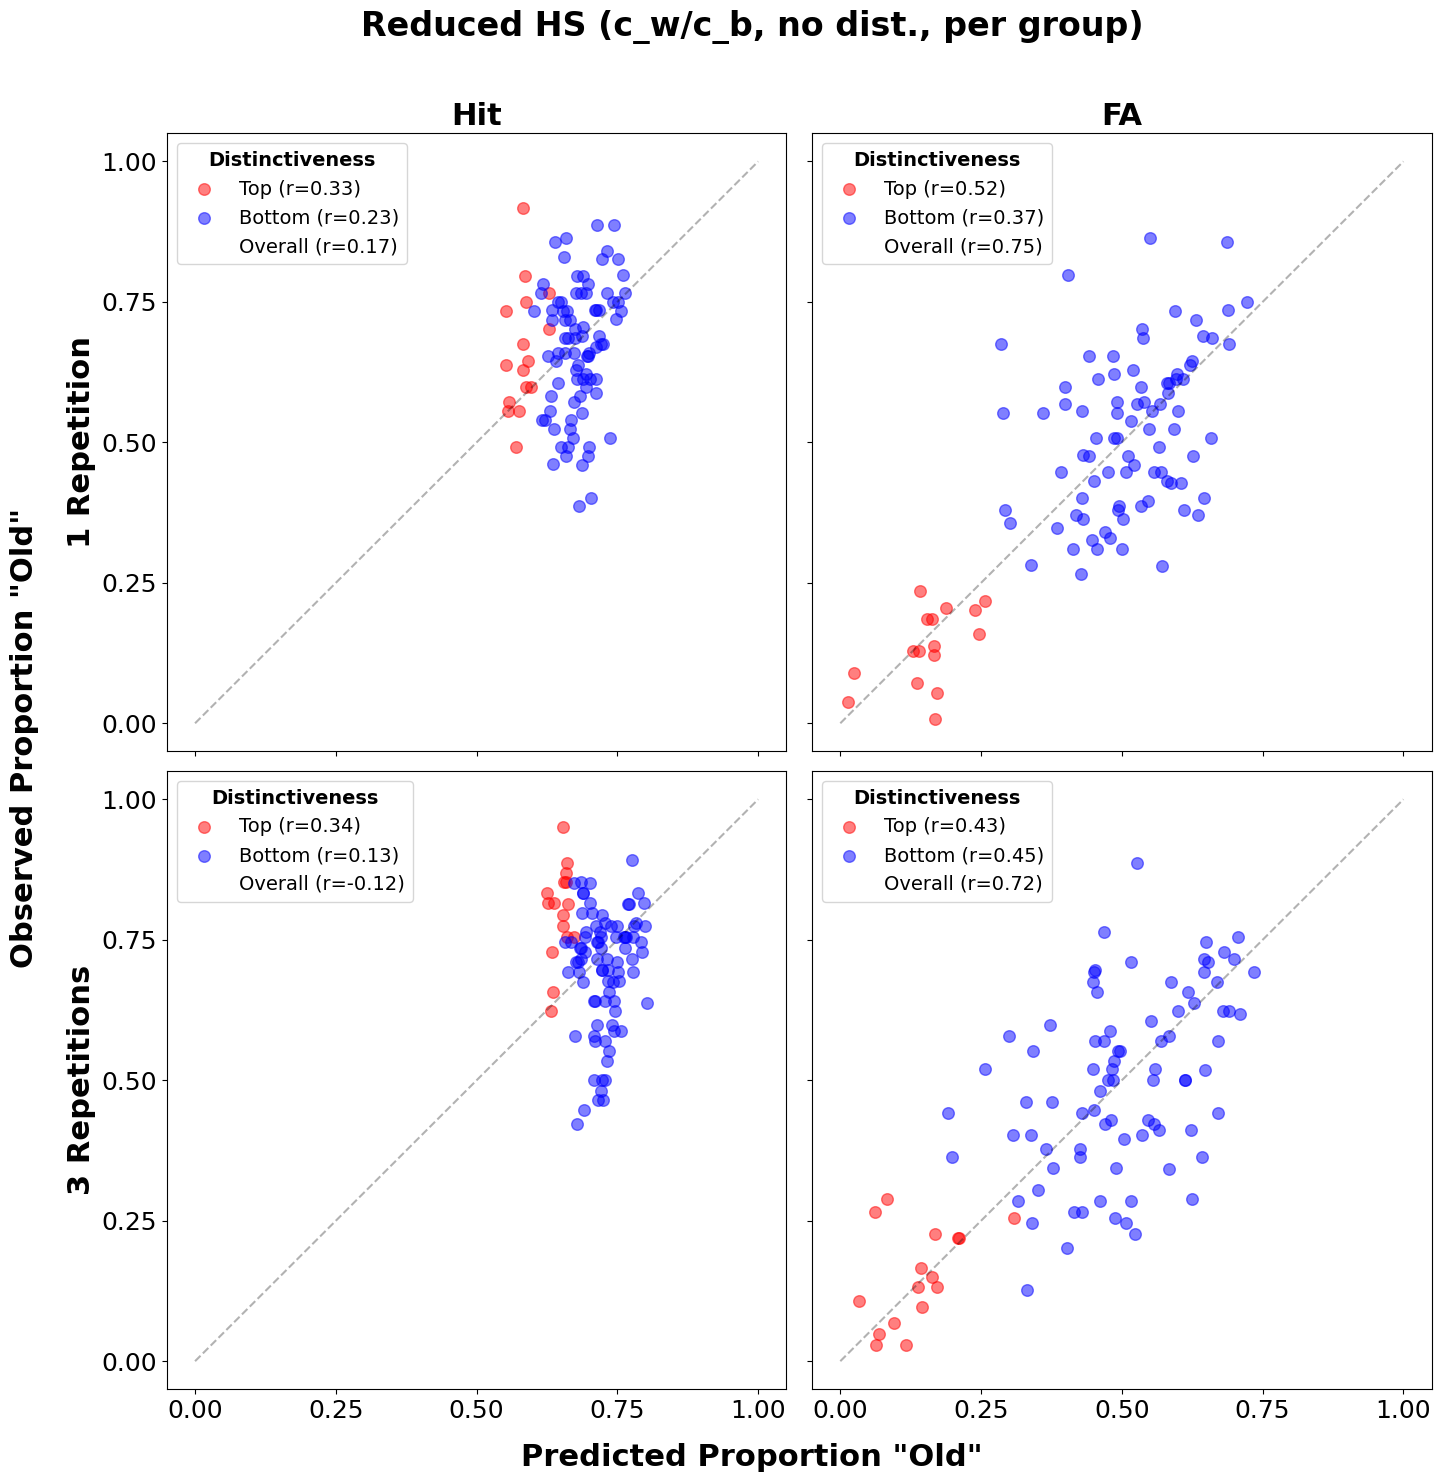

========== Reduced HS (c_w/c_b, no dist., per group) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.332   0.208
1       Hit        Bottom  0.231   0.035
2       Hit       Overall  0.173   0.085
3        FA           Top  0.522   0.038
4        FA        Bottom  0.370  < .001
5        FA       Overall  0.749  < .001
6   Overall       Overall  0.766  < .001

========== Reduced HS (c_w/c_b, no dist., per group) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.336   0.203
1       Hit        Bottom  0.132   0.231
2       Hit       Overall -0.123   0.222
3        FA           Top  0.432   0.095
4        FA        Bottom  0.451  < .001
5        FA       Overall  0.716  < .001
6   Overall       Overall  0.780  < .001



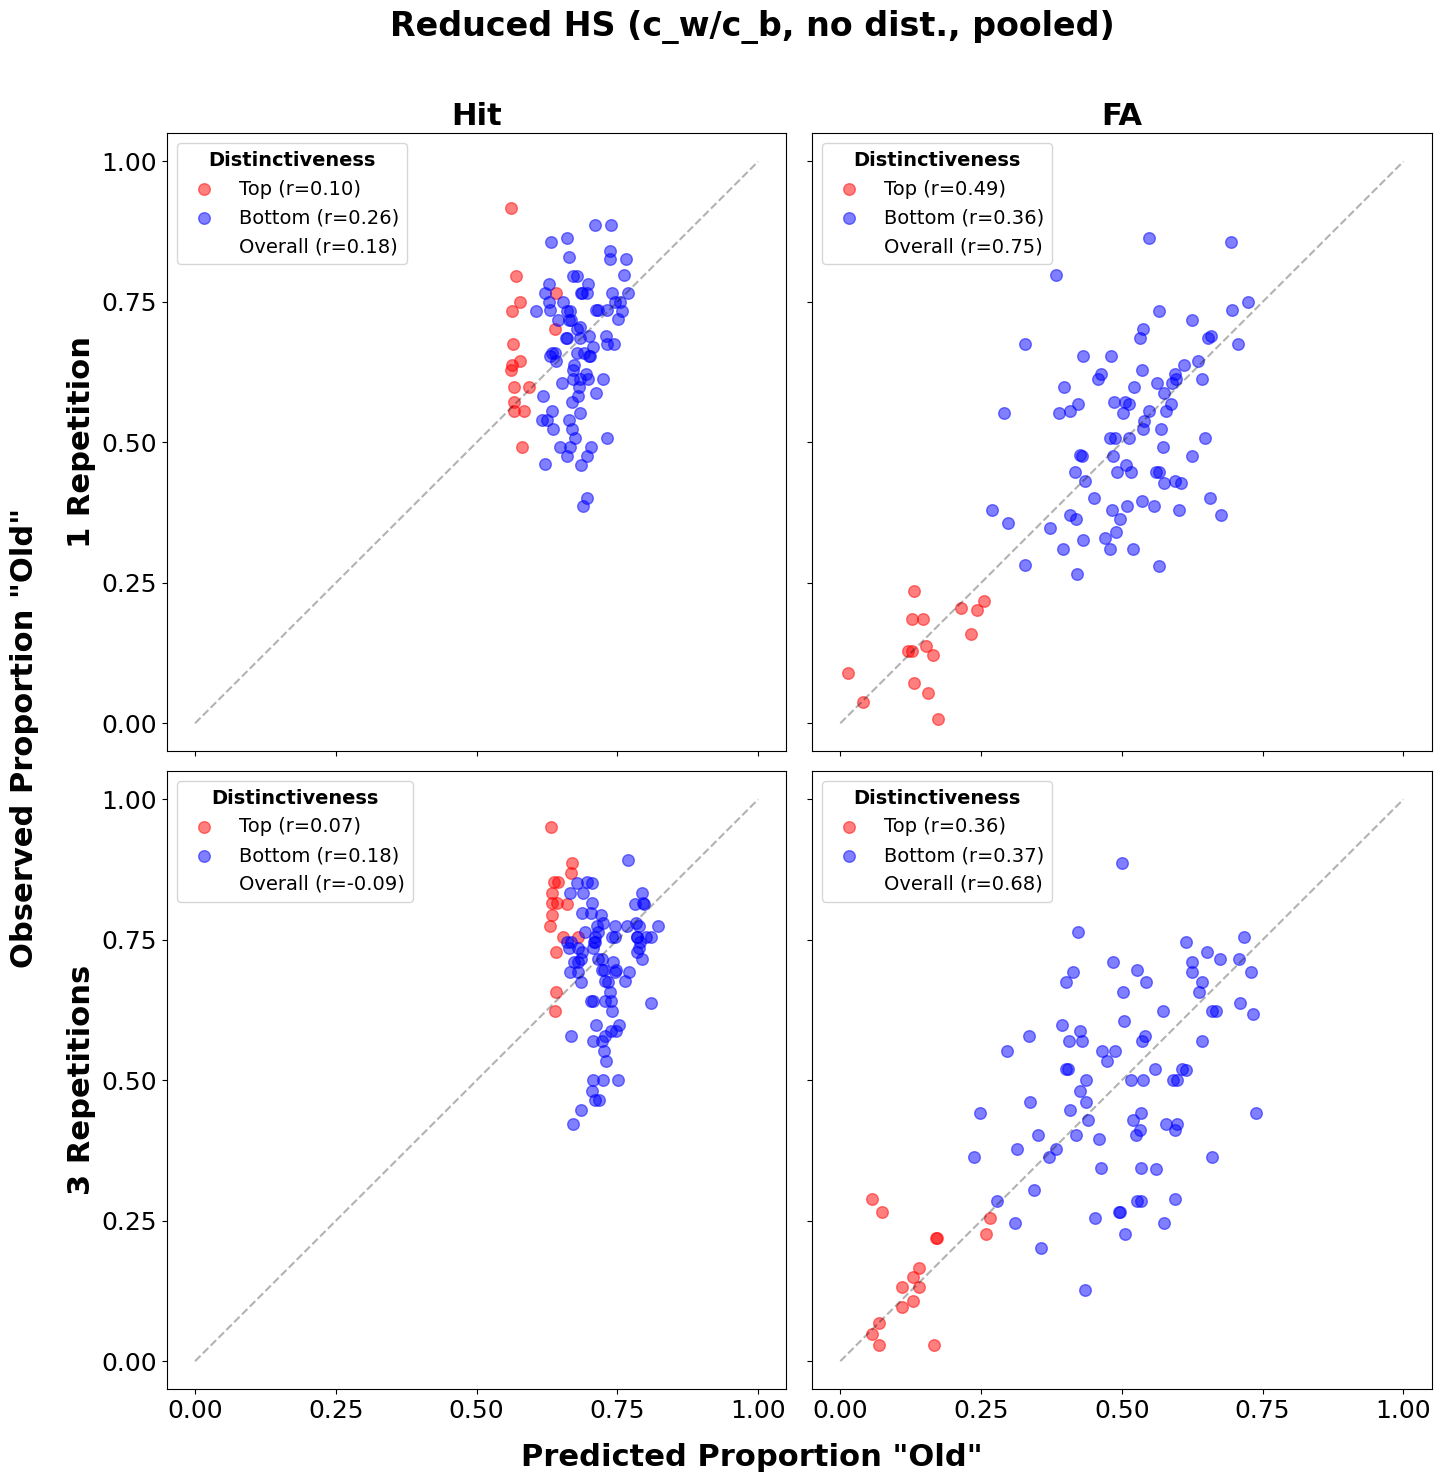

========== Reduced HS (c_w/c_b, no dist., pooled) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.097   0.721
1       Hit        Bottom  0.256   0.019
2       Hit       Overall  0.176   0.081
3        FA           Top  0.488   0.055
4        FA        Bottom  0.364  < .001
5        FA       Overall  0.745  < .001
6   Overall       Overall  0.763  < .001

========== Reduced HS (c_w/c_b, no dist., pooled) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.068   0.802
1       Hit        Bottom  0.176   0.109
2       Hit       Overall -0.090   0.372
3        FA           Top  0.359   0.172
4        FA        Bottom  0.375  < .001
5        FA       Overall  0.683  < .001
6   Overall       Overall  0.765  < .001



In [157]:
new_models = [
    ('HS_cwb_full_group_preds',     'Full HS (c_w/c_b, per group)'),
    ('HS_cwb_full_pooled_preds',    'Full HS (c_w/c_b, pooled)'),
    ('HS_cwb_reduced_group_preds',  'Reduced HS (c_w/c_b, no dist., per group)'),
    ('HS_cwb_reduced_pooled_preds', 'Reduced HS (c_w/c_b, no dist., pooled)'),
]

for col, label in new_models:
    plot_model_fit_by_distinctiveness(df_by_item, col, label)
    compute_model_correlations_by_distinctiveness(df_by_item, col, label)

## H vs FA

In [160]:
def plot_hit_fa_cross_correlations(df_by_item, pred_col, model_label):
    conditions = ['1_Rep', '3_Rep']   # top row, bottom row

    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True, sharex=True)

    distinct_groups = {'Top': 'High', 'Bottom': 'Low'}
    colors = ['red', 'blue']

    # font sizes
    fs = 22
    fs_axes = 18
    fs_legend = 15

    lims = [-0.05, 1.05]

    for row_idx, condition in enumerate(conditions):

        # For overall correlations (per subplot)
        x_all_0, y_all_0 = [], []
        x_all_1, y_all_1 = [], []

        for color, distinct in zip(colors, distinct_groups):

            dist_name = distinct_groups[distinct]

            # ---------- Set A (left column) ----------
            ax_left = axes[row_idx, 0]

            x = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == 'Group2') &
                (df_by_item['resp_type'] == 'FA') &
                (df_by_item['condition'] == condition),
                pred_col
            ].reset_index(drop=True)

            y = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == 'Group1') &
                (df_by_item['resp_type'] == 'Hit') &
                (df_by_item['condition'] == condition),
                pred_col
            ].reset_index(drop=True)

            mask = ~(x.isna() | y.isna())
            r = x[mask].corr(y[mask])

            ax_left.scatter(
                x, y, alpha=0.5, edgecolor="k", color=color, s=100,
                label=f"{dist_name} (r = {r:.3f})"
            )

            # ---------- Set B (right column) ----------
            ax_right = axes[row_idx, 1]

            x_rev = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == 'Group1') &
                (df_by_item['resp_type'] == 'FA') &
                (df_by_item['condition'] == condition),
                pred_col
            ].reset_index(drop=True)

            y_rev = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == 'Group2') &
                (df_by_item['resp_type'] == 'Hit') &
                (df_by_item['condition'] == condition),
                pred_col
            ].reset_index(drop=True)

            mask_rev = ~(x_rev.isna() | y_rev.isna())
            r_rev = x_rev[mask_rev].corr(y_rev[mask_rev])

            ax_right.scatter(
                x_rev, y_rev, alpha=0.5, edgecolor="k", color=color, s=100,
                label=f"{dist_name} (r = {r_rev:.3f})"
            )

            # accumulate for overall correlations
            x_all_0.append(x)
            y_all_0.append(y)
            x_all_1.append(x_rev)
            y_all_1.append(y_rev)

        # ---------- Overall correlations ----------
        x0 = pd.concat(x_all_0, ignore_index=True)
        y0 = pd.concat(y_all_0, ignore_index=True)
        x1 = pd.concat(x_all_1, ignore_index=True)
        y1 = pd.concat(y_all_1, ignore_index=True)

        mask0 = ~(x0.isna() | y0.isna())
        mask1 = ~(x1.isna() | y1.isna())

        r0 = x0[mask0].corr(y0[mask0])
        r1 = x1[mask1].corr(y1[mask1])

        overall_handle_0 = Line2D([], [], linestyle='None',
                                  label=f"Overall (r = {r0:.3f})")
        overall_handle_1 = Line2D([], [], linestyle='None',
                                  label=f"Overall (r = {r1:.3f})")

        # ---------- Formatting per row ----------
        for col in range(2):
            ax = axes[row_idx, col]
            ax.plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
            ax.set_xlim(lims)
            ax.set_ylim(lims)
            ax.set_xticks(np.arange(0, 1.1, 0.25))
            ax.set_yticks(np.arange(0, 1.1, 0.25))
            ax.tick_params(axis='both', labelsize=fs_axes)

        # titles per row
        axes[row_idx, 0].set_title(f'Set A — {condition}', fontsize=fs, fontweight='bold')
        axes[row_idx, 1].set_title(f'Set B — {condition}', fontsize=fs, fontweight='bold')

        # legends
        handles0, labels0 = axes[row_idx, 0].get_legend_handles_labels()
        axes[row_idx, 0].legend(
            handles0 + [overall_handle_0],
            labels0 + [overall_handle_0.get_label()],
            title="Distinctiveness",
            fontsize=fs_legend,
            title_fontsize=fs_legend,
            loc='lower right'
        )
        axes[row_idx, 0].get_legend().get_title().set_fontweight('bold')

        handles1, labels1 = axes[row_idx, 1].get_legend_handles_labels()
        axes[row_idx, 1].legend(
            handles1 + [overall_handle_1],
            labels1 + [overall_handle_1.get_label()],
            title="Distinctiveness",
            fontsize=fs_legend,
            title_fontsize=fs_legend,
            loc='lower right'
        )
        axes[row_idx, 1].get_legend().get_title().set_fontweight('bold')

    # labels
    axes[0, 0].set_ylabel('Hit group 1', fontweight='bold', fontsize=fs)
    axes[0, 0].set_xlabel('FA group 2', fontweight='bold', fontsize=fs)
    axes[1, 0].set_ylabel('Hit group 1', fontweight='bold', fontsize=fs)
    axes[1, 0].set_xlabel('FA group 2', fontweight='bold', fontsize=fs)

    axes[0, 1].set_ylabel('Hit group 2', fontweight='bold', fontsize=fs)
    axes[0, 1].set_xlabel('FA group 1', fontweight='bold', fontsize=fs)
    axes[1, 1].set_ylabel('Hit group 2', fontweight='bold', fontsize=fs)
    axes[1, 1].set_xlabel('FA group 1', fontweight='bold', fontsize=fs)

    fig.suptitle(f'{model_label} predictions', fontsize=fs + 2, fontweight='bold')

    plt.tight_layout()
    plt.show()

### HS model

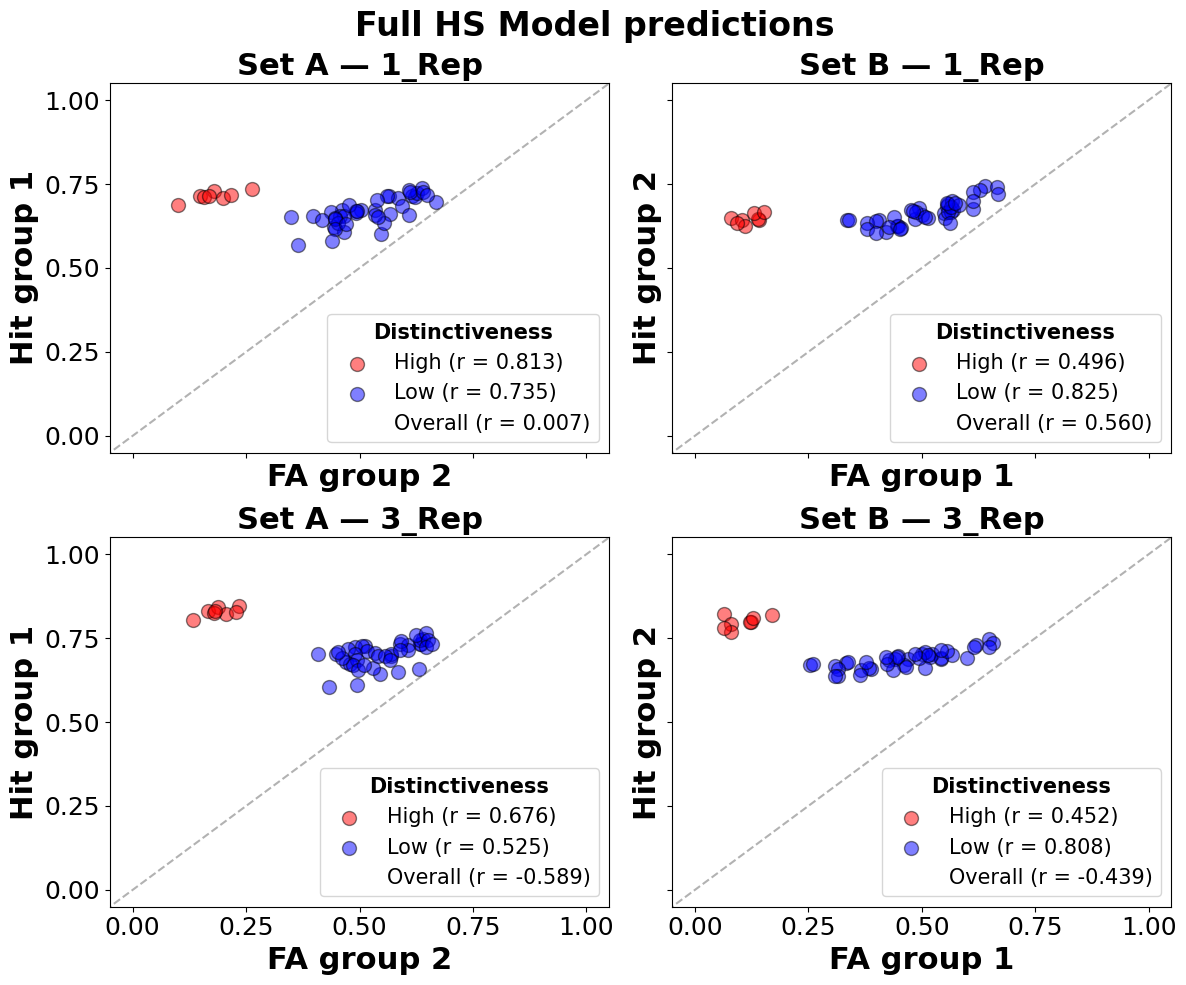

In [89]:
plot_hit_fa_cross_correlations(df_by_item, 'HS_preds', 'Full HS Model')

In [90]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='HS_preds')

Column: HS_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.81, p = 0.014, n = 8
  Bottom: r = 0.74, p = 0.000, n = 42
  Overall: r = 0.01, p = 0.961, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.50, p = 0.211, n = 8
  Bottom: r = 0.82, p = 0.000, n = 42
  Overall: r = 0.56, p = 0.000, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.68, p = 0.066, n = 8
  Bottom: r = 0.53, p = 0.000, n = 42
  Overall: r = -0.59, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.45, p = 0.261, n = 8
  Bottom: r = 0.81, p = 0.000, n = 42
  Overall: r = -0.44, p = 0.001, n = 50


### HS pooled

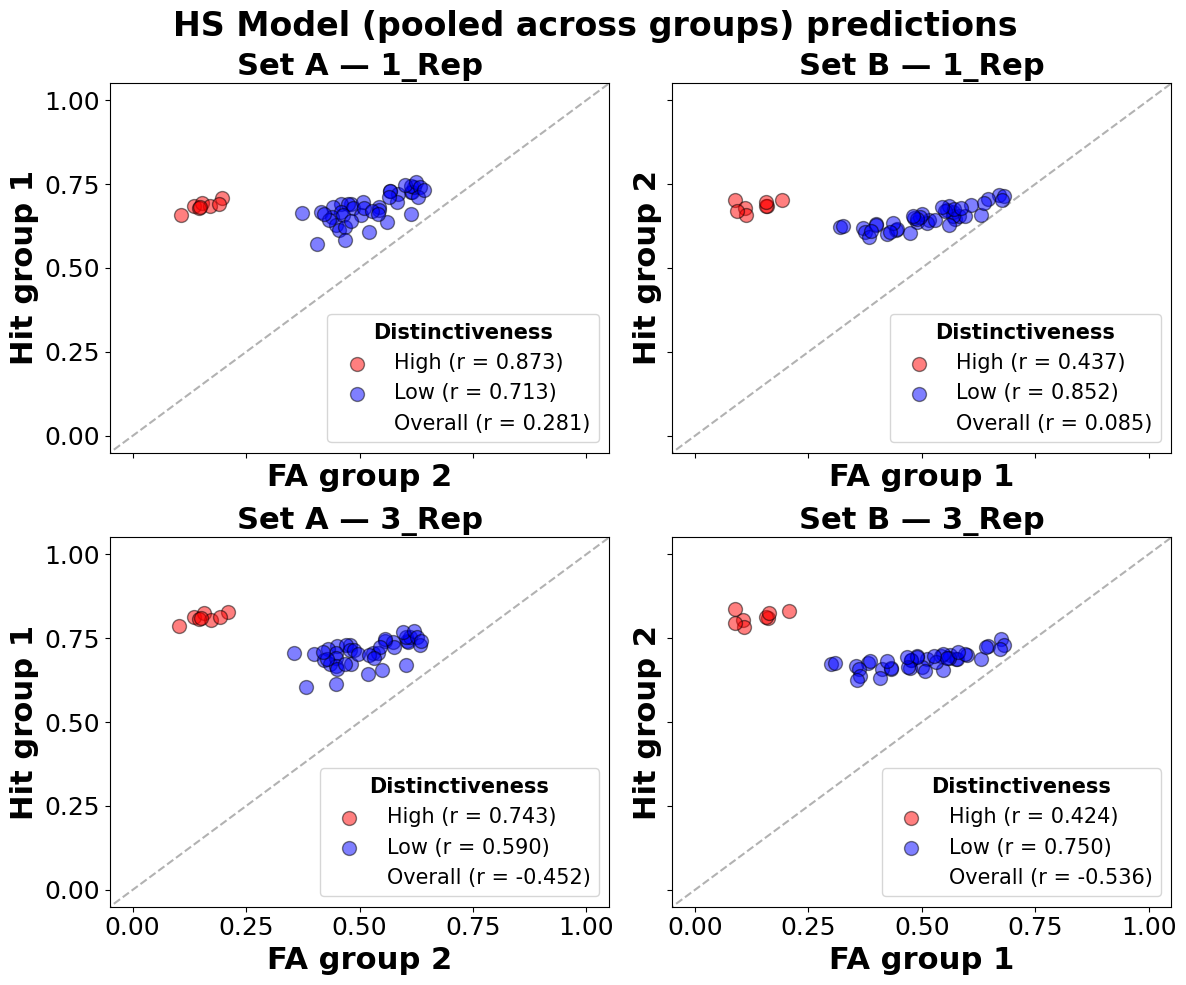

In [91]:
plot_hit_fa_cross_correlations(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

In [92]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='HS_pooled_groups_preds')

Column: HS_pooled_groups_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.87, p = 0.005, n = 8
  Bottom: r = 0.71, p = 0.000, n = 42
  Overall: r = 0.28, p = 0.048, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.44, p = 0.278, n = 8
  Bottom: r = 0.85, p = 0.000, n = 42
  Overall: r = 0.08, p = 0.558, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.74, p = 0.035, n = 8
  Bottom: r = 0.59, p = 0.000, n = 42
  Overall: r = -0.45, p = 0.001, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.42, p = 0.295, n = 8
  Bottom: r = 0.75, p = 0.000, n = 42
  Overall: r = -0.54, p = 0.000, n = 50


### Base model

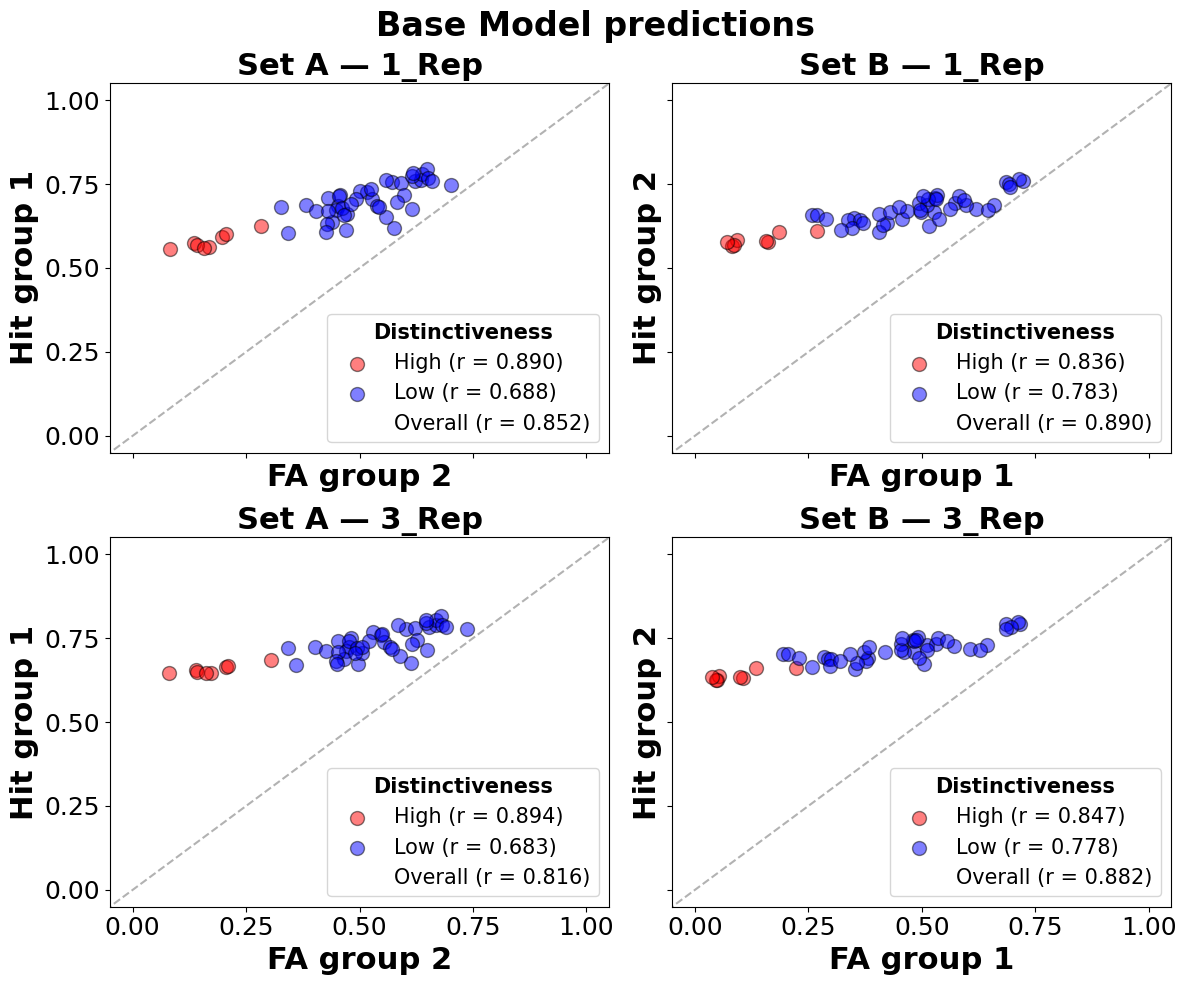

In [93]:
plot_hit_fa_cross_correlations(df_by_item, 'Base_preds', 'Base Model')

In [94]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='Base_preds')

Column: Base_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.89, p = 0.003, n = 8
  Bottom: r = 0.69, p = 0.000, n = 42
  Overall: r = 0.85, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.84, p = 0.010, n = 8
  Bottom: r = 0.78, p = 0.000, n = 42
  Overall: r = 0.89, p = 0.000, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.89, p = 0.003, n = 8
  Bottom: r = 0.68, p = 0.000, n = 42
  Overall: r = 0.82, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.85, p = 0.008, n = 8
  Bottom: r = 0.78, p = 0.000, n = 42
  Overall: r = 0.88, p = 0.000, n = 50


### C-within, c-between

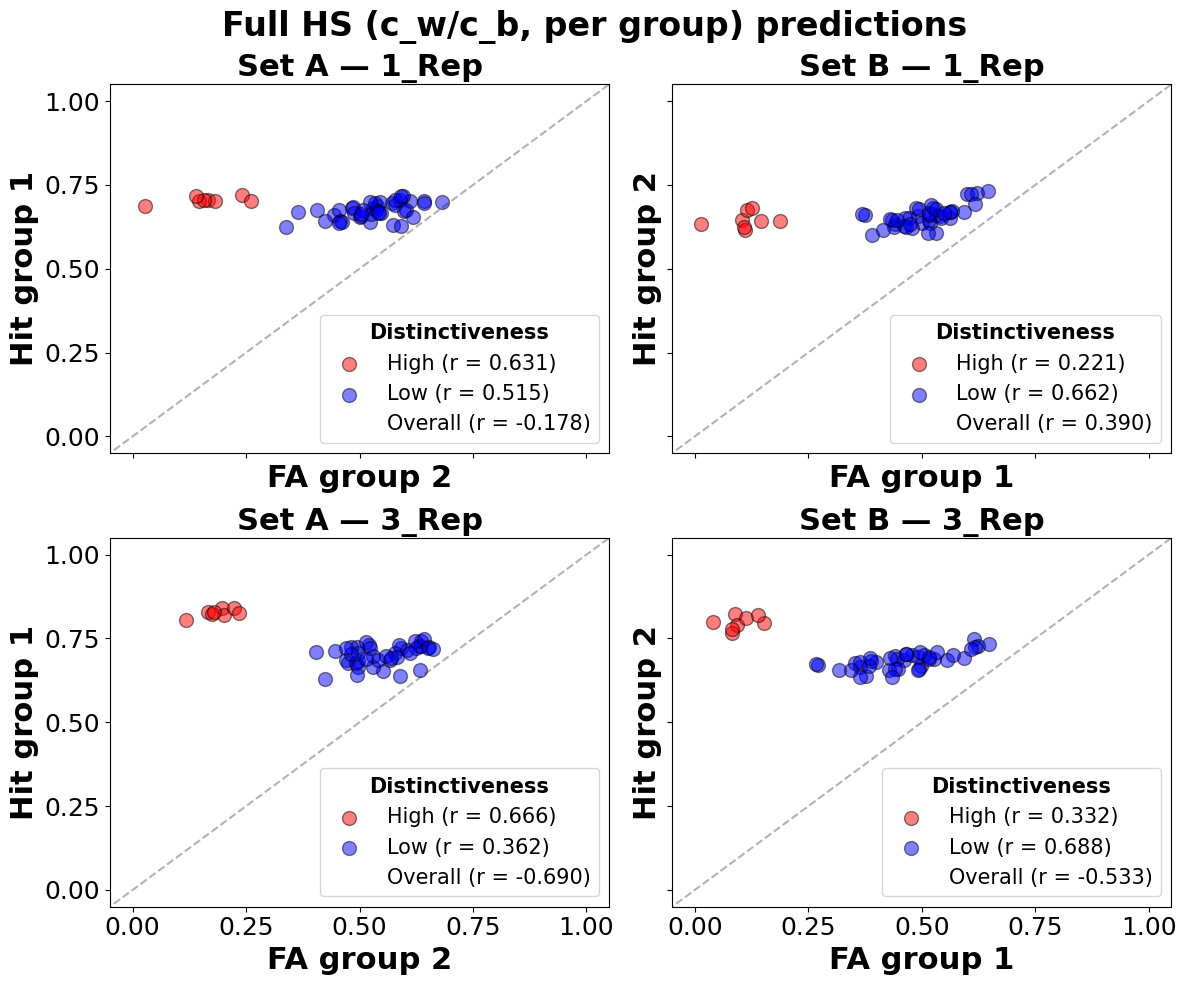

Column: HS_cwb_full_group_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.63, p = 0.093, n = 8
  Bottom: r = 0.52, p = 0.000, n = 42
  Overall: r = -0.18, p = 0.215, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.22, p = 0.599, n = 8
  Bottom: r = 0.66, p = 0.000, n = 42
  Overall: r = 0.39, p = 0.005, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.67, p = 0.072, n = 8
  Bottom: r = 0.36, p = 0.018, n = 42
  Overall: r = -0.69, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.33, p = 0.422, n = 8
  Bottom: r = 0.69, p = 0.000, n = 42
  Overall: r = -0.53, p = 0.000, n = 50


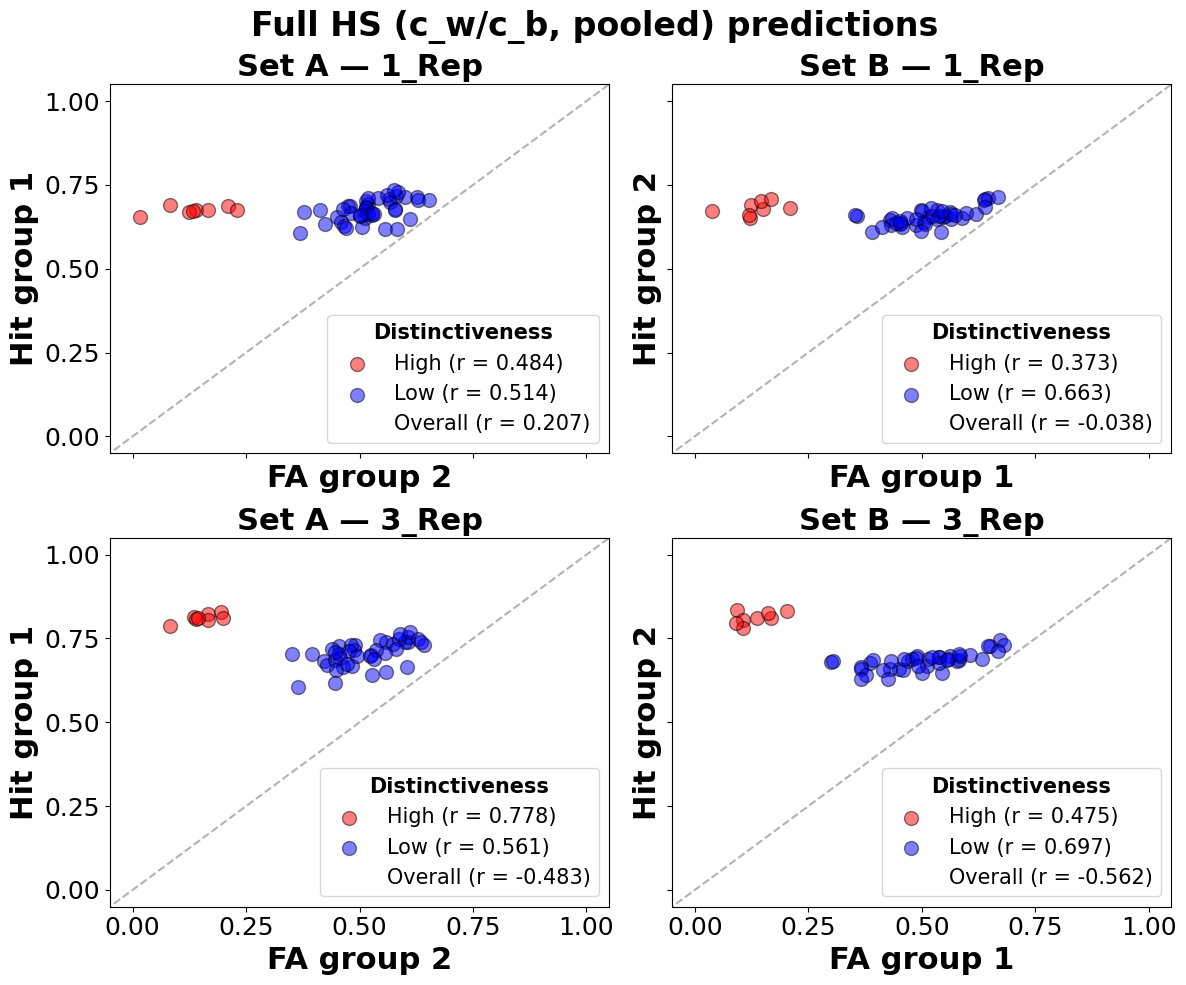

Column: HS_cwb_full_pooled_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.48, p = 0.224, n = 8
  Bottom: r = 0.51, p = 0.001, n = 42
  Overall: r = 0.21, p = 0.149, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.37, p = 0.363, n = 8
  Bottom: r = 0.66, p = 0.000, n = 42
  Overall: r = -0.04, p = 0.793, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.78, p = 0.023, n = 8
  Bottom: r = 0.56, p = 0.000, n = 42
  Overall: r = -0.48, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.47, p = 0.234, n = 8
  Bottom: r = 0.70, p = 0.000, n = 42
  Overall: r = -0.56, p = 0.000, n = 50


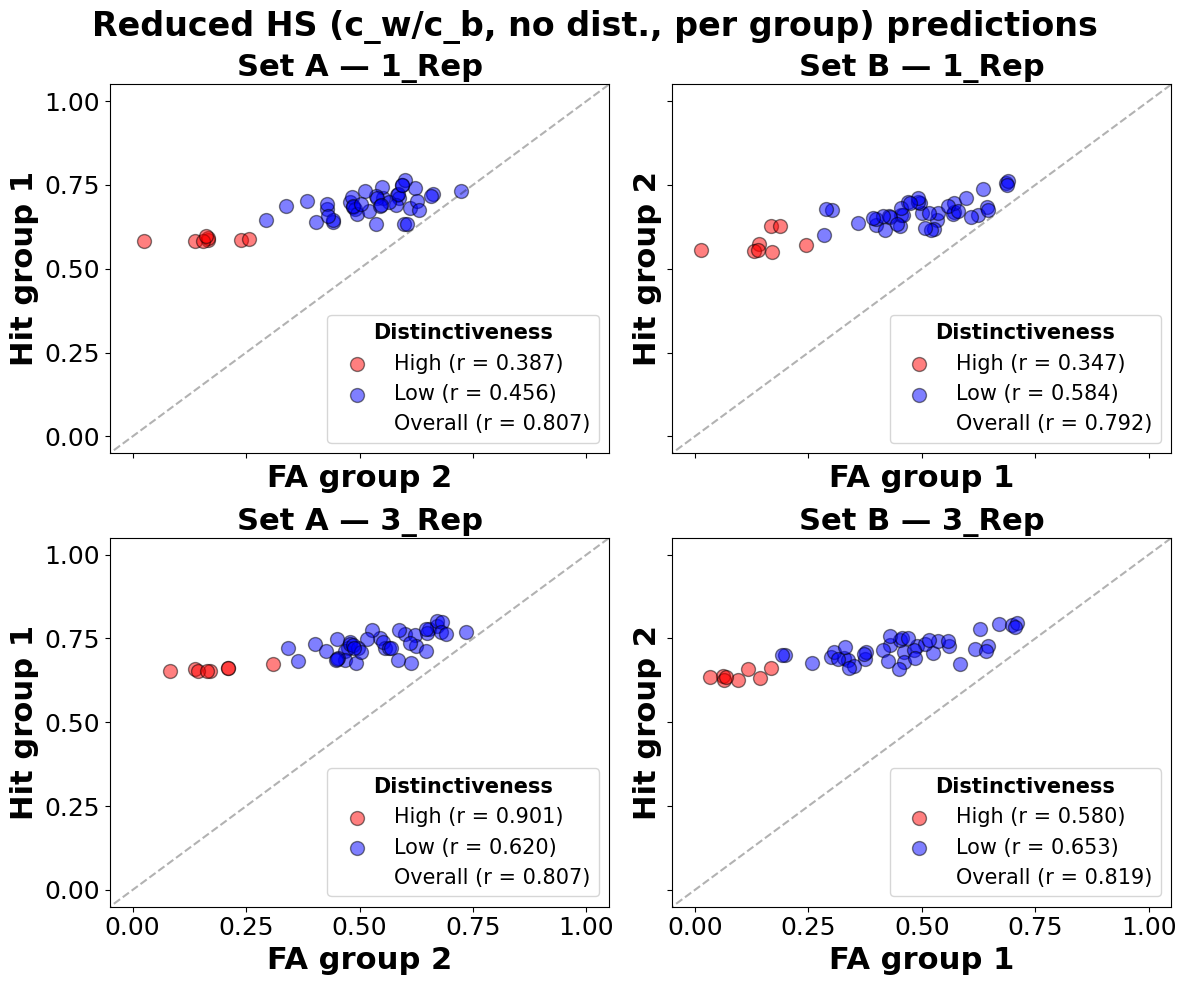

Column: HS_cwb_reduced_group_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.39, p = 0.344, n = 8
  Bottom: r = 0.46, p = 0.002, n = 42
  Overall: r = 0.81, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.35, p = 0.399, n = 8
  Bottom: r = 0.58, p = 0.000, n = 42
  Overall: r = 0.79, p = 0.000, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.90, p = 0.002, n = 8
  Bottom: r = 0.62, p = 0.000, n = 42
  Overall: r = 0.81, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.58, p = 0.132, n = 8
  Bottom: r = 0.65, p = 0.000, n = 42
  Overall: r = 0.82, p = 0.000, n = 50


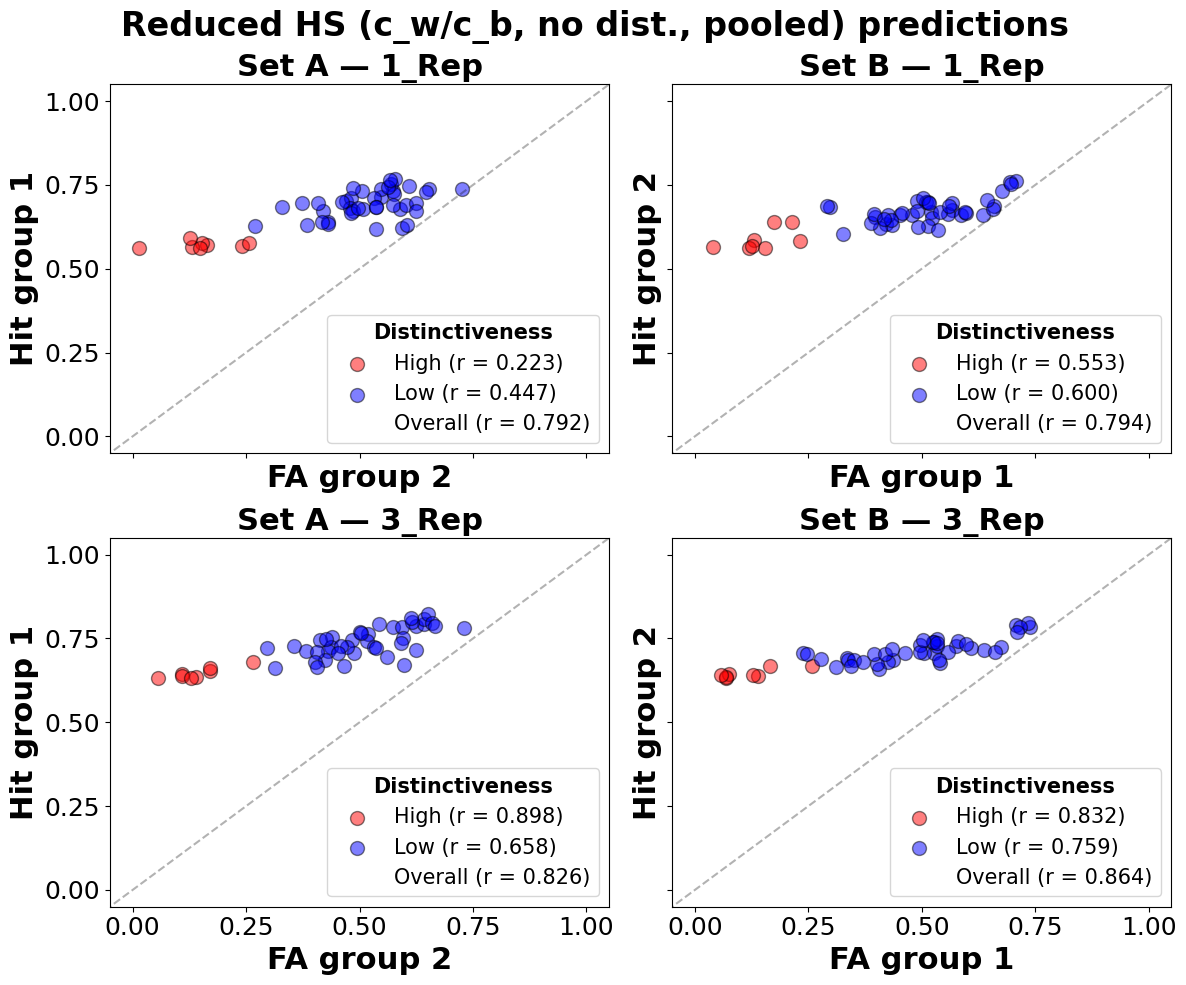

Column: HS_cwb_reduced_pooled_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.22, p = 0.595, n = 8
  Bottom: r = 0.45, p = 0.003, n = 42
  Overall: r = 0.79, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.55, p = 0.156, n = 8
  Bottom: r = 0.60, p = 0.000, n = 42
  Overall: r = 0.79, p = 0.000, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.90, p = 0.002, n = 8
  Bottom: r = 0.66, p = 0.000, n = 42
  Overall: r = 0.83, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.83, p = 0.010, n = 8
  Bottom: r = 0.76, p = 0.000, n = 42
  Overall: r = 0.86, p = 0.000, n = 50


In [161]:
for col, label in new_models:
    plot_hit_fa_cross_correlations(df_by_item, col, label)
    get_H_vs_FA_correlations(df_by_item, col)

### Simulate models

Predictied hits and false alarms are not noisy at all. So, we want to run many simulations where we will generate random data from the binomial distribution with the number of trials equal to the number of subjects and probability of success = model predicted probability.

In [171]:
MODELS = {
    "HS_preds":                    "Full 1c model (separate params per group)",
    "HS_pooled_groups_preds":      "Full 1c model (pooled params per group)",
    "Base_preds":                  "Base 1c model (separate params per group)",
    "HS_cwb_full_group_preds":     "Full 2c model (separate params per group)",
    "HS_cwb_full_pooled_preds":    "Full 2c model (pooled params per group)",
    "HS_cwb_reduced_group_preds":  "Reduced 2c model, no dist. (separate per group)",
    "HS_cwb_reduced_pooled_preds": "Reduced 2c model, no dist. (pooled)",
}
N_ITER = 10_000
SEED = 12345

In [164]:
# Wider format of df_by_item for easier plotting and analysis
df_by_item_wide = df_by_item.pivot(index=["image_id", "condition", "distinct_type",
                                "category_name", "distinct_rating"],
                         columns="resp_type")
df_by_item_wide.columns = [f"{col}_{ans_type.lower()}" for col, ans_type in df_by_item_wide.columns]
df_by_item_wide = df_by_item_wide.reset_index()
df_by_item_wide["set"] = np.where(df_by_item_wide["group_hit"] == "Group1", "A", "B")
df_by_item_wide

,image_id,condition,distinct_type,category_name,distinct_rating,group_fa,group_hit,n_subj_fa,n_subj_hit,n_yes_fa,...,Base_preds_hit,HS_cwb_full_group_preds_fa,HS_cwb_full_group_preds_hit,HS_cwb_full_pooled_preds_fa,HS_cwb_full_pooled_preds_hit,HS_cwb_reduced_group_preds_fa,HS_cwb_reduced_group_preds_hit,HS_cwb_reduced_pooled_preds_fa,HS_cwb_reduced_pooled_preds_hit,set
0,3,1_Rep,Bottom,Andesite,3.17,Group1,Group2,65,61,20,...,0.666133,0.492194,0.656989,0.513095,0.655344,0.500084,0.665236,0.519910,0.669352,B
1,3,3_Rep,Bottom,Andesite,3.17,Group1,Group2,50,56,14,...,0.708823,0.460375,0.687281,0.513210,0.689582,0.460569,0.708968,0.526763,0.706564,B
2,4,1_Rep,Bottom,Andesite,3.18,Group1,Group2,65,61,37,...,0.646577,0.441510,0.632784,0.454386,0.637167,0.399498,0.630885,0.421541,0.633711,B
3,4,3_Rep,Bottom,Andesite,3.18,Group1,Group2,50,56,23,...,0.689873,0.387965,0.682716,0.469691,0.681590,0.329601,0.691124,0.436093,0.686055,B
4,6,1_Rep,Bottom,Andesite,3.17,Group2,Group1,61,65,34,...,0.726337,0.538260,0.688249,0.519423,0.692527,0.552724,0.711232,0.548171,0.714673,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,471,3_Rep,Bottom,Shale,2.73,Group1,Group2,50,56,21,...,0.740887,0.532664,0.710363,0.582634,0.705117,0.556921,0.742379,0.598331,0.733396,B
196,472,1_Rep,Bottom,Shale,2.55,Group2,Group1,61,65,22,...,0.658494,0.503710,0.664335,0.500060,0.659276,0.502820,0.693618,0.497464,0.681863,A
197,472,3_Rep,Bottom,Shale,2.55,Group2,Group1,56,50,14,...,0.704695,0.513583,0.688740,0.472758,0.675254,0.488112,0.721442,0.452795,0.705525,A
198,476,1_Rep,Bottom,Shale,2.48,Group2,Group1,61,65,32,...,0.680382,0.543888,0.666132,0.532800,0.664399,0.548126,0.688931,0.536760,0.683350,A


In [165]:
# Number of subjects and observed proportions for hits and false alarms
hit_n, fa_n = df_by_item_wide["n_subj_hit"].to_numpy(), df_by_item_wide["n_subj_fa"].to_numpy()
hit_obs, fa_obs = df_by_item_wide["prop_yes_hit"].to_numpy(), df_by_item_wide["prop_yes_fa"].to_numpy()

distinctiveness_colors = {"Bottom": "blue", 
                          "Top": "red", 
                          "Overall": "gray"}
cond_set_order = [(c, s) for c in ["1_Rep", "3_Rep"] for s in ["A", "B"]]

In [166]:
# Calculate pearson correlations for all N_ITER samples instantly
def pearson_rows(x, y):
    return pearsonr(x, y, axis=1).statistic

In [167]:
# Function to run simulations:
# We take predictions from a model and generate noisy data from binomial
# Then we calculate the correlation between hits and false alarms for each simulated dataset
def simulate_H_FA_corrs(model_preds, seed=SEED):
    
    rng = np.random.default_rng(seed)
    
    # Model-predicted probabilities
    hit_p = df_by_item_wide[f"{model_preds}_hit"].to_numpy()
    fa_p = df_by_item_wide[f"{model_preds}_fa"].to_numpy()
    
    # Simulate observed proportions for every item × condition
    # Shape: (N_ITER, n_items)
    hit_prop = (
        rng.binomial(n=hit_n, p=hit_p, size=(N_ITER, len(df_by_item_wide)))
        / hit_n
    )
    
    fa_prop = (
        rng.binomial(n=fa_n, p=fa_p, size=(N_ITER, len(df_by_item_wide)))
        / fa_n
    )
    
    results = {}
    
    # Simulate correlations for each condition, set, and distinctiveness group
    for condition in ["1_Rep", "3_Rep"]:
        for set_name in ["A", "B"]:
            
            # Select the relevant items
            panel = (
                (df_by_item_wide["condition"] == condition) &
                (df_by_item_wide["set"] == set_name)
            )
            
            for distinct_type in distinctiveness_colors.keys():
                
                if distinct_type == "Overall":
                    mask = panel.to_numpy()
                else:
                    mask = (
                        panel &
                        (df_by_item_wide["distinct_type"] == distinct_type)
                    ).to_numpy()
                
                
                # Observed correlation 
                # (already calculated it before - do it again to save everything together)
                observed_r = pearsonr(
                    fa_obs[mask],
                    hit_obs[mask]
                ).statistic
                
                # Simulated correlations
                simulated_r = pearson_rows(
                    fa_prop[:, mask],
                    hit_prop[:, mask]
                )
                
                # Where does the observed correlation fall
                percentile = np.mean(simulated_r < observed_r)
                
                results[(condition, set_name, distinct_type)] = {
                    "model": model_preds,
                    "condition": condition,
                    "set": set_name,
                    "distinct_type": distinct_type,
                    "n_items": mask.sum(),
                    "observed_r": observed_r,
                    "simulated_r": simulated_r,
                    "simulated_mean": simulated_r.mean(),
                    "simulated_sd": simulated_r.std(),
                    "percentile": percentile,
                    "p_value": 2 * min(percentile, 1 - percentile)
                    }
    
    return results

In [168]:
# Function to plot the results of the simulations
def plot_H_FA_simulations(simulation_results_dict, model_label):
    n_rows = len(cond_set_order)
    n_cols = len(distinctiveness_colors)
    fs = 22  # font size
    fs_axes = 18
    fs_subplot_title = 14
    ax_offset = 0.25

    # squeeze=False - to guarantee that axes is always 2D, even if n_rows or n_cols is 1
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), 
        squeeze=False
    )
    fig.suptitle(model_label, fontsize=fs, y=1.0, fontweight="bold")


    for i, (c, s) in enumerate(cond_set_order):
        for j, (d, col) in enumerate(distinctiveness_colors.items()):
            ax = axes[i, j]
            ax.set_xlim(-1, 1)
            r = simulation_results_dict.get((c, s, d))
            ax.hist(r["simulated_r"], bins=50, color=col, alpha=0.5)
            ax.axvline(r["observed_r"], color="black", lw=2, ls="--")

            # Subplot title: observed r and percentile
            ax.set_title(
                f"observed r={r['observed_r']:.2f}  percentile={r['percentile']:.2f}",
                fontsize=fs_subplot_title,
            )

            # Column titles (only above the top row)
            if i == 0:
                ax.annotate(
                    f"{d}",
                    xy=(0.5, 1+ax_offset),
                    xycoords="axes fraction",
                    ha="center",
                    va="center",
                    fontsize=fs_axes,
                    fontweight="bold",
                )

            # Row labels (only to the left of the first column)
            if j == 0:
                ax.annotate(
                    f"{c[0]} Rep\n Set {s}",
                    xy=(0-ax_offset, 0.5),
                    xycoords="axes fraction",
                    ha="center",
                    va="center",
                    rotation=90,
                    fontsize=fs_axes,
                    fontweight="bold",
                )

    plt.tight_layout()
    plt.show()


===== Full 1c model (separate params per group) =====
   model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_preds     1_Rep   A        Bottom       42    0.620141        0.340927      0.124822      0.9931   0.0138
HS_preds     1_Rep   A           Top        8    0.153805        0.139799      0.368052      0.4901   0.9802
HS_preds     1_Rep   A       Overall       50    0.345857        0.003894      0.116740      0.9984   0.0032
HS_preds     1_Rep   B        Bottom       42    0.461238        0.349919      0.128053      0.8010   0.3980
HS_preds     1_Rep   B           Top        8   -0.211159        0.053275      0.373058      0.2537   0.5074
HS_preds     1_Rep   B       Overall       50    0.337928        0.261277      0.121453      0.7274   0.5452
HS_preds     3_Rep   A        Bottom       42    0.542998        0.189624      0.139953      0.9960   0.0080
HS_preds     3_Rep   A           Top        8   -0.621089        0.072488

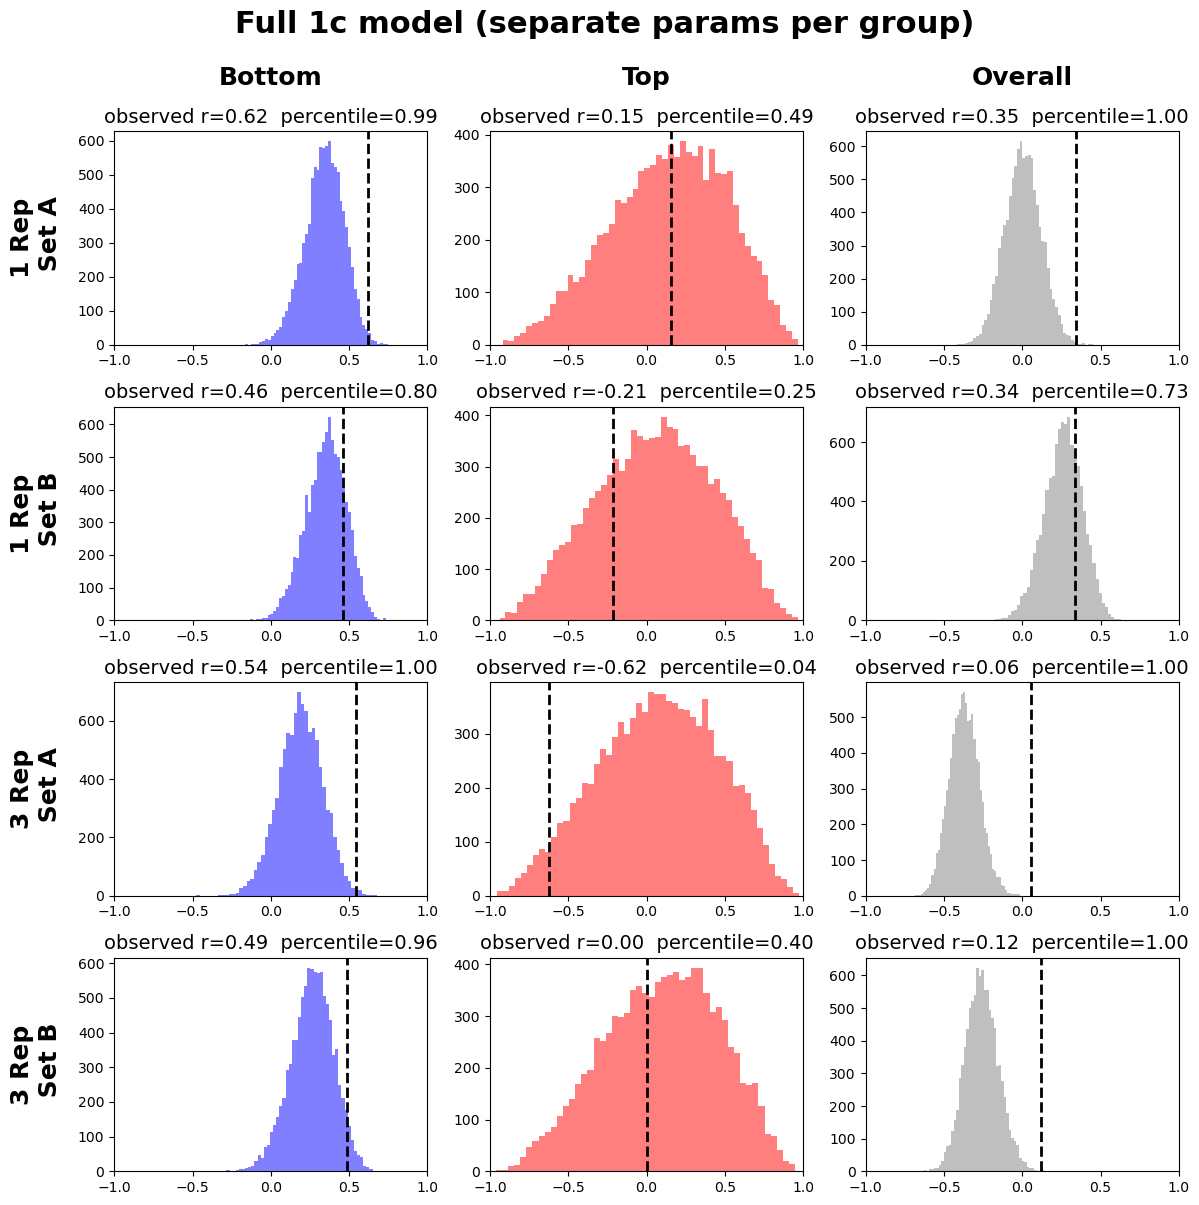


===== Full 1c model (pooled params per group) =====
                 model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_pooled_groups_preds     1_Rep   A        Bottom       42    0.620141        0.335345      0.122214      0.9949   0.0102
HS_pooled_groups_preds     1_Rep   A           Top        8    0.153805        0.105604      0.372966      0.5332   0.9336
HS_pooled_groups_preds     1_Rep   A       Overall       50    0.345857        0.153070      0.116408      0.9541   0.0918
HS_pooled_groups_preds     1_Rep   B        Bottom       42    0.461238        0.338899      0.129587      0.8218   0.3564
HS_pooled_groups_preds     1_Rep   B           Top        8   -0.211159        0.070619      0.377546      0.2478   0.4956
HS_pooled_groups_preds     1_Rep   B       Overall       50    0.337928        0.038578      0.126886      0.9910   0.0180
HS_pooled_groups_preds     3_Rep   A        Bottom       42    0.542998        0.22870

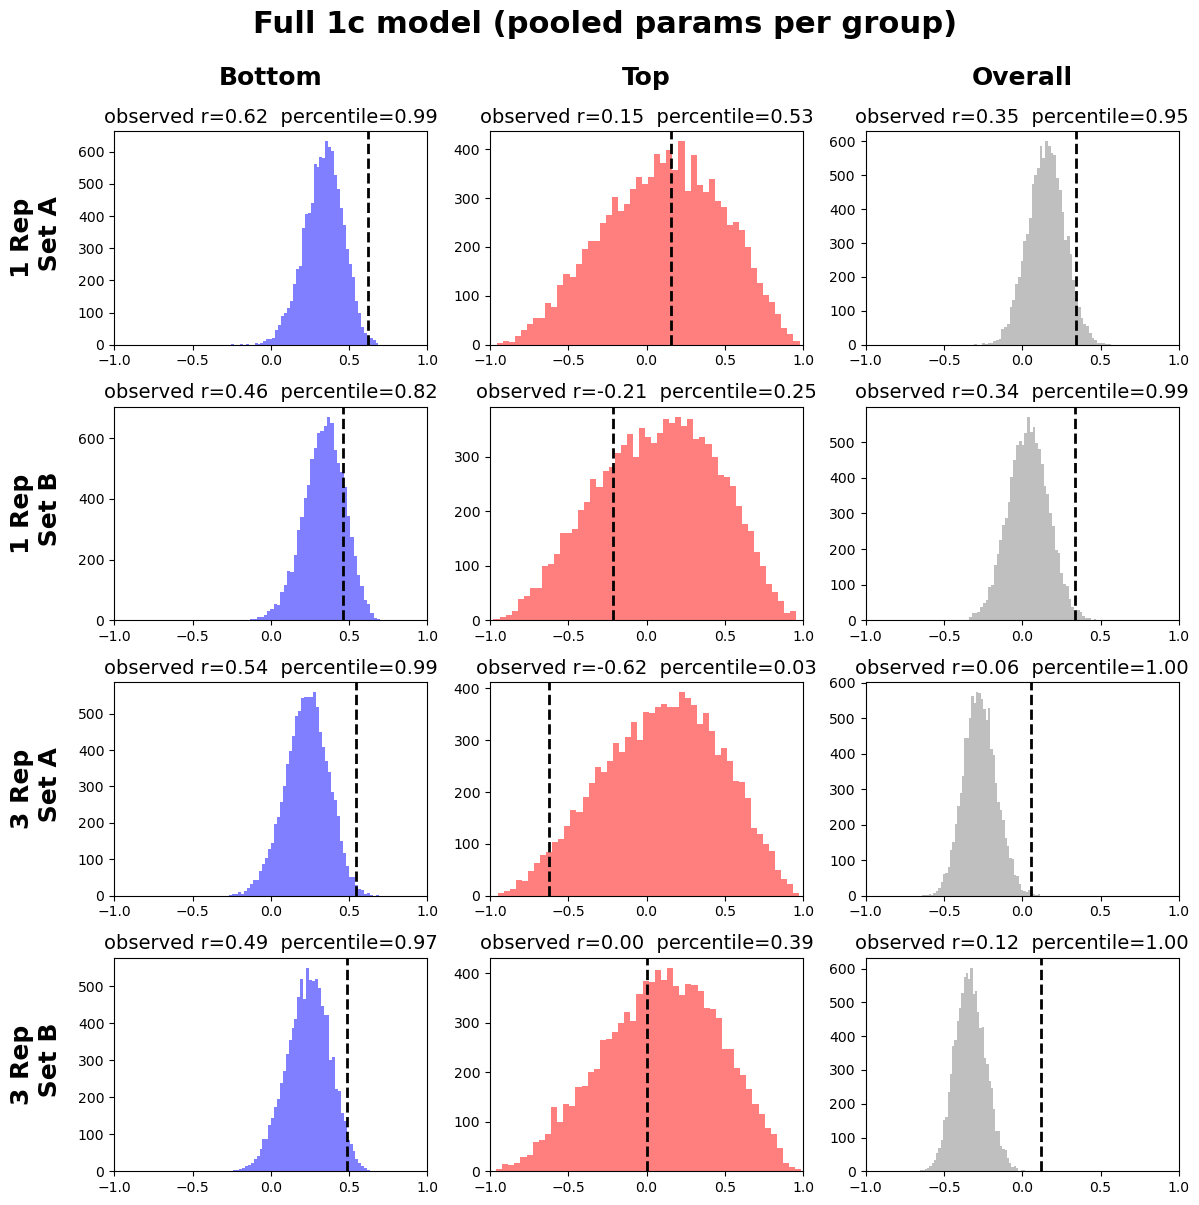


===== Base 1c model (separate params per group) =====
     model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
Base_preds     1_Rep   A        Bottom       42    0.620141        0.384316      0.114883      0.9857   0.0286
Base_preds     1_Rep   A           Top        8    0.153805        0.258017      0.345217      0.3536   0.7072
Base_preds     1_Rep   A       Overall       50    0.345857        0.600997      0.076175      0.0011   0.0022
Base_preds     1_Rep   B        Bottom       42    0.461238        0.395974      0.118163      0.6964   0.6072
Base_preds     1_Rep   B           Top        8   -0.211159        0.169494      0.365538      0.1669   0.3338
Base_preds     1_Rep   B       Overall       50    0.337928        0.547794      0.088164      0.0153   0.0306
Base_preds     3_Rep   A        Bottom       42    0.542998        0.311089      0.129454      0.9712   0.0576
Base_preds     3_Rep   A           Top        8   -0.6210

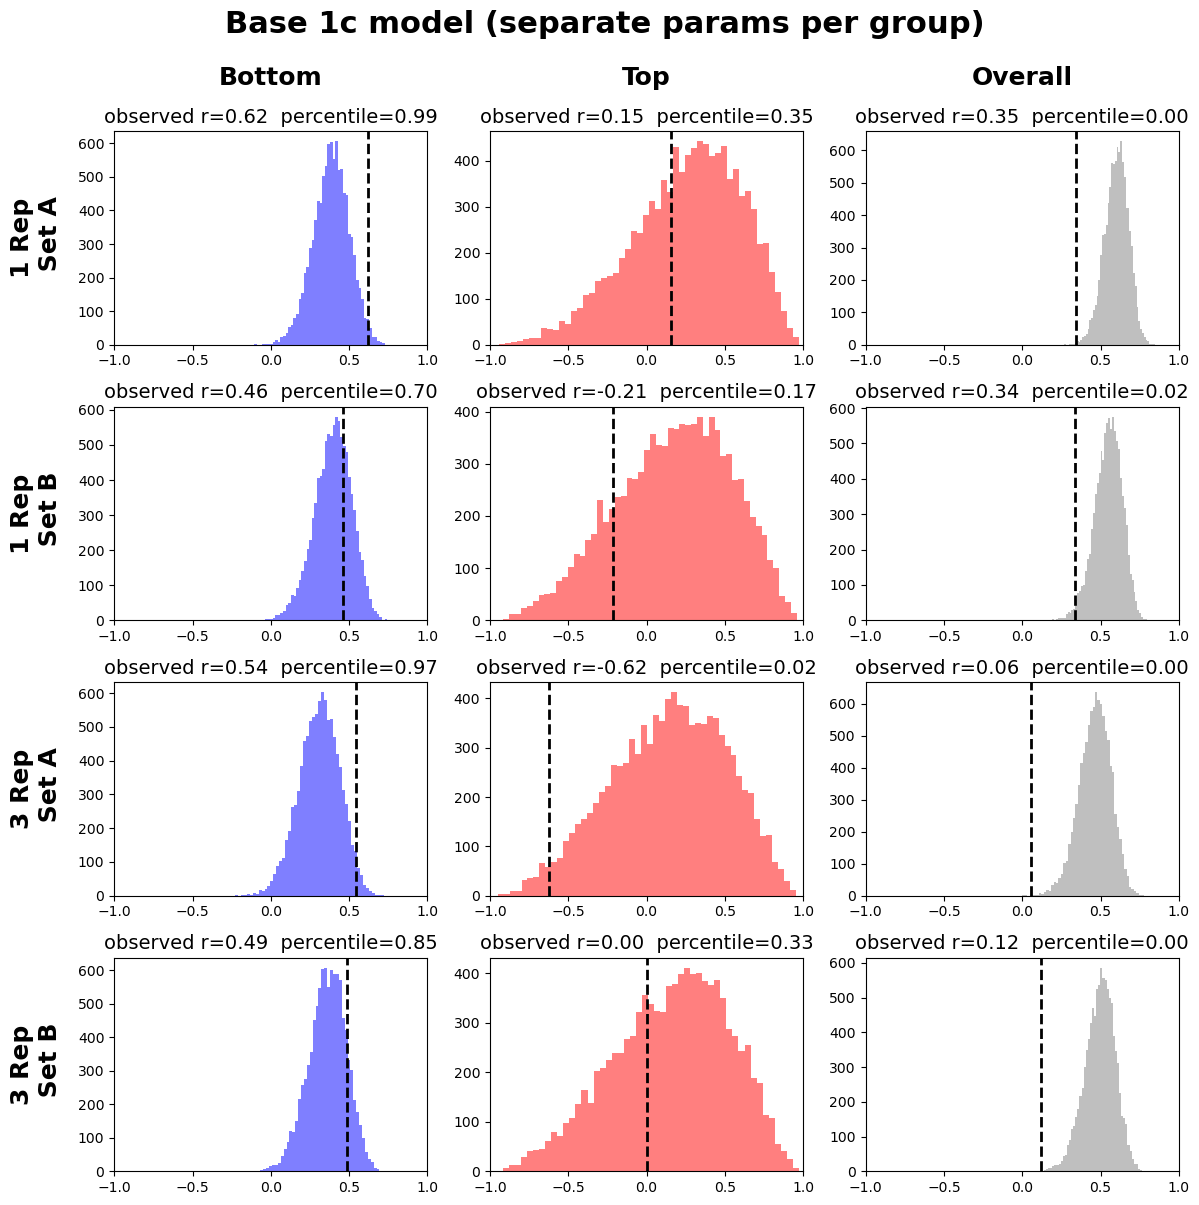


===== Full 2c model (separate params per group) =====
                  model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_cwb_full_group_preds     1_Rep   A        Bottom       42    0.620141        0.153108      0.145097      0.9998   0.0004
HS_cwb_full_group_preds     1_Rep   A           Top        8    0.153805        0.094191      0.372639      0.5478   0.9044
HS_cwb_full_group_preds     1_Rep   A       Overall       50    0.345857       -0.068285      0.129316      0.9991   0.0018
HS_cwb_full_group_preds     1_Rep   B        Bottom       42    0.461238        0.225060      0.139195      0.9600   0.0800
HS_cwb_full_group_preds     1_Rep   B           Top        8   -0.211159        0.061544      0.362237      0.2374   0.4748
HS_cwb_full_group_preds     1_Rep   B       Overall       50    0.337928        0.164778      0.128535      0.9143   0.1714
HS_cwb_full_group_preds     3_Rep   A        Bottom       42    0.542998     

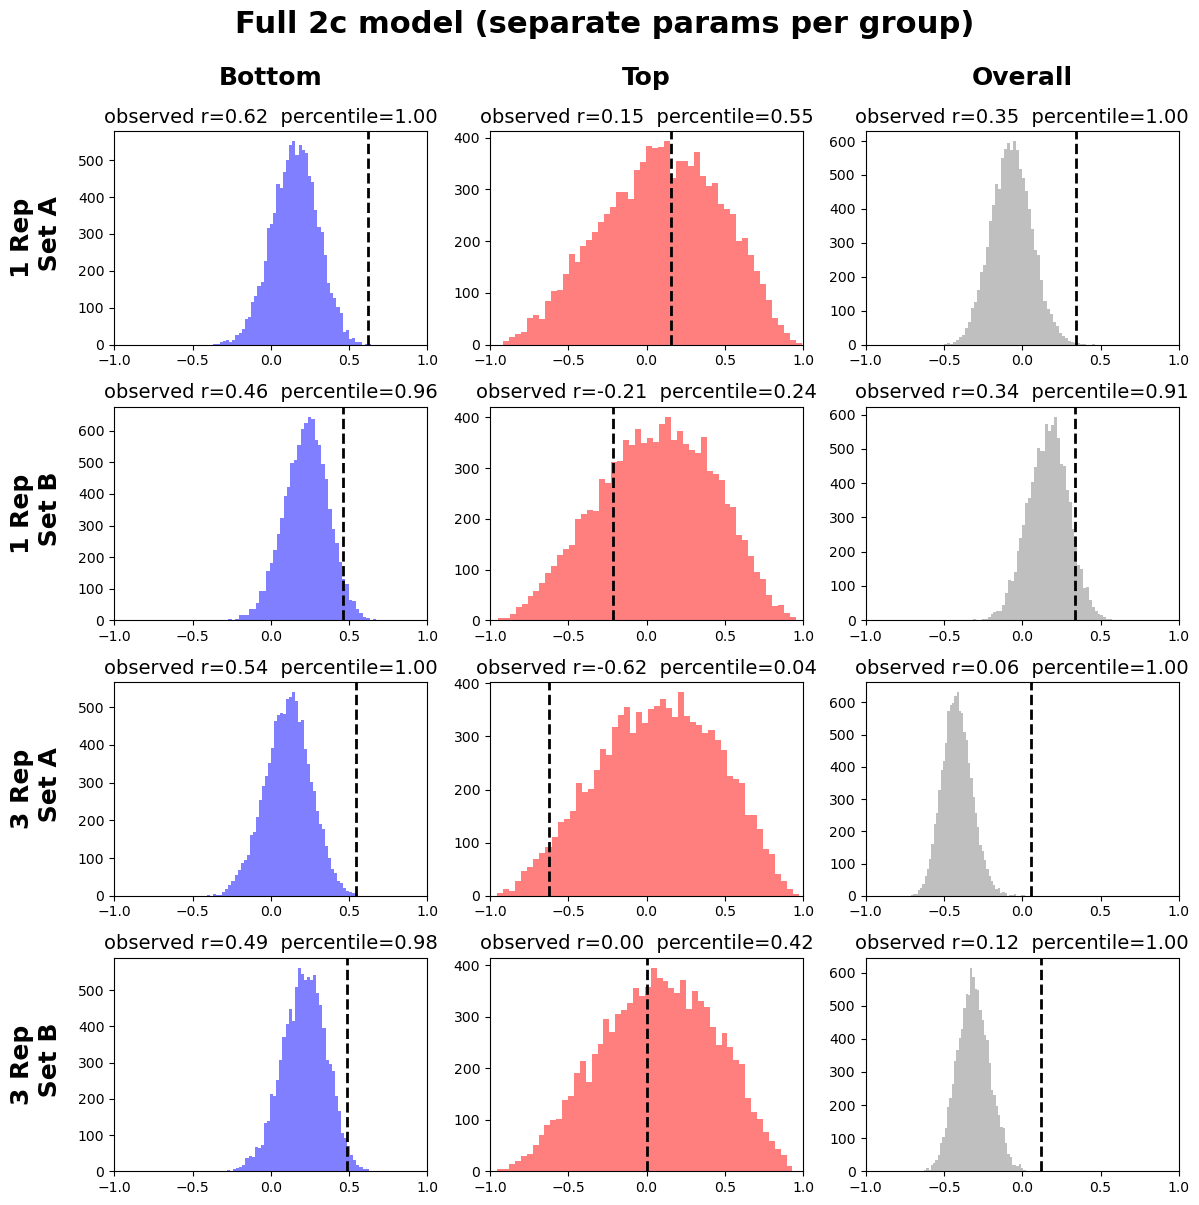


===== Full 2c model (pooled params per group) =====
                   model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_cwb_full_pooled_preds     1_Rep   A        Bottom       42    0.620141        0.182073      0.142366      0.9999   0.0002
HS_cwb_full_pooled_preds     1_Rep   A           Top        8    0.153805        0.075165      0.373111      0.5606   0.8788
HS_cwb_full_pooled_preds     1_Rep   A       Overall       50    0.345857        0.090089      0.128072      0.9796   0.0408
HS_cwb_full_pooled_preds     1_Rep   B        Bottom       42    0.461238        0.203244      0.141733      0.9720   0.0560
HS_cwb_full_pooled_preds     1_Rep   B           Top        8   -0.211159        0.084356      0.365643      0.2241   0.4482
HS_cwb_full_pooled_preds     1_Rep   B       Overall       50    0.337928       -0.013735      0.131680      0.9971   0.0058
HS_cwb_full_pooled_preds     3_Rep   A        Bottom       42    0.54299

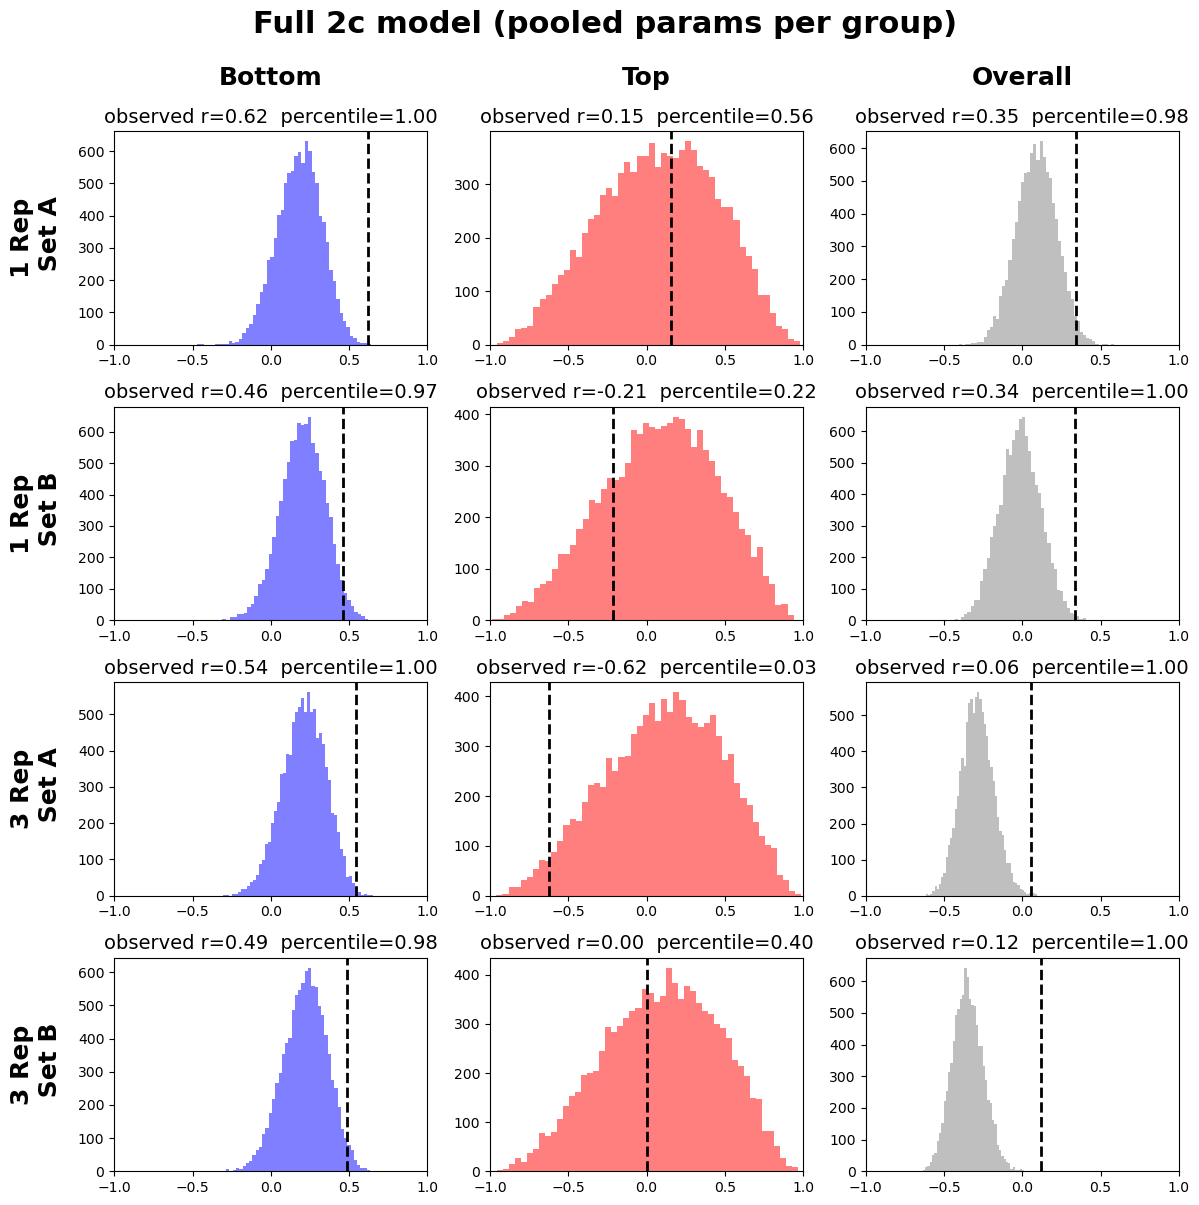


===== Reduced 2c model, no dist. (separate per group) =====
                     model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_cwb_reduced_group_preds     1_Rep   A        Bottom       42    0.620141        0.191917      0.137912      0.9998   0.0004
HS_cwb_reduced_group_preds     1_Rep   A           Top        8    0.153805        0.027655      0.376692      0.6146   0.7708
HS_cwb_reduced_group_preds     1_Rep   A       Overall       50    0.345857        0.498746      0.093515      0.0558   0.1116
HS_cwb_reduced_group_preds     1_Rep   B        Bottom       42    0.461238        0.269916      0.129332      0.9349   0.1302
HS_cwb_reduced_group_preds     1_Rep   B           Top        8   -0.211159        0.126534      0.351169      0.1789   0.3578
HS_cwb_reduced_group_preds     1_Rep   B       Overall       50    0.337928        0.477702      0.095875      0.0783   0.1566
HS_cwb_reduced_group_preds     3_Rep   A        Bo

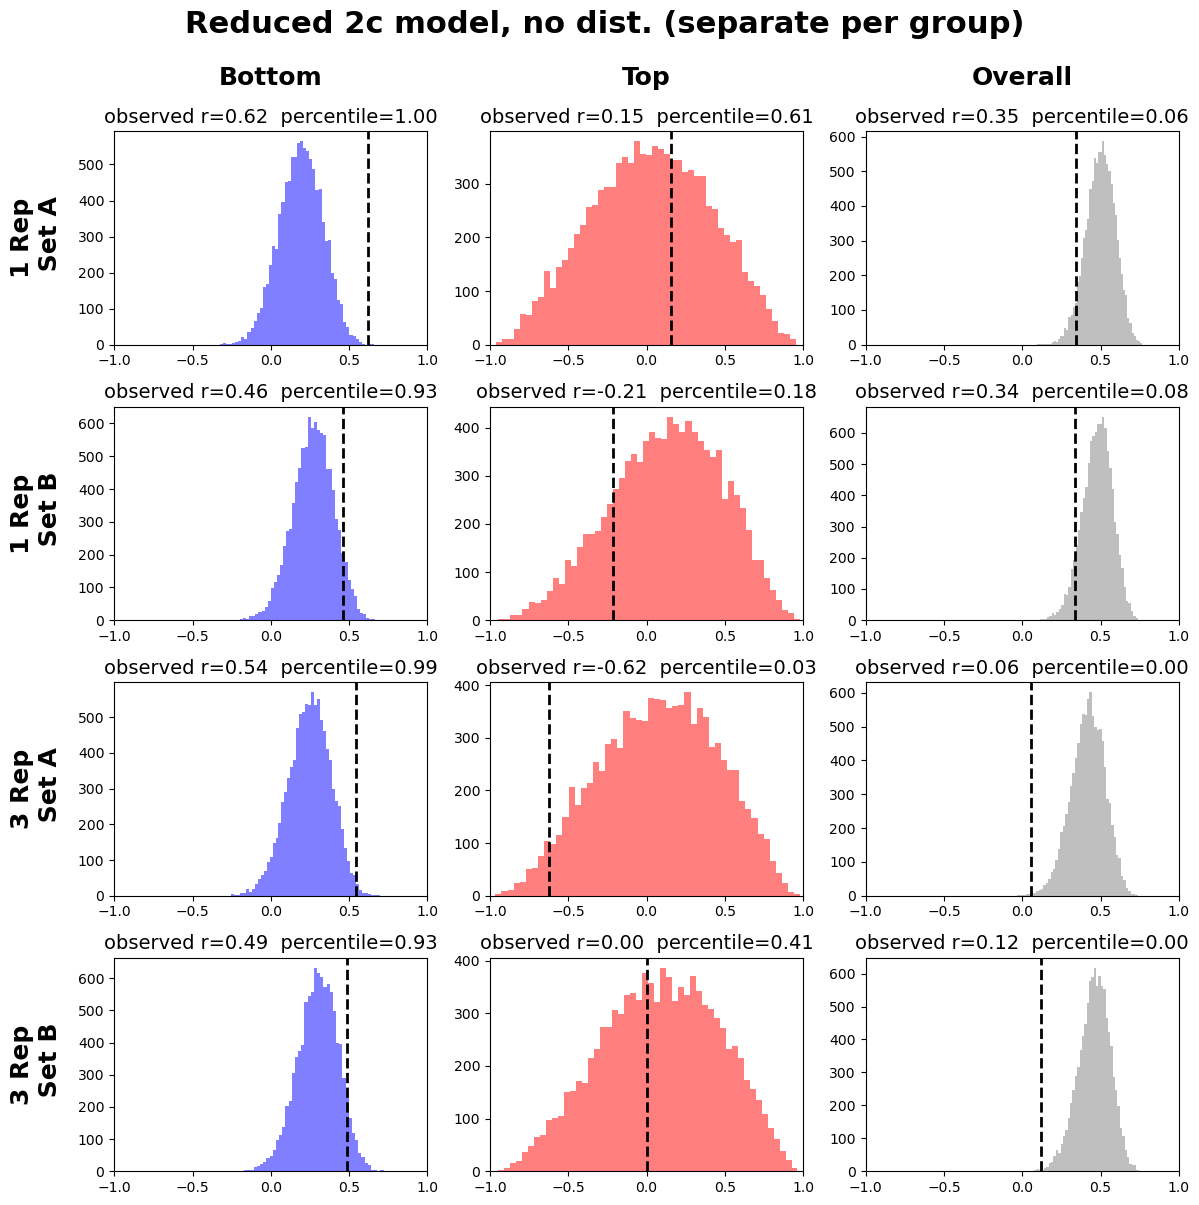


===== Reduced 2c model, no dist. (pooled) =====
                      model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_cwb_reduced_pooled_preds     1_Rep   A        Bottom       42    0.620141        0.216809      0.131685      0.9997   0.0006
HS_cwb_reduced_pooled_preds     1_Rep   A           Top        8    0.153805        0.033743      0.377784      0.6066   0.7868
HS_cwb_reduced_pooled_preds     1_Rep   A       Overall       50    0.345857        0.531333      0.085845      0.0212   0.0424
HS_cwb_reduced_pooled_preds     1_Rep   B        Bottom       42    0.461238        0.269879      0.130328      0.9350   0.1300
HS_cwb_reduced_pooled_preds     1_Rep   B           Top        8   -0.211159        0.205054      0.343582      0.1304   0.2608
HS_cwb_reduced_pooled_preds     1_Rep   B       Overall       50    0.337928        0.463040      0.098475      0.1056   0.2112
HS_cwb_reduced_pooled_preds     3_Rep   A        Bottom

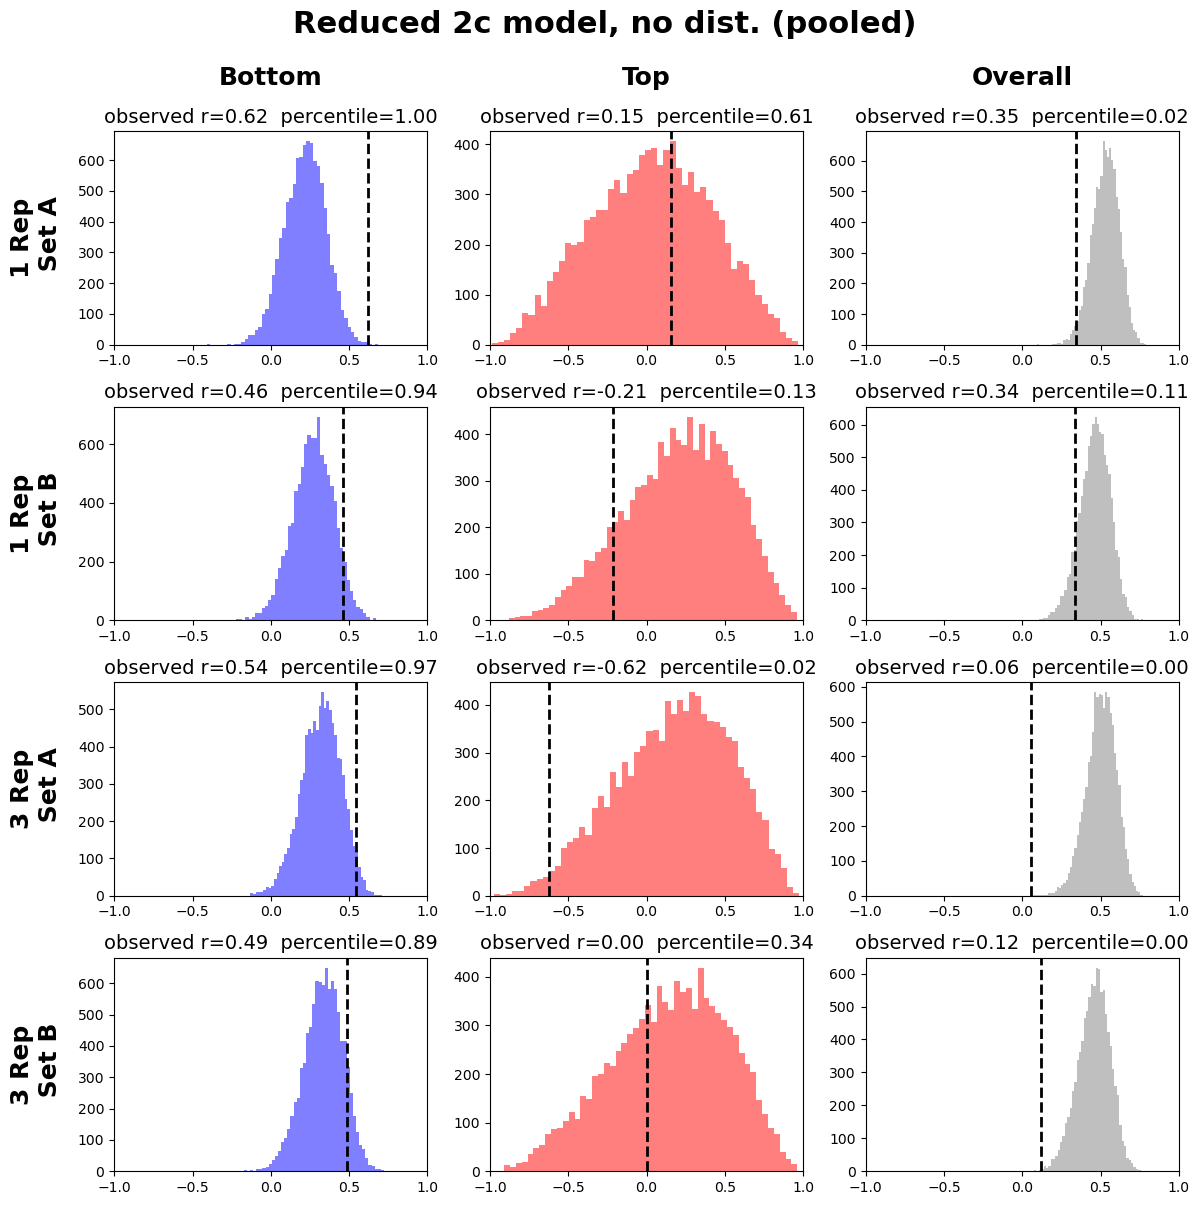

In [172]:
# Run simulations
simulation_H_FA_results = {}

for mod, model_label in MODELS.items():
    
    res = simulate_H_FA_corrs(mod)
    simulation_H_FA_results[mod] = res
    
    # Convert results to DataFrame for printing
    res_df = pd.DataFrame(res.values())
    
    print(f"\n===== {model_label} =====")
    print(res_df.drop(columns="simulated_r").to_string(index=False))
    
    plot_H_FA_simulations(res, model_label)

## Aggregated

In [95]:
# Aggregated plot of model predictions and observed data, by condition, response type, and distinctiveness
def plot_model_summary(df_by_item, by_set=False, fs=20, fs_axes=16, fs_leg=13):
    conditions = ["1_Rep", "3_Rep"]
    distinct_levels = ["Bottom", "Top"]
    resp_levels = ["Hit", "FA"]

    color_map = {"Bottom": "blue", "Top": "red"}
    distinct_label_map = {"Bottom": "Low", "Top": "High"}
    condition_label_map = {"1_Rep": "1 Rep", "3_Rep": "3 Reps"}

    x_pos = np.arange(len(conditions))
    bar_width = 0.35
    offsets = {"Bottom": -bar_width / 2, "Top": bar_width / 2}
    model_offset = {"hs": -0.09, "pooled": 0.0, "base": 0.09}
    marker_map = {"hs": ("s", "Full model"), "pooled": ("^", "Pooled model"), "base": ("o", "Base model")}

    panel_w, panel_h = 7, 5  # size of a single subplot, used for both layouts

    # -------- summary stats --------
    group_cols = ["condition", "resp_type", "distinct_type"] + (["group"] if by_set else [])
    summary = (
        df_by_item
        .groupby(group_cols, observed=False)
        .agg(
            mean_prop=("prop_yes", "mean"),
            mean_hs=("HS_preds", "mean"),
            mean_pooled=("HS_pooled_groups_preds", "mean"),
            mean_base=("Base_preds", "mean"),
            n=("prop_yes", "size"),
            sd=("prop_yes", "std")
        )
        .reset_index()
    )
    summary["se"] = summary["sd"] / np.sqrt(summary["n"])
    summary["ci95"] = summary["se"] * stats.t.ppf(0.975, summary["n"] - 1)

    # -------- panel layout --------
    if by_set:
        sets = {"Set A": {"Hit": "Group1", "FA": "Group2"},
                "Set B": {"Hit": "Group2", "FA": "Group1"}}
        nrows, ncols = 2, 2
        fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows), sharey=True)
        panels = [(r, c, set_name, resp, group_map[resp])
                  for r, (set_name, group_map) in enumerate(sets.items())
                  for c, resp in enumerate(resp_levels)]
    else:
        nrows, ncols = 1, 2
        fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows), sharey=True)
        axes = axes.reshape(1, -1)
        panels = [(0, c, None, resp, None) for c, resp in enumerate(resp_levels)]

    # -------- draw each panel --------
    for row_idx, col_idx, set_name, resp, group in panels:
        ax = axes[row_idx, col_idx]

        for distinct in distinct_levels:
            color = color_map[distinct]
            bar_offset = offsets[distinct]

            filt = (
                (summary["resp_type"] == resp) &
                (summary["distinct_type"] == distinct) &
                (True if not by_set else summary["group"] == group)
            )
            sub = summary[filt].set_index("condition")

            means = [sub.loc[c, "mean_prop"] for c in conditions]
            cis = [sub.loc[c, "ci95"] for c in conditions]
            model_means = {m: [sub.loc[c, f"mean_{m}"] for c in conditions] for m in marker_map}

            ax.bar(x_pos + bar_offset, means, width=bar_width, color=color, alpha=0.5,
                   label=f"{distinct_label_map[distinct]} - Observed")
            ax.errorbar(x_pos + bar_offset, means, yerr=cis, fmt="none",
                        ecolor=color, elinewidth=2, capsize=6, capthick=2)

            for m, (marker, label) in marker_map.items():
                ax.scatter(x_pos + bar_offset + model_offset[m], model_means[m],
                           marker=marker, s=150, color=color,
                           edgecolors="k", linewidths=0.8, zorder=5,
                           label=f"{distinct_label_map[distinct]} - {label}")

        title = f"{set_name} — {resp}" if by_set else resp
        ax.set_title(title, fontsize=fs, fontweight="bold")
        ax.set_xticks(x_pos)
        ax.set_xticklabels([condition_label_map[c] for c in conditions], fontsize=fs_axes)
        ax.set_xlim(-0.6, len(conditions) - 0.4)
        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks(np.arange(0, 1.1, 0.25))
        ax.tick_params(axis="both", labelsize=fs_axes)
        ax.text(0.05, 0.95, "Error bars = observed 95% CI", transform=ax.transAxes,
                fontsize=12, color="gray")

    # -------- shared legend --------
    legend_elements = [
        Patch(facecolor="blue", alpha=0.5, label="Low - Observed"),
        Patch(facecolor="red", alpha=0.5, label="High - Observed"),
        Line2D([0], [0], marker="None", color="w", markersize=10, label=""),  # spacer
        Line2D([0], [0], marker="s", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Full model"),
        Line2D([0], [0], marker="^", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Pooled model"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Base model"),
    ]
    leg = fig.legend(handles=legend_elements, loc="center right",
                      bbox_to_anchor=(1.17, 0.5),
                      fontsize=fs_leg, frameon=True,
                      title="Distinctiveness",
                      title_fontsize=fs_leg)
    leg.get_title().set_fontweight('bold')

    fig.text(-0.02, 0.5, 'Proportion "Old"', va="center",
              rotation="vertical", fontsize=fs, fontweight="bold")
    fig.text(0.5, -0.02, "Condition", ha="center",
              fontsize=fs, fontweight="bold")

    plt.tight_layout()
    plt.show()

### For H & FA

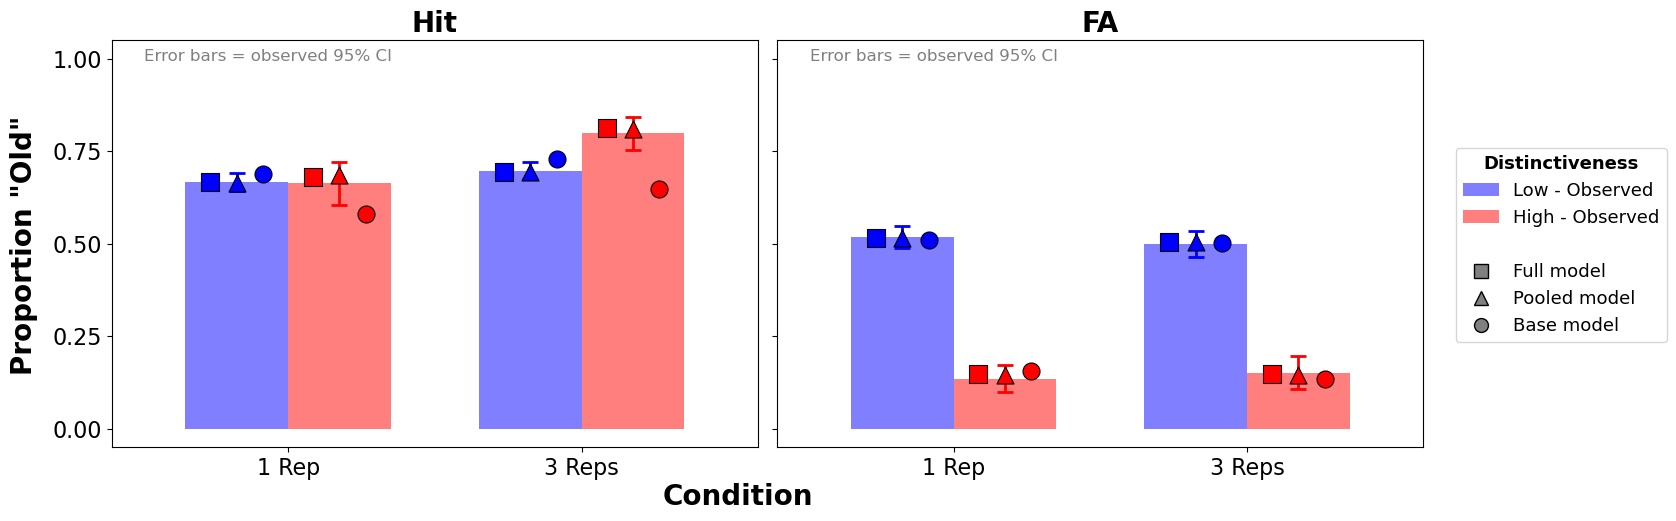

In [96]:
plot_model_summary(df_by_item, by_set=False) 

### For H & FA * Set A & B

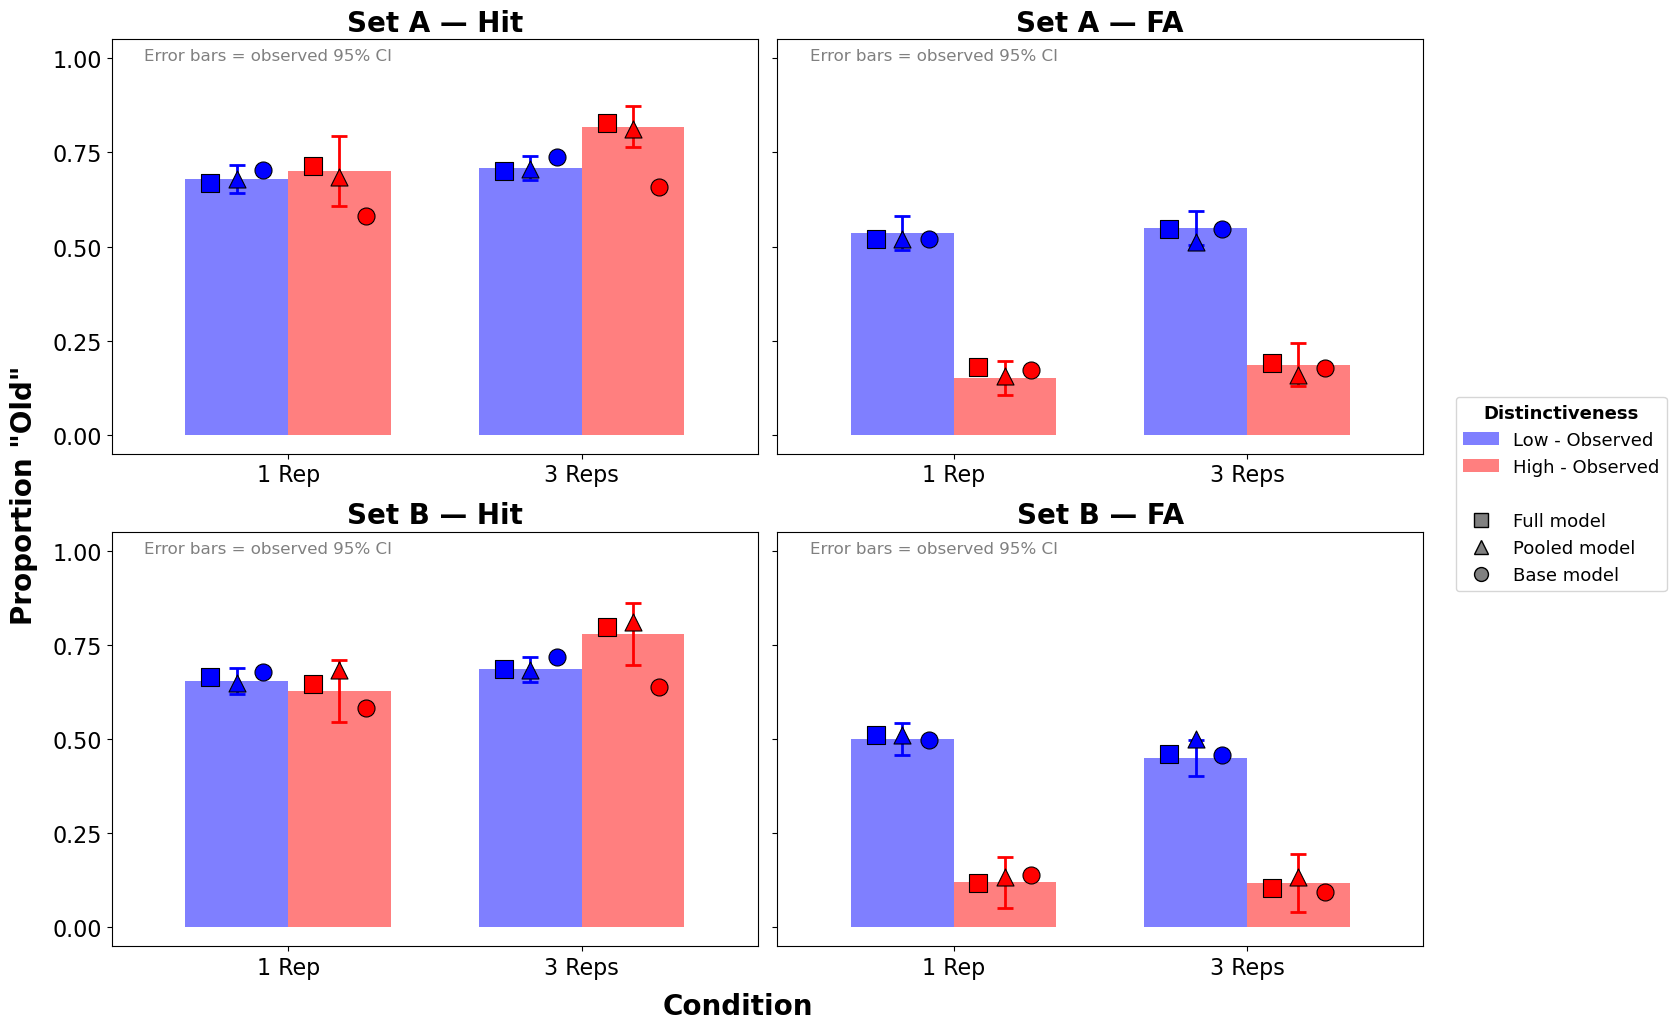

In [97]:
plot_model_summary(df_by_item, by_set=True)

# Model Comparison

In [ ]:
# old version of AIC/BIC calculations
# w/o the new c_w/c_b model
results_aic_bic = []

for condition in ['1_Rep', '3_Rep']:
    n_pooled = len(filtered_data_test.loc[filtered_data_test["condition"] == condition])

    # Pooled: k=4, fit jointly
    nll_pooled = optimization_result['HS_pooled_groups_model'][condition].fun
    k_pooled = 4

    # HS full: two independent group fits, params NOT shared → k = 4+4 = 8
    nll_full = sum(
        optimization_result['HS_model'][(g, condition)].fun for g in ['Group1', 'Group2']
    )
    k_full = 8

    # Base: two independent group fits → k = 2+2 = 4
    nll_base = sum(
        optimization_result['Base_model'][(g, condition)].fun for g in ['Group1', 'Group2']
    )
    k_base = 4

    def aic(k, nll): return 2 * k + 2 * nll
    def bic(k, n, nll): return k * np.log(n) + 2 * nll

    results_aic_bic.append({
        'Condition': condition,
        'NLL_HS': round(nll_full, 3), 'NLL_Pooled': round(nll_pooled, 3), 'NLL_Base': round(nll_base, 3),
        'AIC_HS': round(aic(k_full, nll_full), 3), 'AIC_Pooled': round(aic(k_pooled, nll_pooled), 3), 'AIC_Base': round(aic(k_base, nll_base), 3),
        'BIC_HS': round(bic(k_full, n_pooled, nll_full), 3), 'BIC_Pooled': round(bic(k_pooled, n_pooled, nll_pooled), 3), 'BIC_Base': round(bic(k_base, n_pooled, nll_base), 3),
    })

df_aic_bic = pd.DataFrame(results_aic_bic)
print(df_aic_bic.to_string(index=False))

Condition   NLL_HS  NLL_Pooled  NLL_Base    AIC_HS  AIC_Pooled  AIC_Base    BIC_HS  BIC_Pooled  BIC_Base
    1_Rep 8044.671    8053.674  8097.019 16105.342   16115.349 16202.038 16164.874   16145.115 16231.804
    3_Rep 6544.274    6562.666  6630.356 13104.548   13133.332 13268.712 13162.697   13162.407 13297.787


In [ ]:
# AIC & BIC
def aic(k, nll):    return 2 * k + 2 * nll
def bic(k, n, nll): return k * np.log(n) + 2 * nll

# (result_key, is_pooled, k, display_name)
model_specs = [
    ('Base_model',              False, 4,  'Base (1c, no dist) [group]'),
    ('HS_model',                False, 8,  'HS (1c, dist) [group]'),
    ('HS_pooled_groups_model',  True,  4,  'HS (1c, dist) [pooled]'),
    ('HS_cwb_reduced_pooled',   True,  3,  'Reduced (2c, no dist) [pooled]'),
    ('HS_cwb_reduced_group',    False, 6,  'Reduced (2c, no dist) [group]'),
    ('HS_cwb_full_pooled',      True,  5,  'Full (2c, dist) [pooled]'),
    ('HS_cwb_full_group',       False, 10, 'Full (2c, dist) [group]'),
]

def get_nll(result_key, is_pooled, condition):
    res = optimization_result[result_key]
    if is_pooled:
        return res[condition].fun
    # group-specific: sum the two independent group fits
    return sum(res[(g, condition)].fun for g in ['Group1', 'Group2'])

rows = []
for condition in ['1_Rep', '3_Rep']:
    n = len(filtered_data_test.loc[filtered_data_test['condition'] == condition])  # both groups
    for result_key, is_pooled, k, name in model_specs:
        nll = get_nll(result_key, is_pooled, condition)
        rows.append({
            'Condition': condition,
            'Model': name,
            'k': k,
            'n': n,
            'NLL': round(nll, 3),
            'AIC': round(aic(k, nll), 3),
            'BIC': round(bic(k, n, nll), 3),
        })

df_aic_bic = pd.DataFrame(rows)

# Deltas relative to best (lowest) within each condition
df_aic_bic['dAIC'] = df_aic_bic.groupby('Condition')['AIC'].transform(lambda s: (s - s.min()).round(3))
df_aic_bic['dBIC'] = df_aic_bic.groupby('Condition')['BIC'].transform(lambda s: (s - s.min()).round(3))

# Sort each condition block by AIC
df_aic_bic = df_aic_bic.sort_values(['Condition', 'AIC']).reset_index(drop=True)

for condition in ['1_Rep', '3_Rep']:
    print(f"{'='*15} {condition} {'='*15}")
    print(df_aic_bic[df_aic_bic['Condition'] == condition]
          .drop(columns='Condition')
          .to_string(index=False))
    print()

=============== 1_Rep ===============
                         Model  k     n      NLL       AIC       BIC    dAIC    dBIC
       Full (2c, dist) [group] 10 12600 8007.952 16035.905 16110.319   0.000  27.651
      Full (2c, dist) [pooled]  5 12600 8017.730 16045.461 16082.668   9.556   0.000
         HS (1c, dist) [group]  8 12600 8044.671 16105.342 16164.874  69.437  82.206
        HS (1c, dist) [pooled]  4 12600 8053.674 16115.349 16145.115  79.444  62.447
 Reduced (2c, no dist) [group]  6 12600 8053.209 16118.419 16163.067  82.514  80.399
Reduced (2c, no dist) [pooled]  3 12600 8059.567 16125.133 16147.458  89.228  64.790
    Base (1c, no dist) [group]  4 12600 8097.019 16202.038 16231.804 166.133 149.136

=============== 3_Rep ===============
                         Model  k     n      NLL       AIC       BIC    dAIC    dBIC
       Full (2c, dist) [group] 10 10600 6538.100 13096.199 13168.885   0.000   6.478
         HS (1c, dist) [group]  8 10600 6544.274 13104.548 13162.697   8.

In [170]:
# ============ Combined across BOTH conditions ============
# Each condition was fit with its own parameter set, so a model covering both
# conditions has k_total = 2 * k_per_condition and NLL_total = sum over conditions.
conditions = ['1_Rep', '3_Rep']
n_total = len(filtered_data_test)   # both groups, both conditions

rows_combined = []
for result_key, is_pooled, k, name in model_specs:
    nll_total = sum(get_nll(result_key, is_pooled, c) for c in conditions)
    k_total = k * len(conditions)   # separate params per condition
    rows_combined.append({
        'Model': name,
        'k': k_total,
        'n': n_total,
        'NLL': round(nll_total, 3),
        'AIC': round(aic(k_total, nll_total), 3),
        'BIC': round(bic(k_total, n_total, nll_total), 3),
    })

df_aic_bic_combined = pd.DataFrame(rows_combined)
df_aic_bic_combined['dAIC'] = (df_aic_bic_combined['AIC'] - df_aic_bic_combined['AIC'].min()).round(3)
df_aic_bic_combined['dBIC'] = (df_aic_bic_combined['BIC'] - df_aic_bic_combined['BIC'].min()).round(3)
df_aic_bic_combined = df_aic_bic_combined.sort_values('AIC').reset_index(drop=True)

print(f"{'='*15} BOTH CONDITIONS COMBINED {'='*15}")
print(df_aic_bic_combined.to_string(index=False))
print()

=============== BOTH CONDITIONS COMBINED ===============
                         Model  k     n       NLL       AIC       BIC    dAIC    dBIC
       Full (2c, dist) [group] 20 23200 14546.052 29132.104 29293.142   0.000  33.645
      Full (2c, dist) [pooled] 10 23200 14579.489 29178.978 29259.497  46.874   0.000
         HS (1c, dist) [group] 16 23200 14588.945 29209.890 29338.720  77.786  79.223
        HS (1c, dist) [pooled]  8 23200 14616.340 29248.681 29313.096 116.577  53.599
 Reduced (2c, no dist) [group] 12 23200 14676.435 29376.871 29473.494 244.767 213.997
Reduced (2c, no dist) [pooled]  6 23200 14707.903 29427.806 29476.118 295.702 216.621
    Base (1c, no dist) [group]  8 23200 14727.375 29470.751 29535.166 338.647 275.669



# Save data

In [99]:
# Save only the variables you actually need
variables_to_save = {
    # all IDs
    #'credited_IDs': credited_IDs,
    # Split-half lists
    'split_half_hits_within_dict' : sh_corrs_hits,
    'split_half_fa_within_dict' : sh_corrs_fa,
    'split_half_hits_across_dict' : sh_corrs_hits_across,
    'split_half_fa_across_dict' : sh_corrs_fa_across,

    # Aggregated by item
    'df_by_item': df_by_item,
    'df_by_item_wide': df_by_item_wide,
    
    # Distance matrices
    'dist_mat_gr1': dist_mat_gr1,
    'dist_mat_gr2': dist_mat_gr2,
    
    # Distinctiveness dictionary
    'distinctiveness_image_id': distinctiveness_image_id,
    
    # Optimizers for 
    'optimization_result': optimization_result,
    
    # All data (test and memory phases)
    'filtered_data_test': filtered_data_test,
    'filtered_data_memory': filtered_data_memory,

    # Add other variables you want to keep
}

with open("Exp2_2conds_analysis.pkl", "wb") as f:
    dill.dump(variables_to_save, f)

## Model parameters & comparison

In [106]:
# Model comparison summary: PARAMETERS (descriptive) + MODEL COMPARISON (valid AIC/BIC)
lines = []

def get_n(group, condition):
    return len(filtered_data_test.loc[
        (filtered_data_test["group"] == group) &
        (filtered_data_test["condition"] == condition)
    ])

def get_n_pooled(condition):
    return len(filtered_data_test.loc[filtered_data_test["condition"] == condition])

# ══════════════════════════════════════════════════════════════════════════
# PART 1 — FITTED PARAMETERS (per group x condition; NLL shown for reference
# only, not to be compared across models here — see Part 2 for that)
# ══════════════════════════════════════════════════════════════════════════

lines.append("PART 1: FITTED PARAMETERS")
lines.append("=" * 80)

lines.append("")
lines.append("FULL MODEL (Hybrid-Similarity Model)")
lines.append("Parameters: c, alpha, beta, k (fit separately per group x condition)")
lines.append("-" * 80)
lines.append(f"{'Group':<10} {'Condition':<12} {'c':>8} {'alpha':>8} {'beta':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
for (group, condition), result in optimization_result['HS_model'].items():
    c, alpha, beta, k = [round(x, 3) for x in result.x]
    nll = round(result.fun, 3)
    lines.append(f"{group:<10} {condition:<12} {c:>8} {alpha:>8} {beta:>8} {k:>8} {nll:>10}")

lines.append("")
lines.append("POOLED MODEL (Hybrid-Similarity Model, parameters shared across groups)")
lines.append("Parameters: c, alpha, beta, k (fit jointly on Group1 + Group2 per condition)")
lines.append("-" * 80)
lines.append(f"{'Condition':<12} {'c':>8} {'alpha':>8} {'beta':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
for condition, result in optimization_result['HS_pooled_groups_model'].items():
    c, alpha, beta, k = [round(x, 3) for x in result.x]
    nll = round(result.fun, 3)
    lines.append(f"{condition:<12} {c:>8} {alpha:>8} {beta:>8} {k:>8} {nll:>10}")

lines.append("")
lines.append("BASE MODEL (Reduced: alpha=0, beta=0 fixed)")
lines.append("Parameters: c, k")
lines.append("-" * 80)
lines.append(f"{'Group':<10} {'Condition':<12} {'c':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
for (group, condition), result in optimization_result['Base_model'].items():
    c, k = [round(x, 3) for x in result.x]
    nll = round(result.fun, 3)
    lines.append(f"{group:<10} {condition:<12} {c:>8} {k:>8} {nll:>10}")

# ══════════════════════════════════════════════════════════════════════════
# PART 2 — MODEL COMPARISON (AIC/BIC), per condition, all on n_pooled
#
# AIC/BIC are only valid to compare across models fit on the SAME data.
# Pooled is fit jointly on both groups (n_pooled, k=4). HS and Base are fit
# per-group with independent parameters, so their combined description of
# the n_pooled dataset uses k = 4+4=8 (HS) or 2+2=4 (Base), with NLL summed
# across the two group fits.
# ══════════════════════════════════════════════════════════════════════════

lines.append("")
lines.append("")
lines.append("PART 2: MODEL COMPARISON (AIC / BIC, per condition, n = n_pooled)")
lines.append("=" * 80)
lines.append(f"{'Condition':<12} {'Model':<10} {'k':>4} {'NLL':>10} {'AIC':>10} {'BIC':>10}")
lines.append("-" * 80)

comparison_rows = []

for condition in ['1_Rep', '3_Rep']:
    n_pooled = get_n_pooled(condition)

    # Pooled: single joint fit, k=4
    nll_pooled = optimization_result['HS_pooled_groups_model'][condition].fun
    k_pooled = 4

    # HS full: two independent group fits, not shared -> k = 8
    nll_full = sum(
        optimization_result['HS_model'][(g, condition)].fun for g in ['Group1', 'Group2']
    )
    k_full = 8

    # Base: two independent group fits -> k = 4
    nll_base = sum(
        optimization_result['Base_model'][(g, condition)].fun for g in ['Group1', 'Group2']
    )
    k_base = 4

    def aic(k, nll):
        return 2 * k + 2 * nll

    def bic(k, n, nll):
        return k * np.log(n) + 2 * nll

    for model_name, k, nll in [
        ('Full', k_full, nll_full),
        ('Pooled', k_pooled, nll_pooled),
        ('Base', k_base, nll_base),
    ]:
        a = round(aic(k, nll), 3)
        b = round(bic(k, n_pooled, nll), 3)
        nll_r = round(nll, 3)
        lines.append(f"{condition:<12} {model_name:<10} {k:>4} {nll_r:>10} {a:>10} {b:>10}")
        comparison_rows.append({
            'Condition': condition, 'Model': model_name, 'k': k,
            'n': n_pooled, 'NLL': nll_r, 'AIC': a, 'BIC': b,
        })

df_comparison = pd.DataFrame(comparison_rows)

# ── Write to file ─────────────────────────────────────────────────────────────
output_path = "model_parameters_2conds.txt"
with open(output_path, "w") as f:
    f.write("\n".join(lines))

print(f"Saved to {output_path}")
print("\n".join(lines))

Saved to model_parameters_2conds.txt
PART 1: FITTED PARAMETERS

FULL MODEL (Hybrid-Similarity Model)
Parameters: c, alpha, beta, k (fit separately per group x condition)
--------------------------------------------------------------------------------
Group      Condition           c    alpha     beta        k        NLL
--------------------------------------------------------------------------------
Group1     1_Rep           0.521    0.197    0.221    2.116   4100.127
Group2     1_Rep           0.764    0.031    0.088    1.167   3944.544
Group1     3_Rep           0.719    0.099    0.263    1.437   3017.788
Group2     3_Rep           0.595    0.109    0.254    1.703   3526.486

POOLED MODEL (Hybrid-Similarity Model, parameters shared across groups)
Parameters: c, alpha, beta, k (fit jointly on Group1 + Group2 per condition)
--------------------------------------------------------------------------------
Condition           c    alpha     beta        k        NLL
----------------------

# Data for Nosofsky

In [101]:
# ---- shared maps ----
condition_map   = {"1_Rep": 0, "3_Rep": 1}
group_map       = {"Group1": 1, "Group2": 2}
item_type_map   = {"Foil": 0, "Target": 1}
distinct_map    = {"Bottom": 0, "Top": 1}
resp_type_map   = {"FA": 0, "Hit": 1, "CR": 2, "Miss": 3}
old_new_map     = {"a": 0, "l": 1}
task_map        = {"memory_phase": 0, "test_phase": 1}

In [102]:
def recode_common(df):
    df = df.copy()
    if "condition" in df:      df["condition"] = df["condition"].map(condition_map).astype(int)
    if "group" in df:          df["group"] = df["group"].map(group_map).astype(int)
    if "item_type" in df:      df["item_type"] = df["item_type"].map(item_type_map).astype("Int64")
    if "distinct_type" in df:  df["distinct_type"] = df["distinct_type"].map(distinct_map).astype(int)
    if "subject_id" in df:     df["subject_id"] = df["subject_id"].astype(int)
    if "good_subj" in df:      df["good_subj"] = df["good_subj"].astype(int)
    return df

In [103]:
# ---- df_by_item ----
df_by_item_nosofsky = recode_common(df_by_item)
df_by_item_nosofsky["resp_type"] = df_by_item_nosofsky["resp_type"].map(resp_type_map).astype(int)
by_item_cols = ["image_id", "condition", "group", "n_subj", "n_yes", "item_type",
                "distinct_rating", "distinct_type", "prop_yes", "resp_type",
                "HS_preds", "HS_pooled_groups_preds", "Base_preds"]
df_by_item_nosofsky = df_by_item_nosofsky[by_item_cols]

# ---- data_test / data_memory: recode first ----
data_test_nosofsky = recode_common(data_test)
data_test_nosofsky["response"] = data_test_nosofsky["response"].map(old_new_map).astype(int)
data_test_nosofsky["correct_response"] = data_test_nosofsky["correct_response"].map(old_new_map).astype(int)
data_test_nosofsky["cor_ans"] = data_test_nosofsky["cor_ans"].astype(int)
data_test_nosofsky["task"] = data_test_nosofsky["task"].map(task_map).astype(int)

data_memory_nosofsky = recode_common(data_memory)
data_memory_nosofsky["task"] = data_memory_nosofsky["task"].map(task_map).astype(int)
data_memory_nosofsky["item_type"] = 1  # study phase only shows targets

# ---- 1) renumber subject_id 1..N, consistent across both datasets ----
all_subjects = sorted(set(data_test_nosofsky["subject_id"]) |
                       set(data_memory_nosofsky["subject_id"]))
subject_map = {old: new for new, old in enumerate(all_subjects, start=1)}

data_test_nosofsky["subject_id"] = data_test_nosofsky["subject_id"].map(subject_map)
data_memory_nosofsky["subject_id"] = data_memory_nosofsky["subject_id"].map(subject_map)

# ---- 2) renumber trial_index 1..n_trials within each subject, preserving original order ----
def renumber_trials(df):
    df = df.sort_values(["subject_id", "trial_index"]).copy()
    df["trial_index"] = df.groupby("subject_id").cumcount() + 1
    return df

data_test_nosofsky = renumber_trials(data_test_nosofsky)
data_memory_nosofsky = renumber_trials(data_memory_nosofsky)

# ---- column selection (description order; model preds dropped here, kept only in df_by_item) ----
test_cols = ["trial_index", "subject_id", "group", "condition", "task", "item_type",
             "response", "correct_response", "cor_ans", "rt", "category", "image_id",
             "distinct_rating", "distinct_type", "good_subj"]
data_test_nosofsky = data_test_nosofsky[test_cols]

memory_cols = ["trial_index", "subject_id", "group", "condition", "task", "item_type",
               "category", "image_id", "distinct_rating", "distinct_type", "good_subj"]
data_memory_nosofsky = data_memory_nosofsky[memory_cols]

In [104]:
# ---- sanity checks ----
for name, df in [("df_by_item_nosofsky", df_by_item_nosofsky),
                  ("data_test_nosofsky", data_test_nosofsky),
                  ("data_memory_nosofsky", data_memory_nosofsky)]:
    bad = df.select_dtypes(include=["object", "category", "bool", "string"]).columns.tolist()
    print(name, "non-numeric columns remaining:", bad, "| shape:", df.shape)

print("subject_id range (test):", data_test_nosofsky["subject_id"].min(),
      data_test_nosofsky["subject_id"].max())
print("subject_id range (memory):", data_memory_nosofsky["subject_id"].min(),
      data_memory_nosofsky["subject_id"].max())
print("trial_index range (test):", data_test_nosofsky.groupby("subject_id")["trial_index"].max().describe())
print("trial_index range (memory):", data_memory_nosofsky.groupby("subject_id")["trial_index"].max().describe())

df_by_item_nosofsky non-numeric columns remaining: [] | shape: (400, 13)
data_test_nosofsky non-numeric columns remaining: [] | shape: (30900, 15)
data_memory_nosofsky non-numeric columns remaining: [] | shape: (29350, 11)
subject_id range (test): 1 309
subject_id range (memory): 1 309
trial_index range (test): count    309.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: trial_index, dtype: float64
trial_index range (memory): count    309.000000
mean      94.983819
std       49.828437
min       50.000000
25%       50.000000
50%       50.000000
75%      150.000000
max      150.000000
Name: trial_index, dtype: float64


In [ ]:
# # ---- save ----
# df_by_item_nosofsky.to_csv("data_by_item_2conds.txt", sep=" ", index=False)
# data_test_nosofsky.to_csv("test_data_2conds.txt", sep=" ", index=False)
# data_memory_nosofsky.to_csv("memory_data_2conds.txt", sep=" ", index=False)